In [1]:
from TableToDict import GetDFv2, GetDF, DisplayColumns
from HuRI import GetHuRI
from ccsblib import  huri
from  Load_CCSB_Data import GetOrfMapping
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from PandasToMySQL import MakeSummaryTable

pd.options.display.max_rows = 1001
pd.options.display.max_columns = 600

In [2]:
%matplotlib inline
%config InlineBackend.figure_format='retina'

In [3]:
from matplotlib_venn import venn2

In [4]:
import glob
from PlateDict import rev_wellMap, wellMap

A01
31


In [5]:
from scipy.stats import pearsonr, spearmanr, shapiro, ttest_ind, ttest_rel

In [6]:
from sklearn.metrics import r2_score

# allele pwt

In [7]:
res = {}
for f in glob.glob('20210329_VUS_yN2Hapwt/*.xls'):
    

    retest_pla = int(f.split('_')[3].split('Plate')[-1])
    if  retest_pla < 38:
        replicate = 1
    else:
        retest_pla -= 37
        replicate = 2
        
    df = pd.read_excel(f, skiprows=10, skipfooter=35)
    df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)

    value_d = dict()
    for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
        for i, value in enumerate(row):
            key = (retest_pla,replicate,f'{l}{str(i+1).zfill(2)}')
            res[key] = value
                

*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 

## retest table

In [8]:
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id',
       'db_symbol', 'db_mut_id', 'retest_pla', 'retest_pos',
       'standard_batch', 'variant_id']

query = f'select distinct { ", ".join(c for c in col)} from vus.retest where `standard_batch` in ("yN2Hapwt");'

yN2H_retest = GetDFv2(query, col)
yN2H_retest['yN2H_score_rep1'] = [res[(pla, 1, pos)] for pla, pos in zip(yN2H_retest.retest_pla, yN2H_retest.retest_pos)]
yN2H_retest['yN2H_score_rep2'] = [res[(pla, 2, pos)] for pla, pos in zip(yN2H_retest.retest_pla, yN2H_retest.retest_pos)]

yN2H_retest.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2
0,71963,MBD3L1,2713,MLH1,981.0,4,H05,yN2Hapwt,allele,96,82
1,11452,WASHC1,4723,TPM1,201730.0,4,G05,yN2Hapwt,allele,336,103
2,361,GRAMD2B,3438,TMEM43,0.0,4,F05,yN2Hapwt,wt,6558,2033
3,71892,TH,71892,TH,4005.0,4,E05,yN2Hapwt,allele,1092,254
4,2500,ZNF212,2713,MLH1,0.0,4,D05,yN2Hapwt,wt,124,82


In [9]:
yN2H_retest.variant_id.value_counts()

allele              1786
empty_N1             731
empty_N2             336
wt                   239
RRS                   78
NCBP1_NCBP2_ctrl      74
SKP1_SKP2_ctrl        74
PRS                   60
Name: variant_id, dtype: int64

In [10]:
yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep1.mean()

179.64102564102564

In [11]:
yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep2.mean()

194.1153846153846

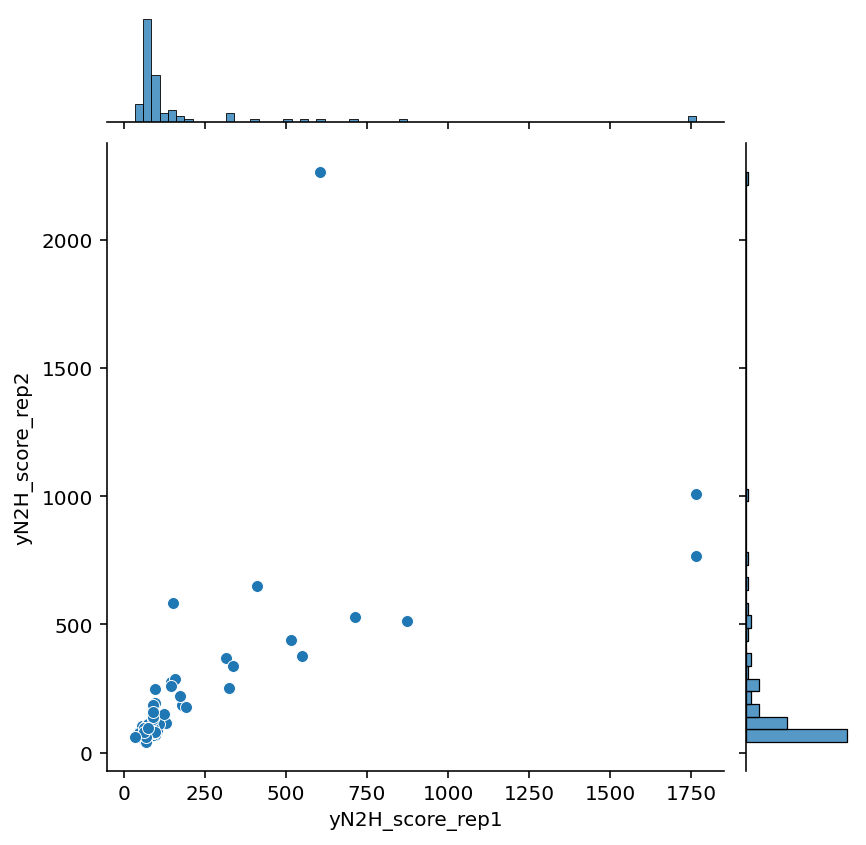

In [12]:
sns.jointplot(data=yN2H_retest[yN2H_retest.variant_id ==  'RRS'], x='yN2H_score_rep1', y='yN2H_score_rep2')

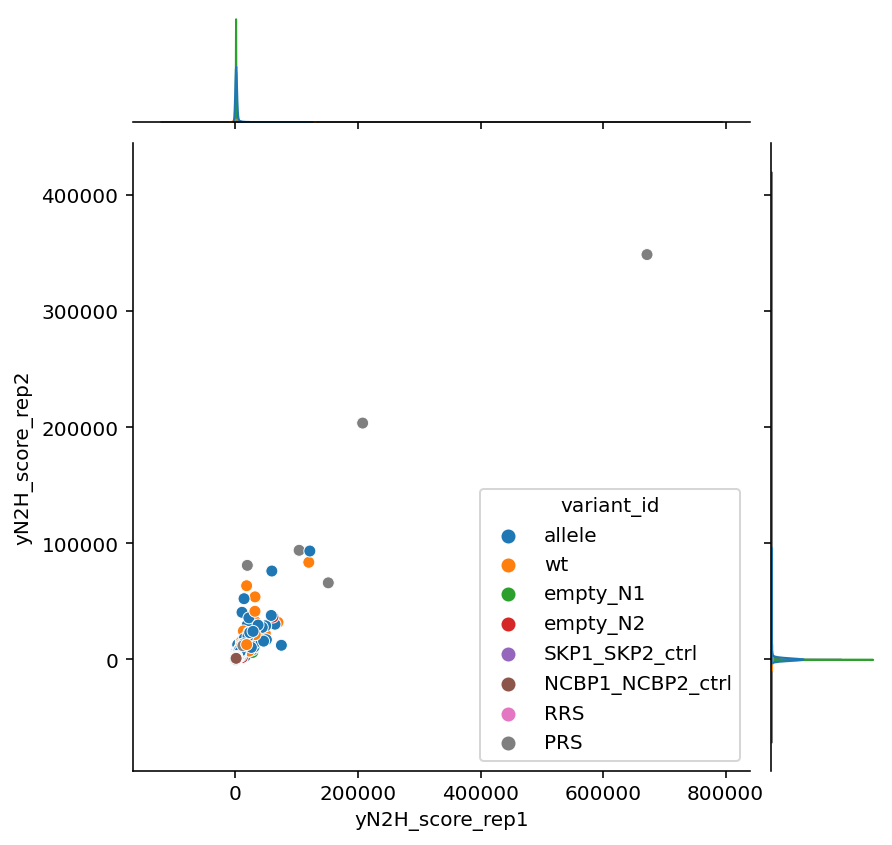

In [13]:
sns.jointplot(data=yN2H_retest, x='yN2H_score_rep1', y='yN2H_score_rep2', hue='variant_id')

In [14]:
np.median(yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep2)

92.5

In [15]:
np.median(yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep1)

82.0

### plate controls

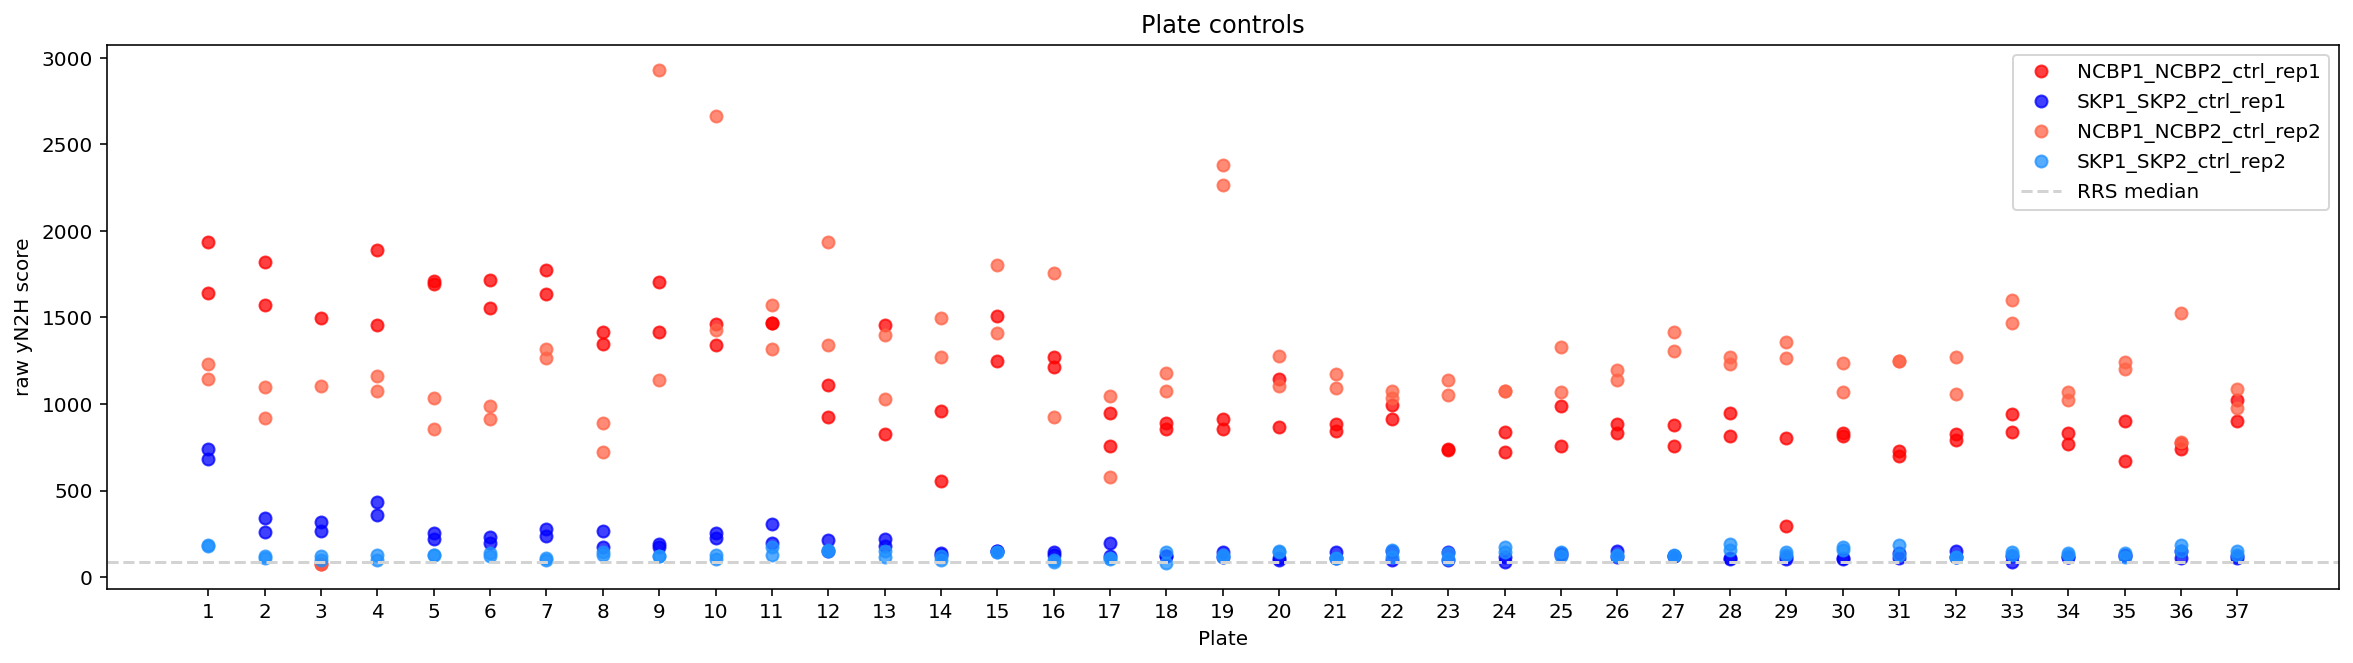

In [16]:
plt.figure(figsize=(20,5))

df = yN2H_retest[yN2H_retest.variant_id.isin(['NCBP1_NCBP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.yN2H_score_rep1.tolist(), 'ro', color='r', label='NCBP1_NCBP2_ctrl_rep1',alpha=0.75)

df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.yN2H_score_rep1.tolist(), 'ro', color='blue', label='SKP1_SKP2_ctrl_rep1',alpha=0.75)

df = yN2H_retest[yN2H_retest.variant_id.isin(['NCBP1_NCBP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.yN2H_score_rep2.tolist(), 'ro', color='tomato', label='NCBP1_NCBP2_ctrl_rep2',alpha=0.75)

df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.yN2H_score_rep2.tolist(), 'ro', color='dodgerblue', label='SKP1_SKP2_ctrl_rep2',alpha=0.75)


plt.title('Plate controls')

plt.xlabel('Plate')

plt.xticks([i for i in range(1,38)])
plt.ylabel('raw yN2H score')

plt.axhline(y=np.mean([np.median(yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep1),
                       np.median(yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep2)]), color='lightgrey', linestyle='--', label='RRS median')
plt.legend()
plt.savefig('control_plate.png',dpi=300, bbox_inches='tight')
plt.show()

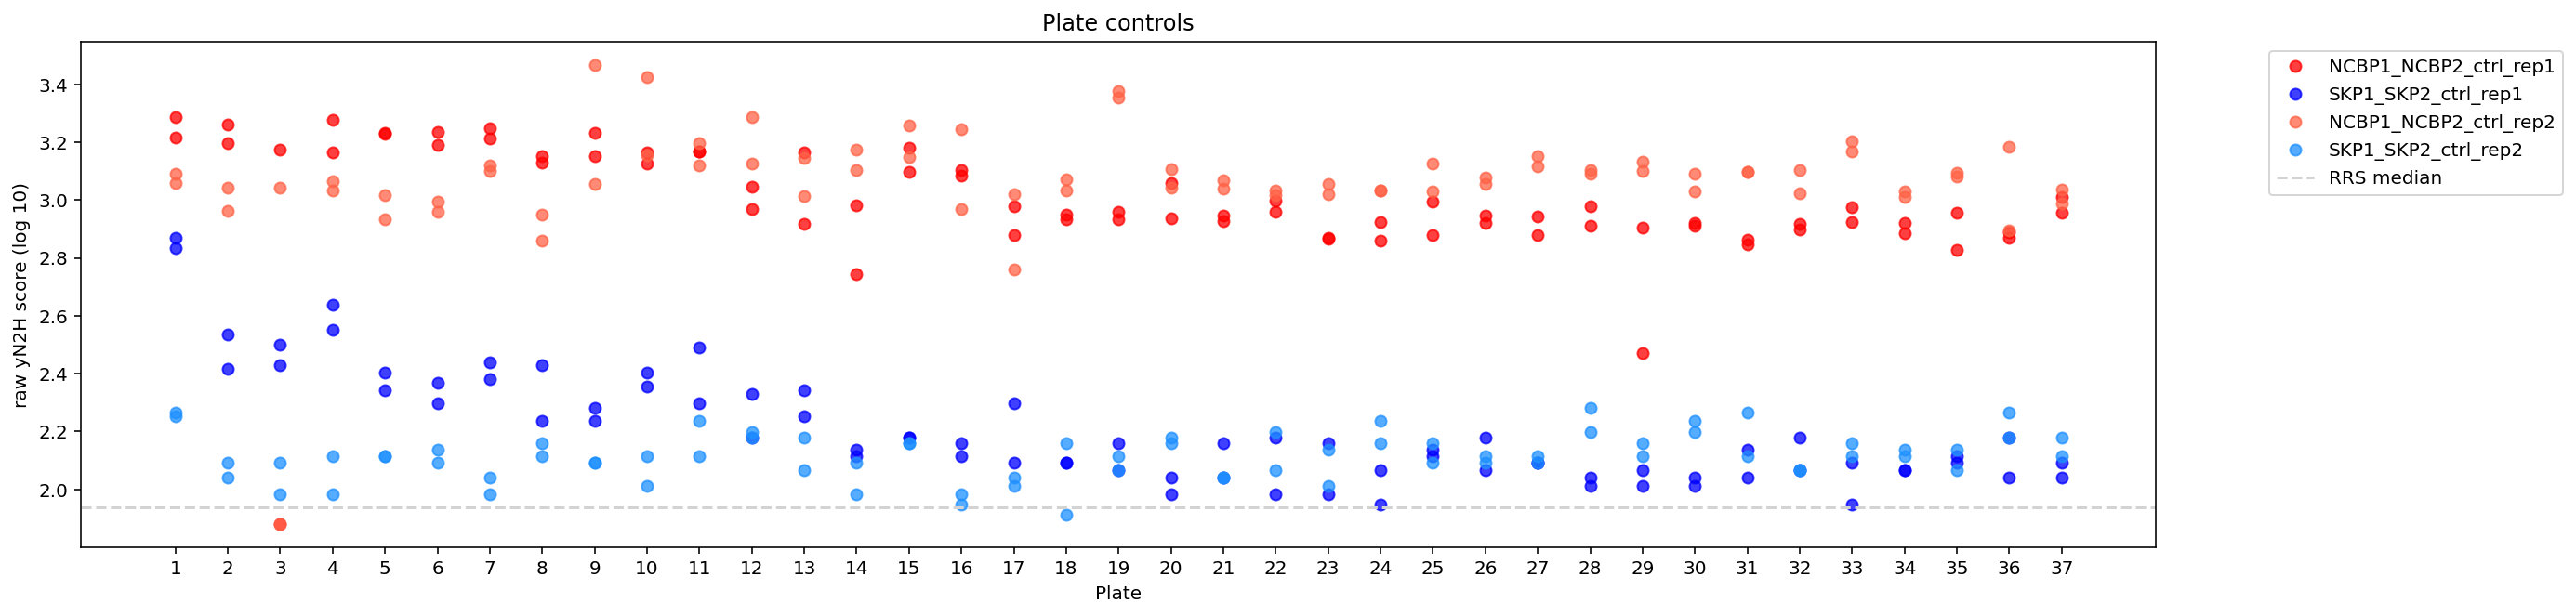

In [17]:
plt.figure(figsize=(20,5))

df = yN2H_retest[yN2H_retest.variant_id.isin(['NCBP1_NCBP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.yN2H_score_rep1.apply(np.log10).tolist(), 'ro', color='r', label='NCBP1_NCBP2_ctrl_rep1',alpha=0.75)

df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.yN2H_score_rep1.apply(np.log10).tolist(), 'ro', color='blue', label='SKP1_SKP2_ctrl_rep1',alpha=0.75)

df = yN2H_retest[yN2H_retest.variant_id.isin(['NCBP1_NCBP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.yN2H_score_rep2.apply(np.log10).tolist(), 'ro', color='tomato', label='NCBP1_NCBP2_ctrl_rep2',alpha=0.75)

df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.yN2H_score_rep2.apply(np.log10).tolist(), 'ro', color='dodgerblue', label='SKP1_SKP2_ctrl_rep2',alpha=0.75)


plt.title('Plate controls')

plt.xlabel('Plate')

plt.xticks([i for i in range(1,38)])
plt.ylabel('raw yN2H score (log 10)')

plt.axhline(y=np.mean([np.median(yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep1.apply(np.log10)),
                       np.median(yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep2.apply(np.log10))]), color='lightgrey', linestyle='--', label='RRS median')
plt.legend(bbox_to_anchor=(1.05, 1))
plt.savefig('control_plate_log10.png',dpi=300, bbox_inches='tight')
plt.show()

### normalize raw data with controls

In [18]:
yN2H_retest.sort_values(by=['retest_pla','retest_pos'], inplace=True)

In [19]:
l = yN2H_retest[yN2H_retest.variant_id.isin(['NCBP1_NCBP2_ctrl'])].yN2H_score_rep1.tolist()
ctrl1_rep1_l = [np.mean([e for e in [l[i],l[i+1]] if e > 300]) for i in range(0,len(l),2)]

l = yN2H_retest[yN2H_retest.variant_id.isin(['NCBP1_NCBP2_ctrl'])].yN2H_score_rep2.tolist()
ctrl1_rep2_l = [np.mean([l[i],l[i+1]]) for i in range(0,len(l),2)]

l = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])].yN2H_score_rep1.tolist()
ctrl2_rep1_l = [np.mean([l[i],l[i+1]]) for i in range(0,len(l),2)]

l = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])].yN2H_score_rep2.tolist()
ctrl2_rep2_l = [np.mean([l[i],l[i+1]]) for i in range(0,len(l),2)]

In [20]:
np.median(ctrl1_rep1_l), np.median(ctrl2_rep1_l),

(889.5, 133.5)

In [21]:
norm_factor_rep1 = []
for (ctrl1,ctrl1_med,ctrl1_norm_f), (ctrl2,ctrl2_med,ctrl2_norm_f) in zip([(e, np.median(ctrl1_rep1_l), np.median(ctrl1_rep1_l)/e) for e in ctrl1_rep1_l],[(e, np.median(ctrl2_rep1_l), np.median(ctrl2_rep1_l)/e) for e in ctrl2_rep1_l]):
    #print((ctrl1,ctrl1_med,ctrl1_norm_f), (ctrl2,ctrl2_med,ctrl2_norm_f))
    norm_factor_rep1.append(np.mean([ctrl1_norm_f,ctrl2_norm_f]))
    
    
norm_factor_rep2 = []
for (ctrl1,ctrl1_med,ctrl1_norm_f), (ctrl2,ctrl2_med,ctrl2_norm_f) in zip([(e, np.median(ctrl1_rep2_l), np.median(ctrl1_rep2_l)/e) for e in ctrl1_rep2_l],[(e, np.median(ctrl2_rep2_l), np.median(ctrl2_rep2_l)/e) for e in ctrl2_rep2_l]):
    #print((ctrl1,ctrl1_med,ctrl1_norm_f), (ctrl2,ctrl2_med,ctrl2_norm_f))
    norm_factor_rep2.append(np.mean([ctrl1_norm_f,ctrl2_norm_f]))

norm_factor_rep1_d = {i+1:norm_factor_rep1[i] for i in range(len(norm_factor_rep1))}
norm_factor_rep2_d = {i+1:norm_factor_rep2[i] for i in range(len(norm_factor_rep2))}

In [22]:
#yN2H_retest['NC_yN2H_rep1'] = [norm_factor_rep1_d[pla]*score for pla, score in zip(yN2H_retest.retest_pla, yN2H_retest.yN2H_score_rep1)]
#yN2H_retest['NC_yN2H_rep2'] = [norm_factor_rep2_d[pla]*score for pla, score in zip(yN2H_retest.retest_pla, yN2H_retest.yN2H_score_rep2)]
#yN2H_retest.head()

In [23]:
yN2H_retest.variant_id.value_counts()

allele              1786
empty_N1             731
empty_N2             336
wt                   239
RRS                   78
NCBP1_NCBP2_ctrl      74
SKP1_SKP2_ctrl        74
PRS                   60
Name: variant_id, dtype: int64

In [24]:
yN2H_retest[(yN2H_retest.retest_pla == 1)&(yN2H_retest.variant_id == 'SKP1_SKP2_ctrl')].yN2H_score_rep1

314    680
308    742
Name: yN2H_score_rep1, dtype: int64

In [25]:
# for i in range(1,38):
#     print(i)
#     s = pd.Series([abs(r1-r2)/r1 for r1,r2 in zip(yN2H_retest[(yN2H_retest.retest_pla == i)].yN2H_score_rep1,  yN2H_retest[(yN2H_retest.retest_pla == i)].yN2H_score_rep2)])
#     s.plot.hist(bins=20)
    
#     s2 = pd.Series([(r1,r2, abs(r1-r2)/r1) for r1,r2 in zip(yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id == 'SKP1_SKP2_ctrl')].yN2H_score_rep1,  yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id == 'SKP1_SKP2_ctrl')].yN2H_score_rep2)])
#     s3 = pd.Series([(r1,r2, abs(r1-r2)/r1) for r1,r2 in zip(yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id == 'NCBP1_NCBP2_ctrl')].yN2H_score_rep1,  yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id == 'NCBP1_NCBP2_ctrl')].yN2H_score_rep2)])
#     print('mean: ', s.mean(), '\nSKP1 SKP2 mean', s2.apply(lambda x: x[-1]).mean(), '\nNCBP1 NCBP2 mean', s3.apply(lambda x: x[-1]).mean())
#     print(norm_factor_rep1_d[i])
#     plt.plot([np.mean([e[-1] for e in s2])], [1], 'ro')
#     plt.plot([np.mean([e[-1] for e in s3])], [1], 'ro', color='yellow')
    
#     plt.show()

In [26]:
# for i in range(1,38):
#     print(i)
#     s = pd.Series([r1/r2 for r1,r2 in zip(yN2H_retest[(yN2H_retest.retest_pla == i)].yN2H_score_rep1,  yN2H_retest[(yN2H_retest.retest_pla == i)].yN2H_score_rep2)])
#     s.plot.hist(bins=20)
    
#     s2 = pd.Series([r1/r2 for r1,r2 in zip(yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id == 'SKP1_SKP2_ctrl')].yN2H_score_rep1,  yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id == 'SKP1_SKP2_ctrl')].yN2H_score_rep2)])
#     s3 = pd.Series([r1/r2 for r1,r2 in zip(yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id == 'NCBP1_NCBP2_ctrl')].yN2H_score_rep1,  yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id == 'NCBP1_NCBP2_ctrl')].yN2H_score_rep2)])
#     print('mean: ', s.mean(), '\nSKP1 SKP2 mean', s2.mean(), '\nNCBP1 NCBP2 mean', s3.mean())
    
#     plt.plot(s2.mean(), 1, 'ro')
#     plt.plot(s3.mean(), 1, 'ro', color='yellow')
    
#     plt.show()

1
mean:  1.262888686208915 
SKP1 SKP2 mean 3.9048467461875283 
NCBP1 NCBP2 mean 1.502976597952844


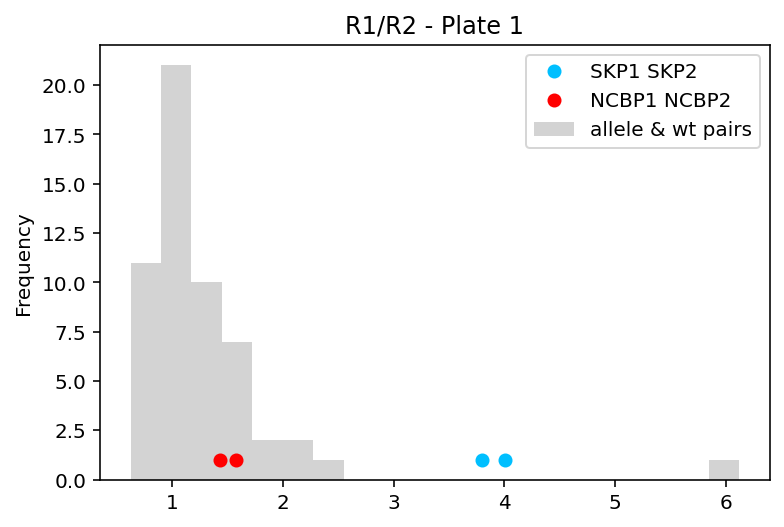

2
mean:  1.421518134290273 
SKP1 SKP2 mean 2.5694281524926685 
NCBP1 NCBP2 mean 1.7047810262293783


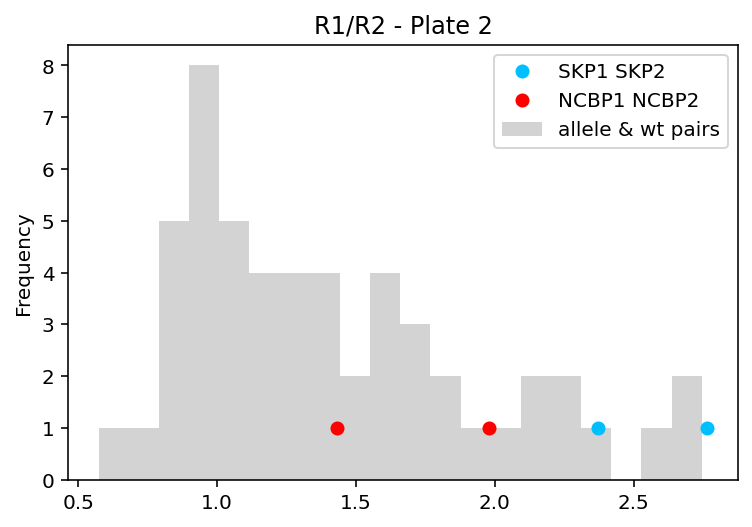

3
mean:  1.4851401993448488 
SKP1 SKP2 mean 2.726478494623656 
NCBP1 NCBP2 mean 1.176763110307414


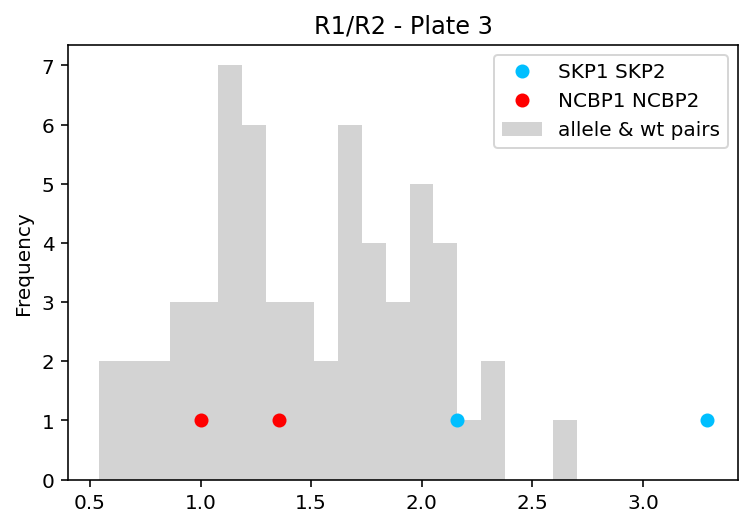

4
mean:  2.156953459130268 
SKP1 SKP2 mean 3.5247596153846157 
NCBP1 NCBP2 mean 1.4884168372540465


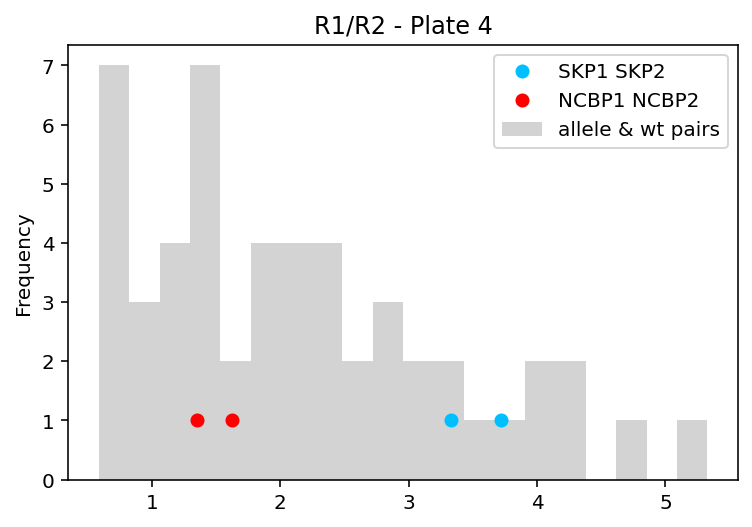

5
mean:  1.7195202737518778 
SKP1 SKP2 mean 1.823076923076923 
NCBP1 NCBP2 mean 1.8142469873424552


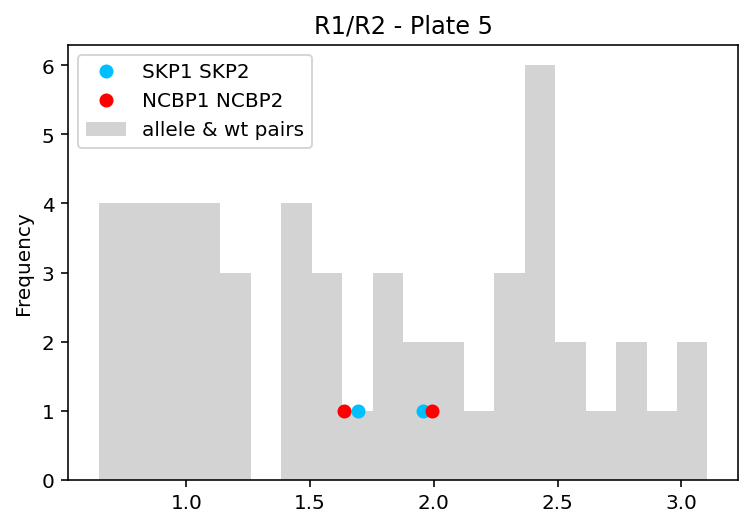

6
mean:  1.5537514017813974 
SKP1 SKP2 mean 1.6527843183423592 
NCBP1 NCBP2 mean 1.7179937693600027


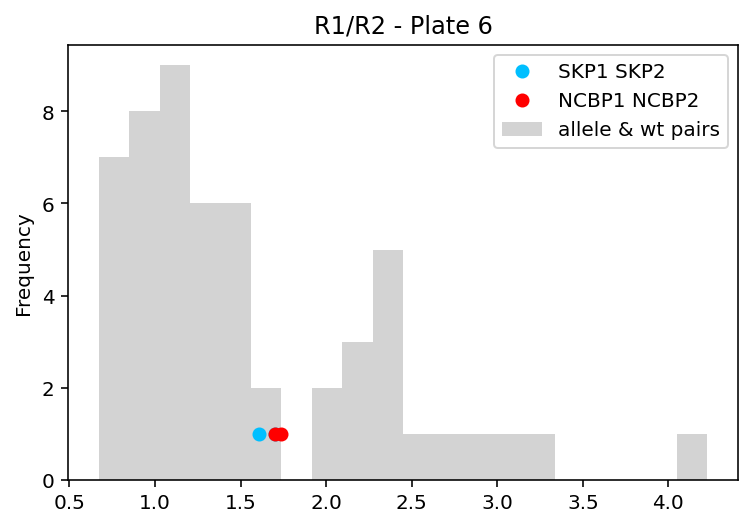

7
mean:  1.3680552061241726 
SKP1 SKP2 mean 2.5 
NCBP1 NCBP2 mean 1.3208279710339794


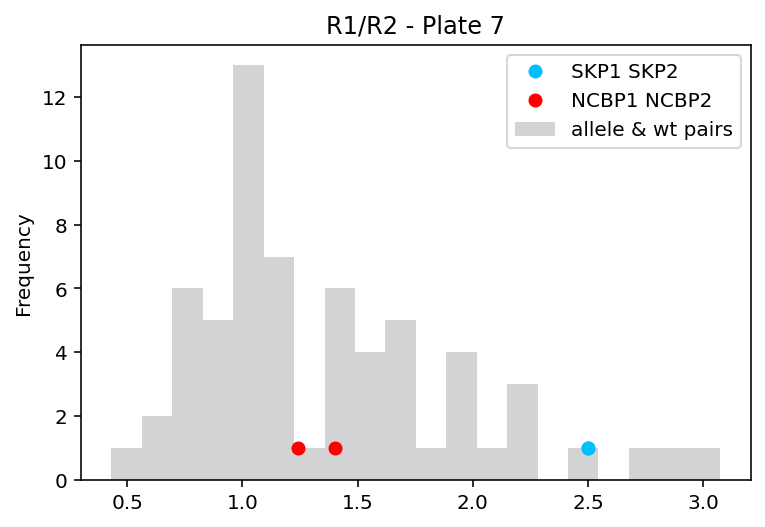

8
mean:  1.1394619827364505 
SKP1 SKP2 mean 1.627991452991453 
NCBP1 NCBP2 mean 1.7256990337856624


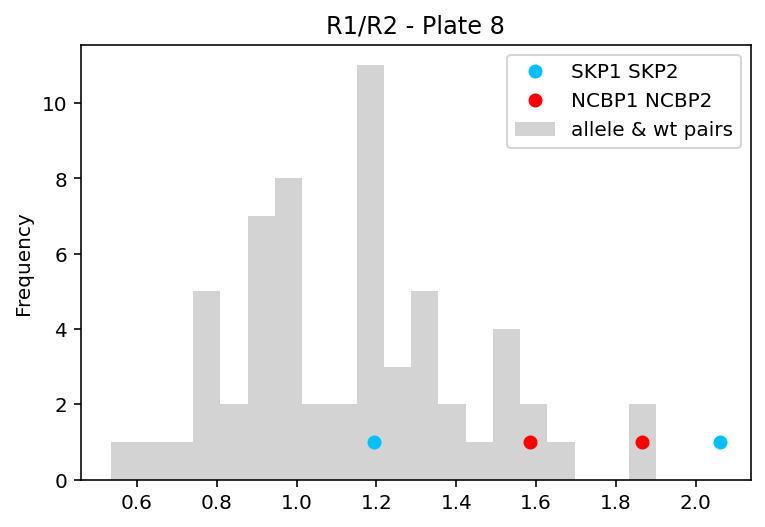

9
mean:  0.9636623464558306 
SKP1 SKP2 mean 1.467741935483871 
NCBP1 NCBP2 mean 0.9110301333141859


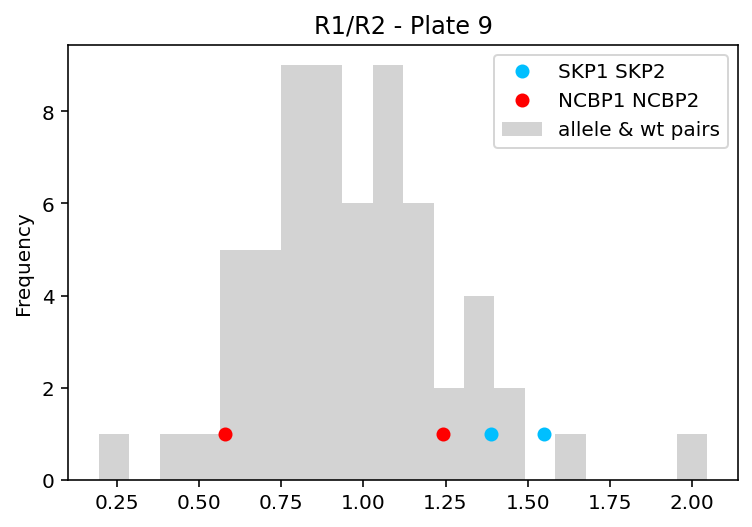

10
mean:  1.151748194248879 
SKP1 SKP2 mean 2.106086631814787 
NCBP1 NCBP2 mean 0.7434246221010927


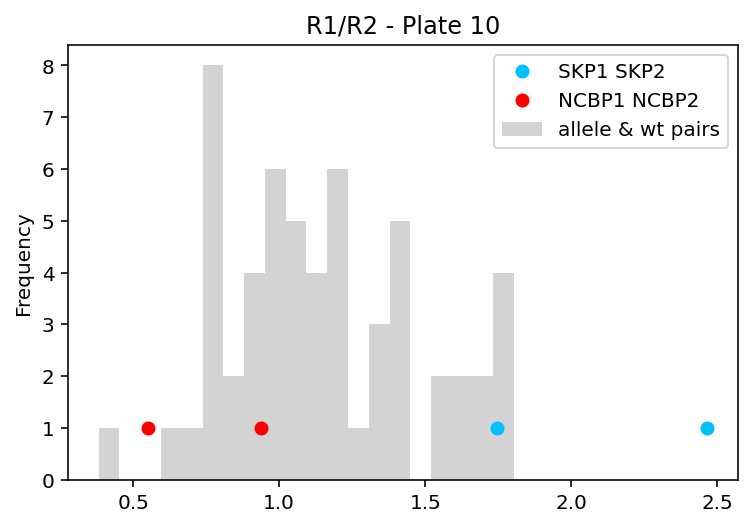

11
mean:  1.2933346108445556 
SKP1 SKP2 mean 1.6636404293381037 
NCBP1 NCBP2 mean 1.024923138662965


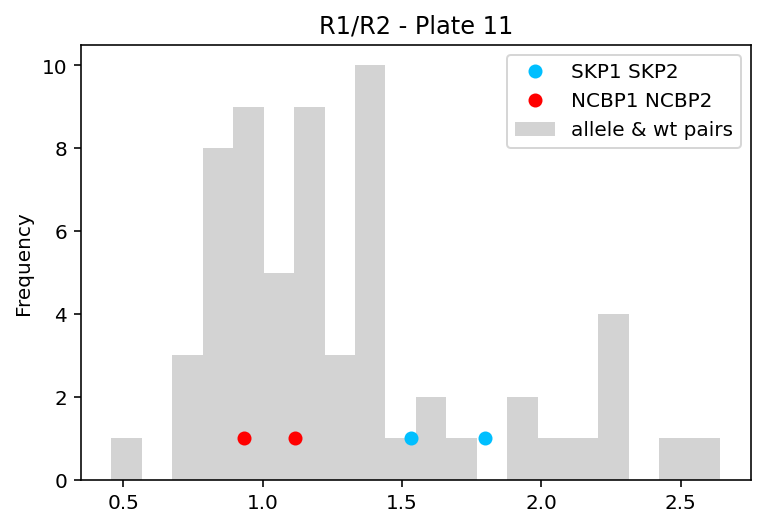

12
mean:  0.9015417944531289 
SKP1 SKP2 mean 1.183146114510856 
NCBP1 NCBP2 mean 0.6333439287984742


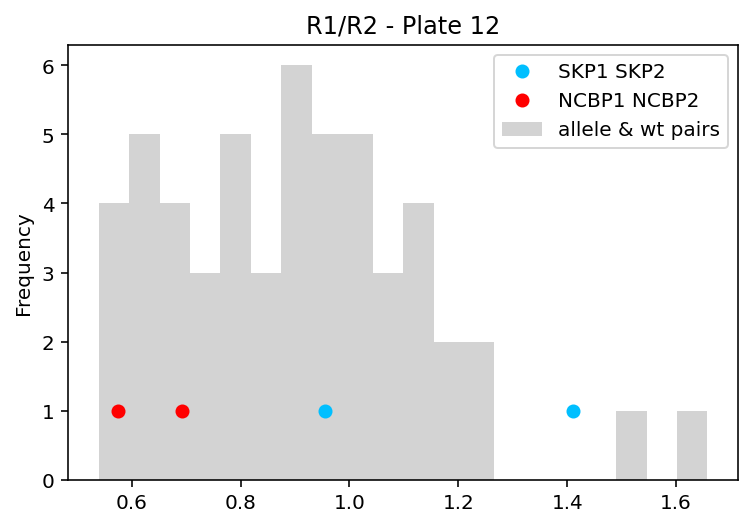

13
mean:  1.0430006176616242 
SKP1 SKP2 mean 1.4934340861493178 
NCBP1 NCBP2 mean 0.9196288365453248


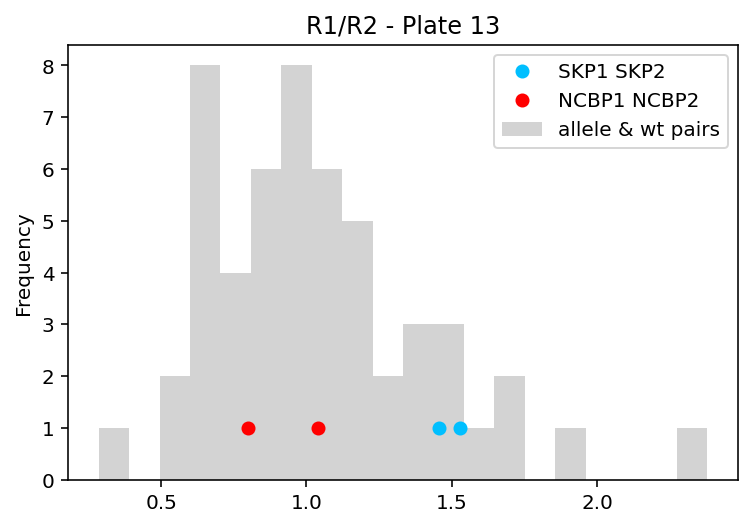

14
mean:  0.8848187528293312 
SKP1 SKP2 mean 1.229502688172043 
NCBP1 NCBP2 mean 0.5398729216964112


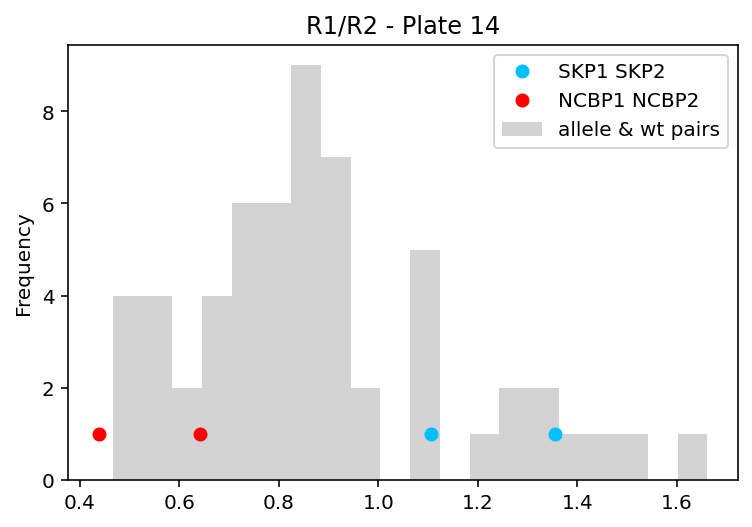

15
mean:  0.8950297505735285 
SKP1 SKP2 mean 1.0486111111111112 
NCBP1 NCBP2 mean 0.8622198416893184


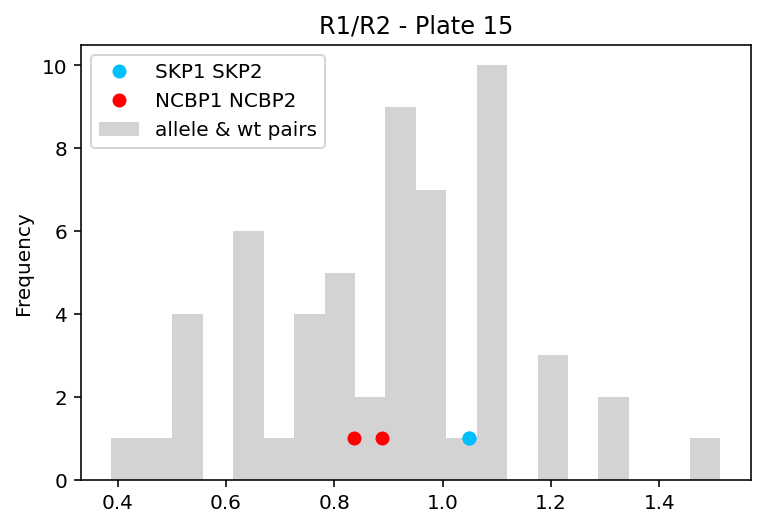

16
mean:  1.2258329247701332 
SKP1 SKP2 mean 1.4803370786516854 
NCBP1 NCBP2 mean 1.016545721638667


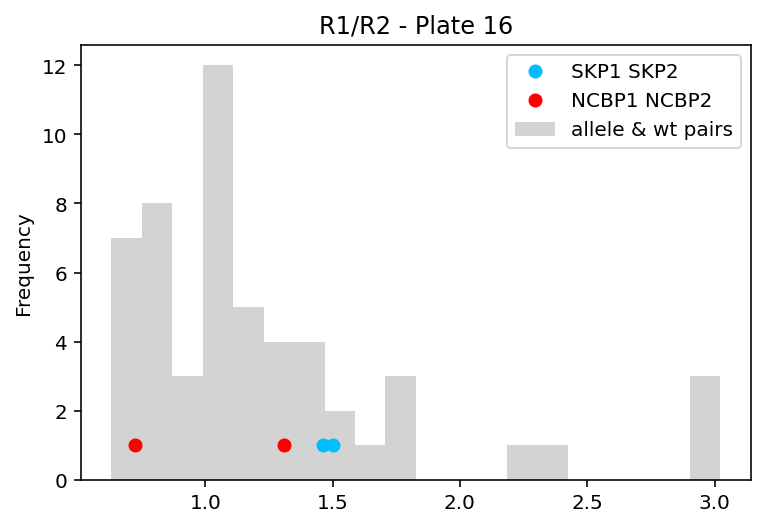

17
mean:  1.0497660970894471 
SKP1 SKP2 mean 1.50648720211827 
NCBP1 NCBP2 mean 1.108269089025678


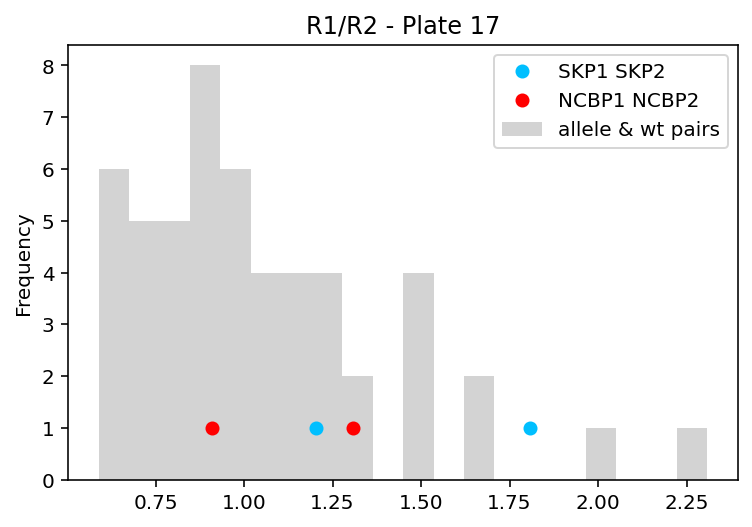

18
mean:  0.7787816720697149 
SKP1 SKP2 mean 1.1866531165311653 
NCBP1 NCBP2 mean 0.7774444317023246


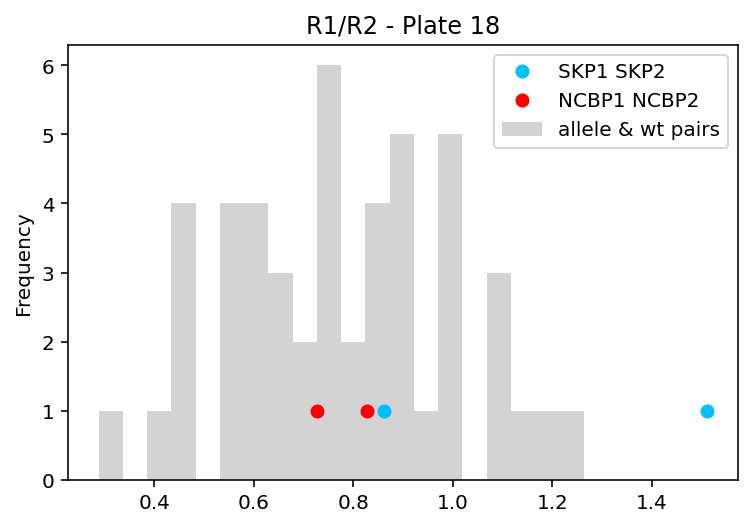

19
mean:  0.8855091703536379 
SKP1 SKP2 mean 1.0653846153846154 
NCBP1 NCBP2 mean 0.3814814890262336


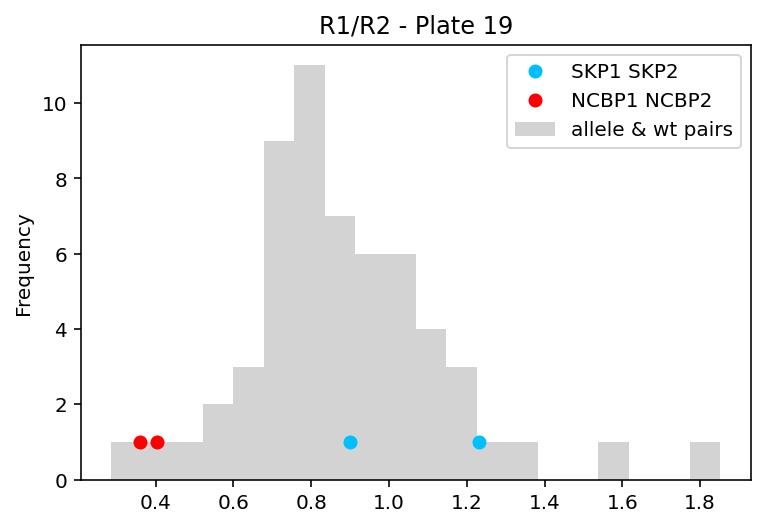

20
mean:  0.7684456986179241 
SKP1 SKP2 mean 0.6975717439293598 
NCBP1 NCBP2 mean 0.840148276433379


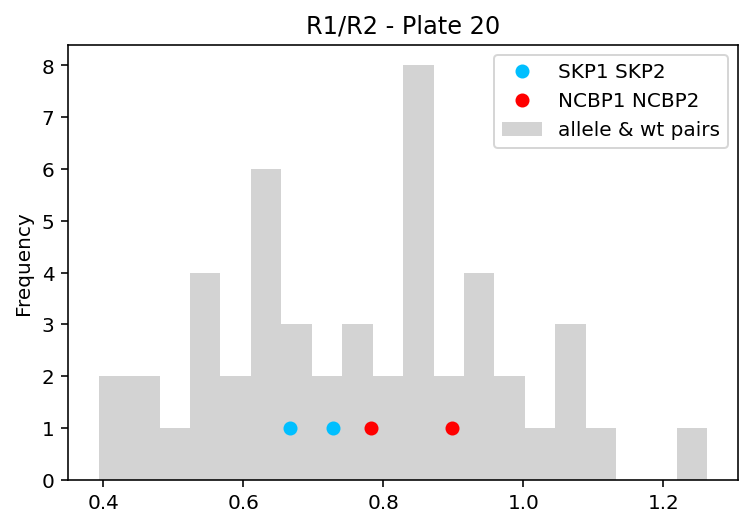

21
mean:  0.7359099476429335 
SKP1 SKP2 mean 1.1545454545454545 
NCBP1 NCBP2 mean 0.7642471809848301


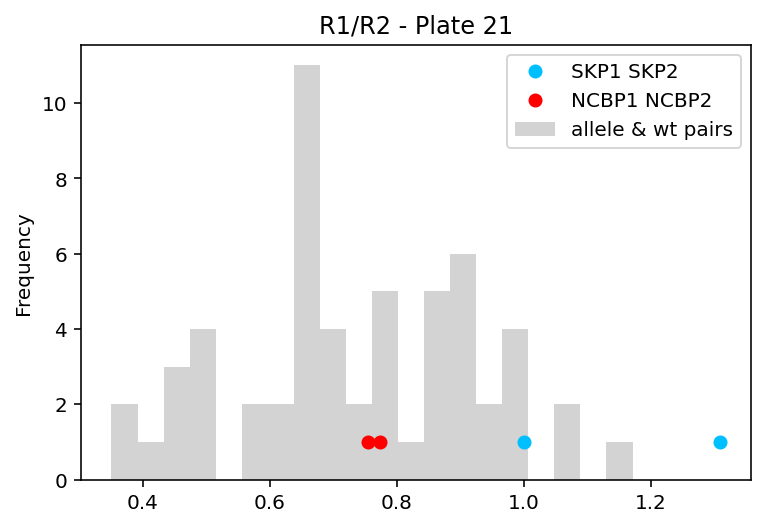

22
mean:  0.9305985994932375 
SKP1 SKP2 mean 0.888104511522233 
NCBP1 NCBP2 mean 0.9021787552576918


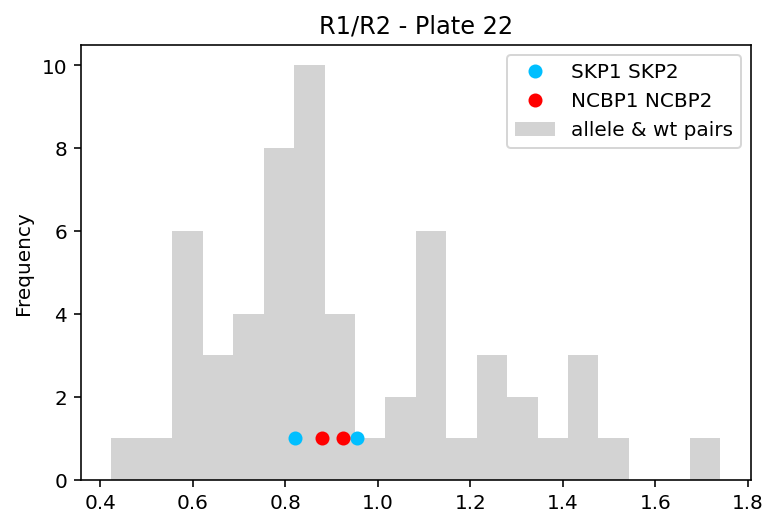

23
mean:  0.9520294961765337 
SKP1 SKP2 mean 1.049394089717242 
NCBP1 NCBP2 mean 0.6753655666282739


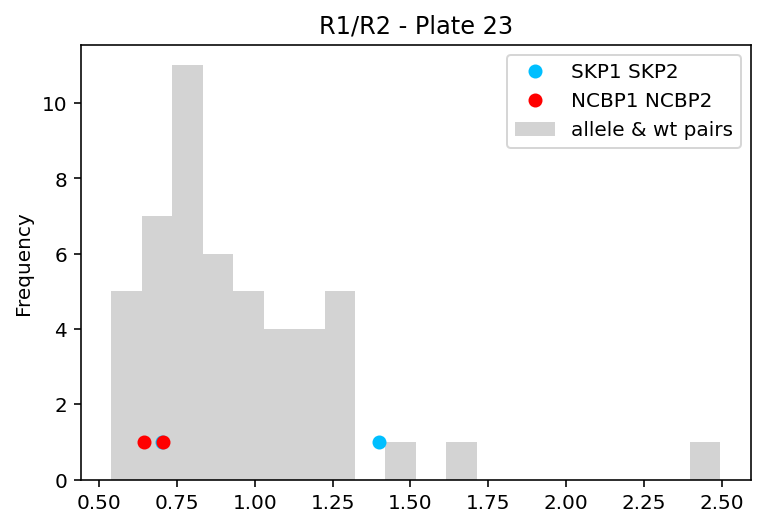

24
mean:  0.8443127948918432 
SKP1 SKP2 mean 0.6649709302325582 
NCBP1 NCBP2 mean 0.7230983302411873


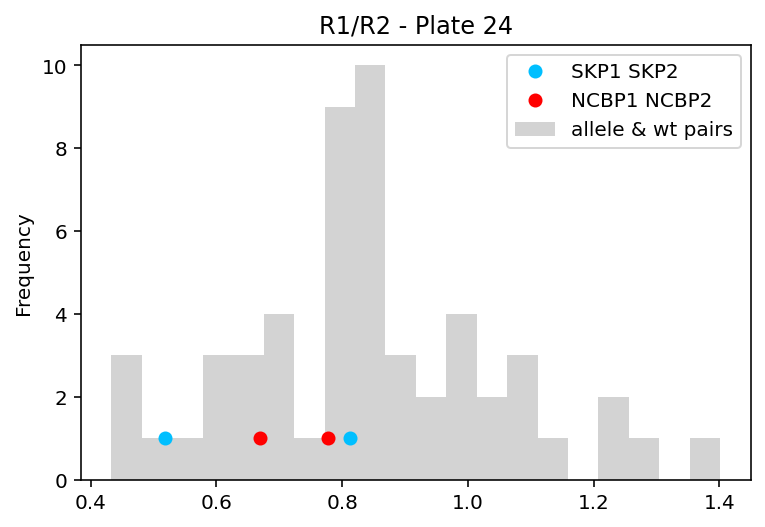

25
mean:  0.8178640341975123 
SKP1 SKP2 mean 1.0038082437275986 
NCBP1 NCBP2 mean 0.7237205693088047


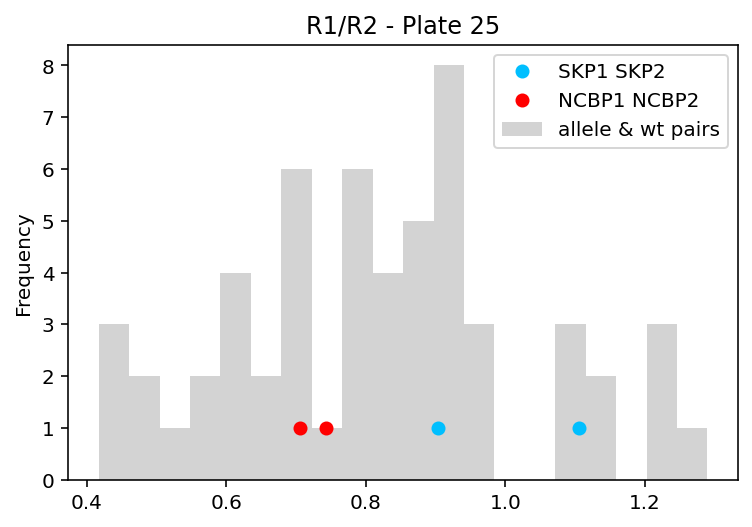

26
mean:  0.8109133978312758 
SKP1 SKP2 mean 1.0588709677419355 
NCBP1 NCBP2 mean 0.735184981281656


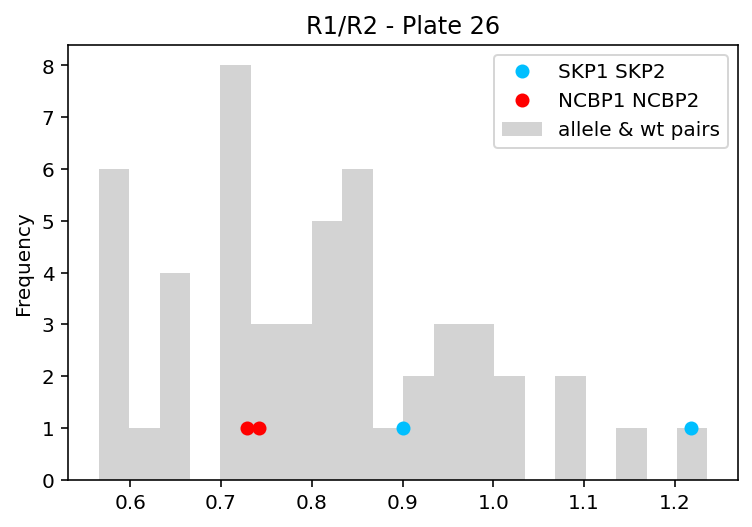

27
mean:  0.840530907817884 
SKP1 SKP2 mean 0.976923076923077 
NCBP1 NCBP2 mean 0.5998727373651219


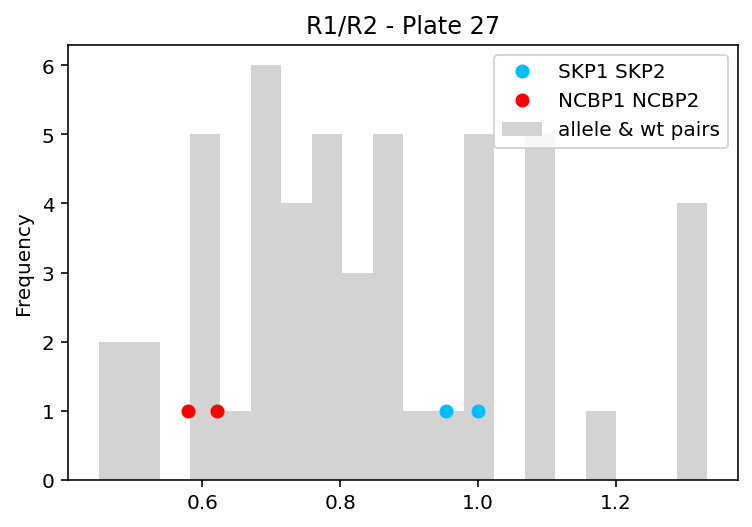

28
mean:  0.7253603137732721 
SKP1 SKP2 mean 0.6163304324894515 
NCBP1 NCBP2 mean 0.7056123985315506


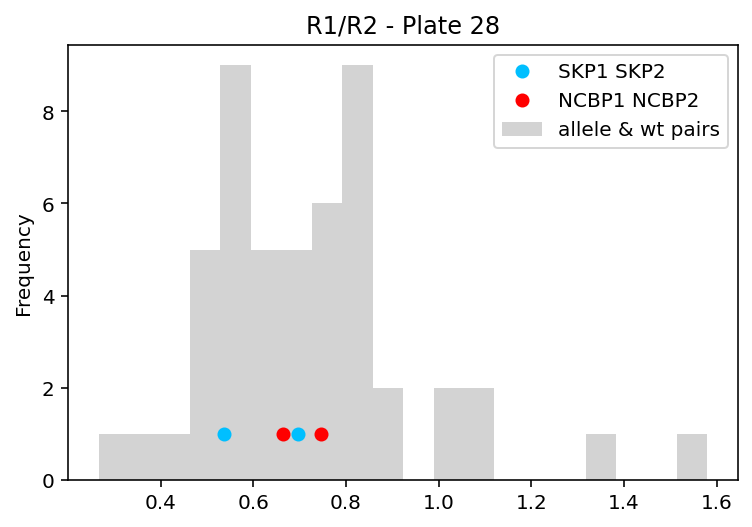

29
mean:  0.6868088537842313 
SKP1 SKP2 mean 0.8076388888888889 
NCBP1 NCBP2 mean 0.42609828741623235


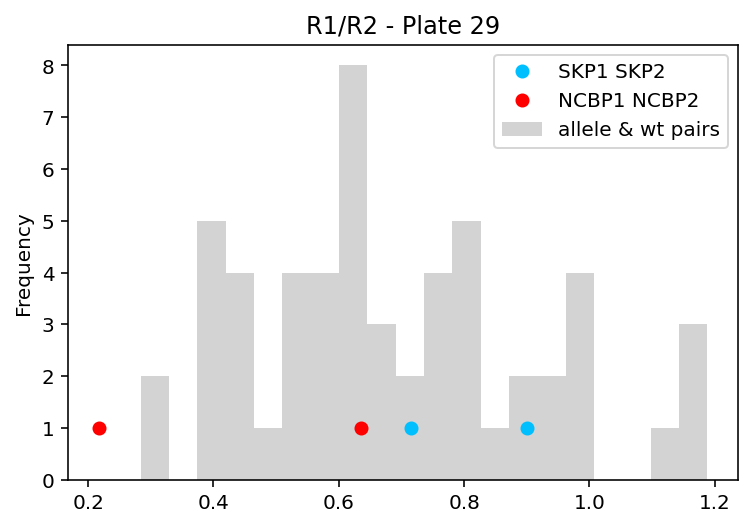

30
mean:  0.6233184420145963 
SKP1 SKP2 mean 0.6475198704739475 
NCBP1 NCBP2 mean 0.7175842829041001


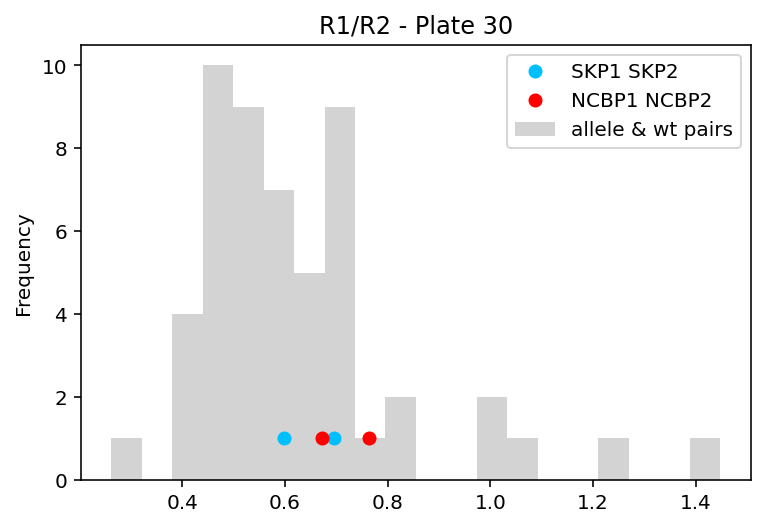

31
mean:  0.6990313579662968 
SKP1 SKP2 mean 0.8242203742203742 
NCBP1 NCBP2 mean 0.5712


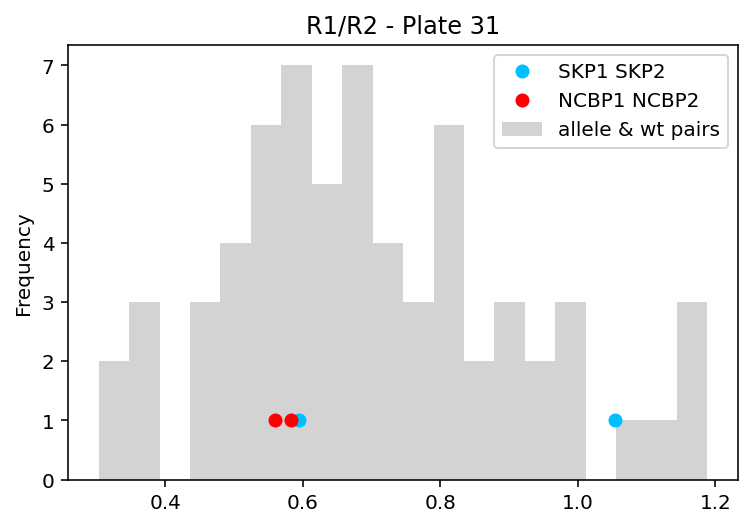

32
mean:  0.71403477221142 
SKP1 SKP2 mean 1.1452991452991452 
NCBP1 NCBP2 mean 0.697755384546686


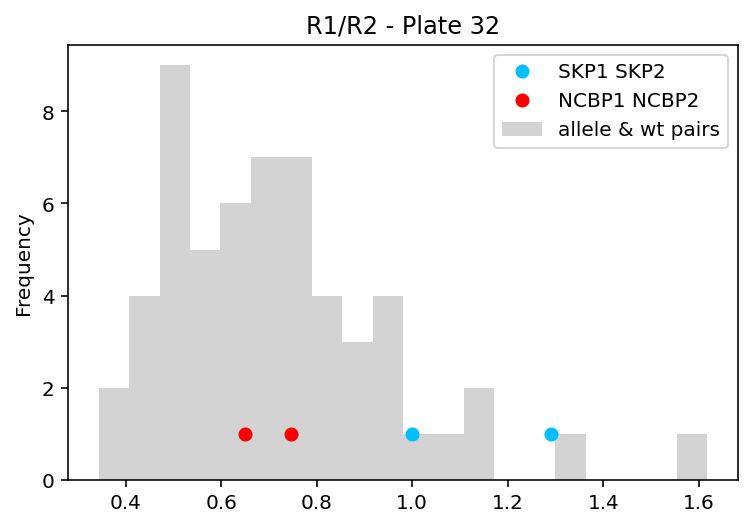

33
mean:  0.6525501335716567 
SKP1 SKP2 mean 0.7728632478632479 
NCBP1 NCBP2 mean 0.5790965136054422


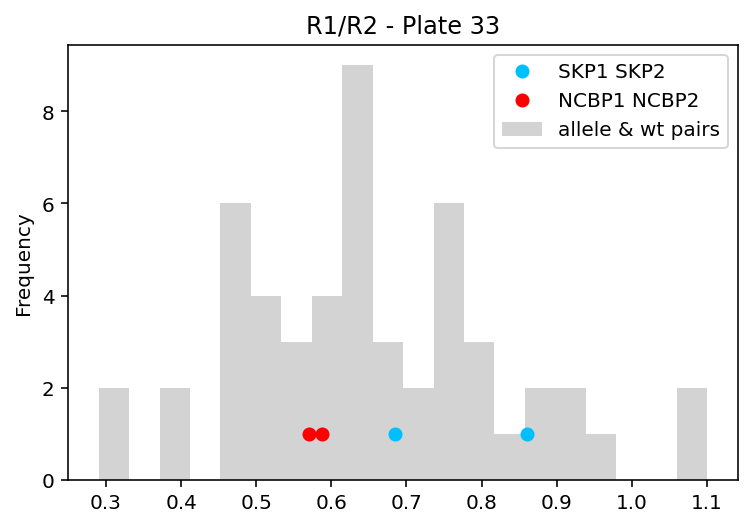

34
mean:  0.937682669470893 
SKP1 SKP2 mean 0.877007299270073 
NCBP1 NCBP2 mean 0.7638105095410599


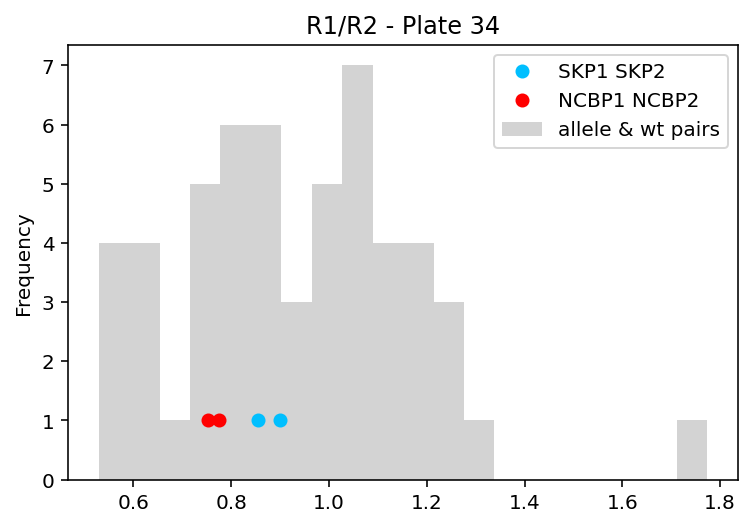

35
mean:  0.8219196247726983 
SKP1 SKP2 mean 1.008110300081103 
NCBP1 NCBP2 mean 0.645092049587507


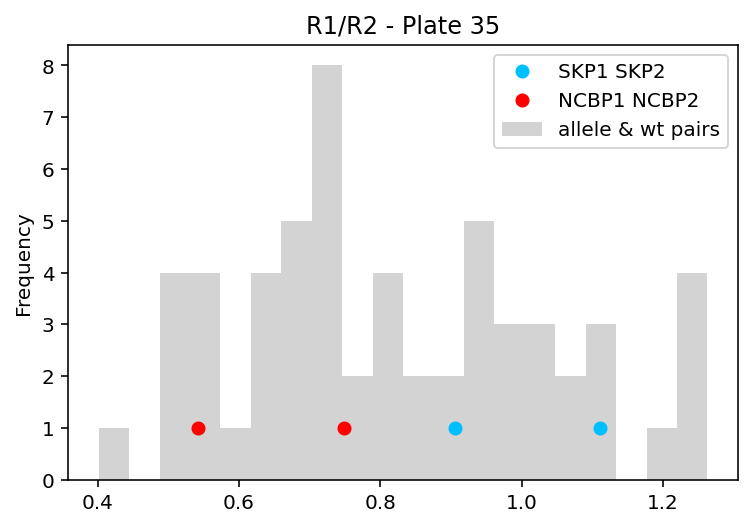

36
mean:  0.8461589448005054 
SKP1 SKP2 mean 0.7723465187041345 
NCBP1 NCBP2 mean 0.7284118220854577


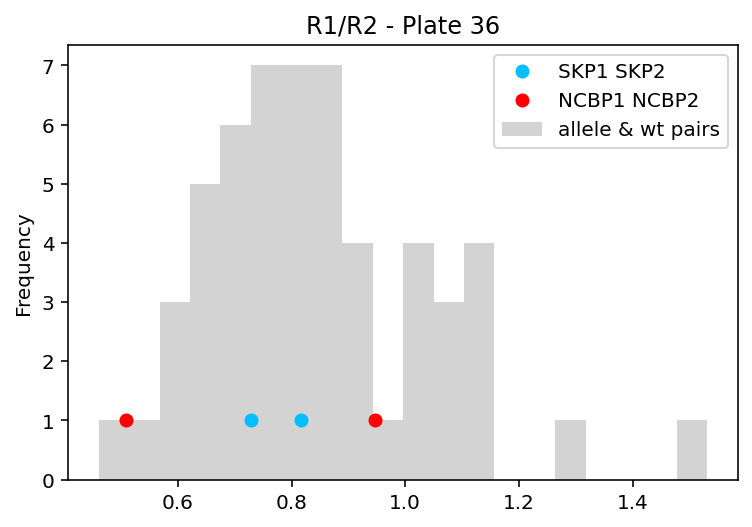

37
mean:  0.9479704772208459 
SKP1 SKP2 mean 0.8411614875191034 
NCBP1 NCBP2 mean 0.9393619283941864


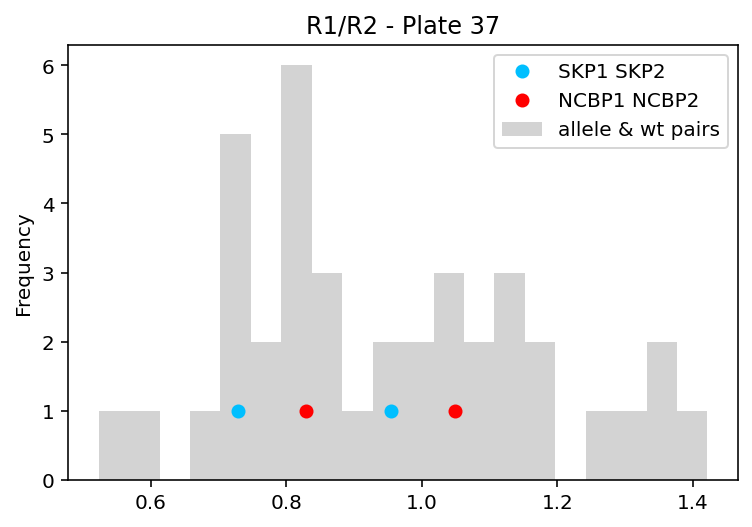

In [27]:
for i in range(1,38):
    print(i)
    s = pd.Series([r1/r2 for r1,r2 in zip(yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id.isin(['allele','wt']))].yN2H_score_rep1,  
                                          yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id.isin(['allele','wt']))].yN2H_score_rep2)])
    s.plot.hist(bins=20, label='allele & wt pairs', color='lightgrey')
    
    s2 = pd.Series([r1/r2 for r1,r2 in zip(yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id == 'SKP1_SKP2_ctrl')].yN2H_score_rep1,  yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id == 'SKP1_SKP2_ctrl')].yN2H_score_rep2)])
    s3 = pd.Series([r1/r2 for r1,r2 in zip(yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id == 'NCBP1_NCBP2_ctrl')].yN2H_score_rep1,  yN2H_retest[(yN2H_retest.retest_pla == i)&(yN2H_retest.variant_id == 'NCBP1_NCBP2_ctrl')].yN2H_score_rep2)])
    print('mean: ', s.mean(), '\nSKP1 SKP2 mean', s2.mean(), '\nNCBP1 NCBP2 mean', s3.mean())
    
    plt.plot(s2, [1,1], 'ro', color = 'deepskyblue',label='SKP1 SKP2')
    plt.plot(s3, [1,1], 'ro', color='red', label='NCBP1 NCBP2')
    plt.title(f'R1/R2 - Plate {i}')
    plt.legend()
    
    plt.show()

pearson (0.9584610189854668, 0.0)
spearman SpearmanrResult(correlation=0.9187015533873244, pvalue=0.0)


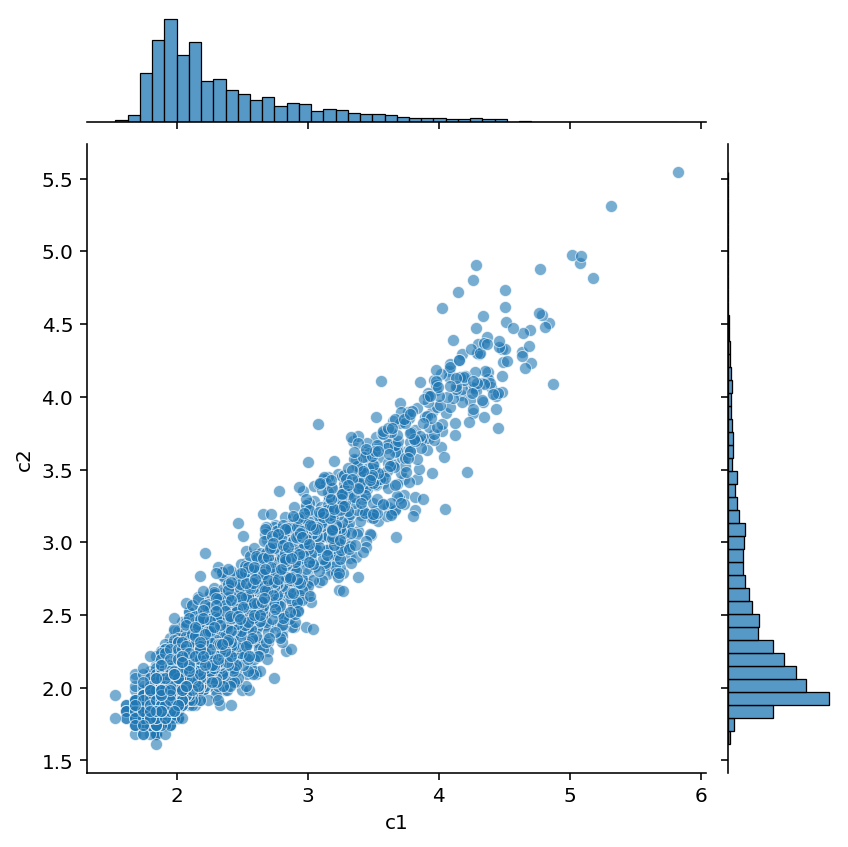

In [28]:
data1 = yN2H_retest.yN2H_score_rep1.apply(np.log10)
data2 = yN2H_retest.yN2H_score_rep2.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = yN2H_retest.copy()

df['c1'] = df.yN2H_score_rep1.apply(np.log10)
df['c2'] = df.yN2H_score_rep2.apply(np.log10)

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6)

In [29]:
yN2H_retest.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2
309,1611,SPERT,2713,MLH1,889.0,1,A01,yN2Hapwt,allele,192,165
307,11130,SLC35E3,4062,PLP1,201426.0,1,A02,yN2Hapwt,allele,2026,1277
299,0,None,9970,PHYKPL,0.0,1,A03,yN2Hapwt,empty_N1,700,522
291,0,None,3156,PCNA,NaN,1,A04,yN2Hapwt,empty_N1,3770,2541
283,7515,XRCC4,9905,PNKP,216952.0,1,A05,yN2Hapwt,allele,5405,2726


pearson (0.9584610189854668, 0.0)
spearman SpearmanrResult(correlation=0.9187015533873244, pvalue=0.0)


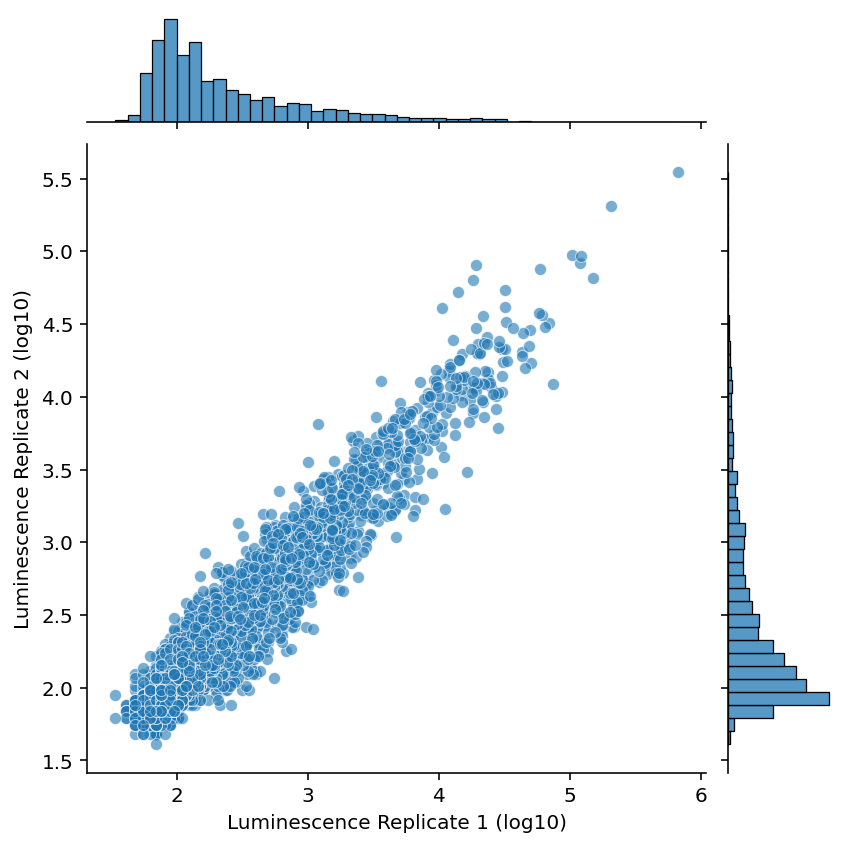

In [30]:
data1 = yN2H_retest.yN2H_score_rep1.apply(np.log10)
data2 = yN2H_retest.yN2H_score_rep2.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = yN2H_retest.copy()

df['Luminescence Replicate 1 (log10)'] = df.yN2H_score_rep1.apply(np.log10)
df['Luminescence Replicate 2 (log10)'] = df.yN2H_score_rep2.apply(np.log10)

sns.jointplot(data=df, x='Luminescence Replicate 1 (log10)', y='Luminescence Replicate 2 (log10)',alpha=0.6)


pearson (0.9642545982401239, 0.0)
spearman SpearmanrResult(correlation=0.9389468746985934, pvalue=0.0)


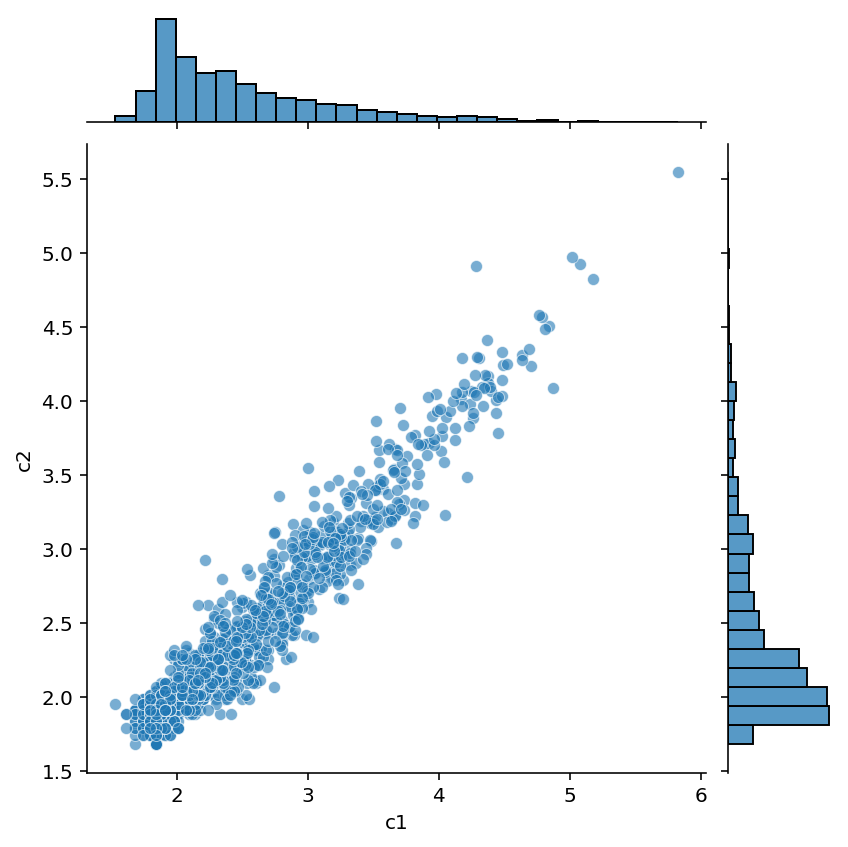

In [31]:
data1 = yN2H_retest[yN2H_retest.retest_pla < 15].yN2H_score_rep1.apply(np.log10)
data2 = yN2H_retest[yN2H_retest.retest_pla < 15].yN2H_score_rep2.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = yN2H_retest[yN2H_retest.retest_pla < 15].copy()

df['c1'] = df.yN2H_score_rep1.apply(np.log10)
df['c2'] = df.yN2H_score_rep2.apply(np.log10)

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6)

pearson (0.9704222475773903, 0.0)
spearman SpearmanrResult(correlation=0.9228222477539197, pvalue=0.0)


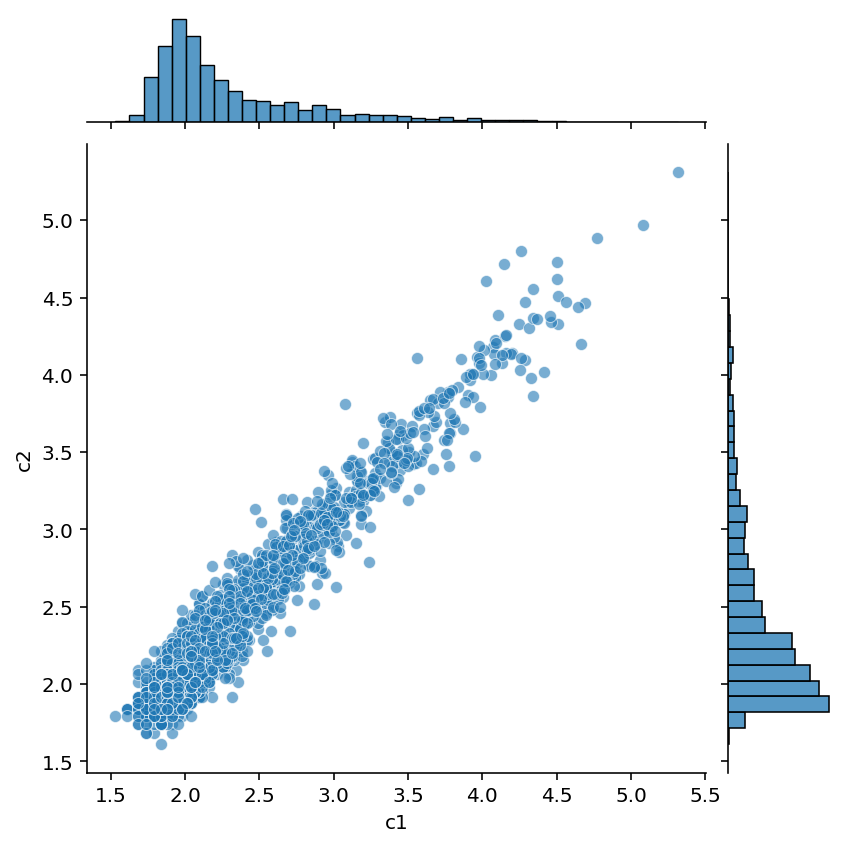

In [32]:
data1 = yN2H_retest[yN2H_retest.retest_pla > 15].yN2H_score_rep1.apply(np.log10)
data2 = yN2H_retest[yN2H_retest.retest_pla > 15].yN2H_score_rep2.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = yN2H_retest[yN2H_retest.retest_pla > 15].copy()

df['c1'] = df.yN2H_score_rep1.apply(np.log10)
df['c2'] = df.yN2H_score_rep2.apply(np.log10)

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6)

pearson (1.0, 0.0)
spearman SpearmanrResult(correlation=1.0, pvalue=0.0)


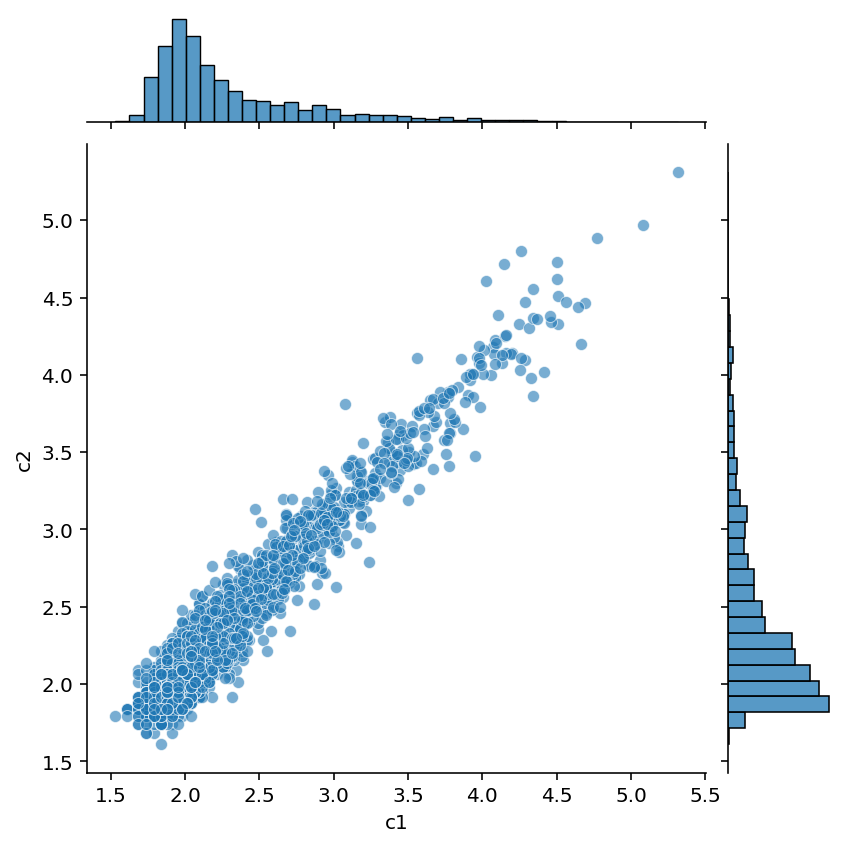

In [33]:
data1 = yN2H_retest[yN2H_retest.retest_pla > 15].yN2H_score_rep1.apply(np.log10)
data2 = yN2H_retest[yN2H_retest.retest_pla > 15].yN2H_score_rep1.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = yN2H_retest[yN2H_retest.retest_pla > 15].copy()

df['c1'] = df.yN2H_score_rep1.apply(np.log10)
df['c2'] = df.yN2H_score_rep2.apply(np.log10)

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6)

0.7262694443537059
-0.019701022416200198
pearson (0.9861143192970818, 5.692003837360136e-72)
spearman SpearmanrResult(correlation=0.9597312457131958, pvalue=2.0581230063206008e-51)


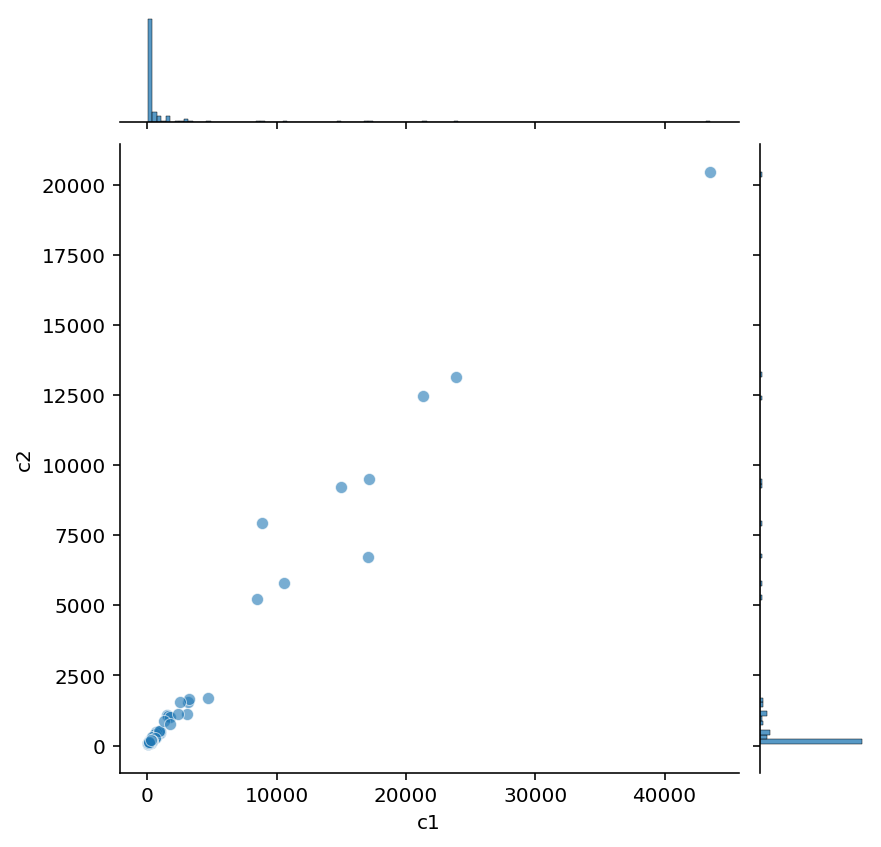

In [34]:
data1 = yN2H_retest[yN2H_retest.retest_pla == 3].yN2H_score_rep1
data2 = yN2H_retest[yN2H_retest.retest_pla == 3].yN2H_score_rep2

print(r2_score(data1, data2))
print(r2_score(data2, data1))

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = yN2H_retest[yN2H_retest.retest_pla == 3].copy()

df['c1'] = df.yN2H_score_rep1
df['c2'] = df.yN2H_score_rep2

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6)

In [35]:
y_true = [3, -0.5, 2, 7]
y_pred = [2.5, 0.0, 2, 8]
r2_score(y_pred, y_true)

0.9573712255772646

0.7262694443537059
pearson (0.9861143192970818, 5.692003837360136e-72)
spearman SpearmanrResult(correlation=0.9597312457131958, pvalue=2.0581230063206008e-51)


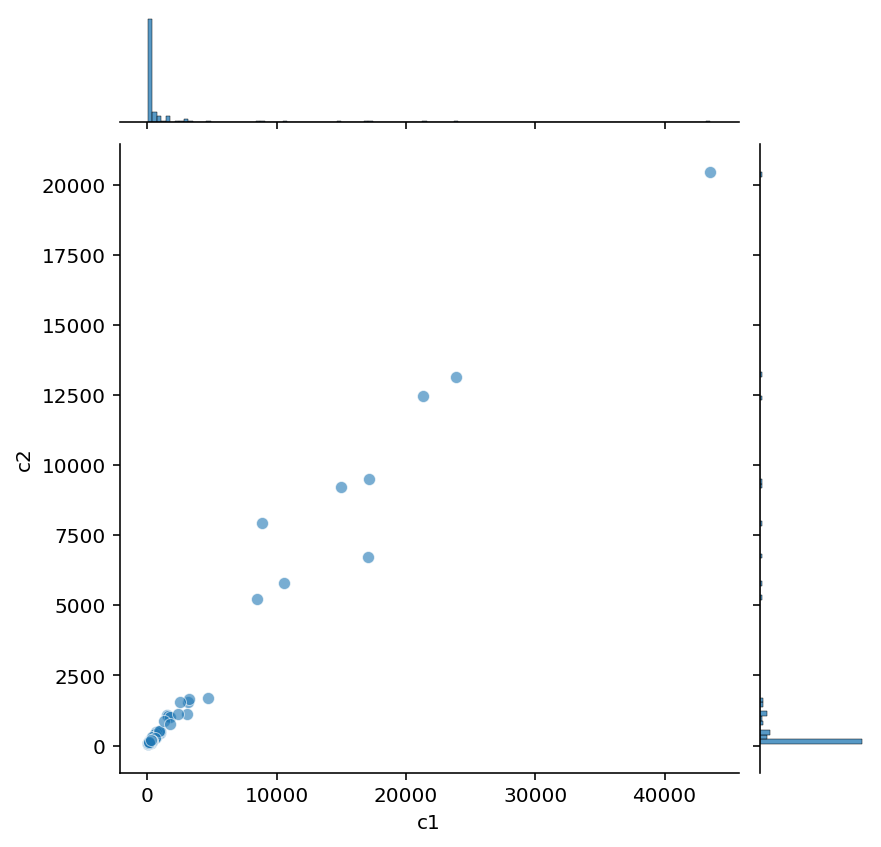

In [36]:
data1 = yN2H_retest[yN2H_retest.retest_pla == 3].yN2H_score_rep1
data2 = yN2H_retest[yN2H_retest.retest_pla == 3].yN2H_score_rep2

print(r2_score(data1, data2))

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = yN2H_retest[yN2H_retest.retest_pla == 3].copy()

df['c1'] = df.yN2H_score_rep1
df['c2'] = df.yN2H_score_rep2

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6)

In [37]:
# plt.figure(figsize=(20,5))

# df = yN2H_retest[yN2H_retest.variant_id.isin(['NCBP1_NCBP2_ctrl'])]
# plt.plot(df.retest_pla.tolist(), df.NC_yN2H_rep1.tolist(), 'ro', color='r', label='NCBP1_NCBP2_ctrl_rep1',alpha=0.75)

# df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]
# plt.plot(df.retest_pla.tolist(), df.NC_yN2H_rep1.tolist(), 'ro', color='blue', label='SKP1_SKP2_ctrl_rep1',alpha=0.75)

# df = yN2H_retest[yN2H_retest.variant_id.isin(['NCBP1_NCBP2_ctrl'])]
# plt.plot(df.retest_pla.tolist(), df.NC_yN2H_rep2.tolist(), 'ro', color='tomato', label='NCBP1_NCBP2_ctrl_rep2',alpha=0.75)

# df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]
# plt.plot(df.retest_pla.tolist(), df.NC_yN2H_rep2.tolist(), 'ro', color='dodgerblue', label='SKP1_SKP2_ctrl_rep2',alpha=0.75)


# plt.title('Plate controls')

# plt.xlabel('Plate')

# plt.xticks([i for i in range(1,38)])
# plt.ylabel('raw yN2H score')

# plt.axhline(y=np.mean([np.median(yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep1),
#                        np.median(yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep2)]), color='lightgrey', linestyle='--', label='RRS median')
# plt.legend()
# plt.ylim((0,3000))
# plt.savefig('control_plate_normalized.pdf')
# plt.show()

In [38]:
# plt.figure(figsize=(20,5))

# df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]
# plt.plot(df.retest_pla.tolist(), df.yN2H_score_rep1.tolist(), 'ro', color='blue', label='SKP1_SKP2_ctrl_rep1',alpha=0.75)

# df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]
# plt.plot(df.retest_pla.tolist(), df.yN2H_score_rep2.tolist(), 'ro', color='dodgerblue', label='SKP1_SKP2_ctrl_rep2',alpha=0.75)

# df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]
# plt.plot(df.retest_pla.tolist(), df.NC_yN2H_rep1.tolist(), 'ro', color='red', label='SKP1_SKP2_ctrl_rep1',alpha=0.75)

# df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]
# plt.plot(df.retest_pla.tolist(), df.NC_yN2H_rep2.tolist(), 'ro', color='tomato', label='SKP1_SKP2_ctrl_rep2',alpha=0.75)


# plt.title('Plate controls')

# plt.xlabel('Plate')

# plt.xticks([i for i in range(1,38)])
# plt.ylabel('raw yN2H score')

# plt.axhline(y=np.mean([np.median(yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep1),
#                        np.median(yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep2)]), color='lightgrey', linestyle='--', label='RRS median')
# plt.legend()
# plt.savefig('contrl2_normalized_based_on_ctrl1.pdf')
# plt.show()


In [39]:
# plt.figure(figsize=(20,5))

# df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]

# plt.plot(df.retest_pla.tolist(), df.yN2H_score_rep1.tolist(), 'ro', color='blue', label='SKP1_SKP2_ctrl_rep1',alpha=0.75)


# df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]

# plt.plot(df.retest_pla.tolist(), df.yN2H_score_rep2.tolist(), 'ro', color='dodgerblue', label='SKP1_SKP2_ctrl_rep2',alpha=0.75)


# df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]

# plt.plot(df.retest_pla.tolist(), df.NC_yN2H_rep1.tolist(), 'ro', color='red', label='SKP1_SKP2_ctrl_rep1',alpha=0.75)


# df = yN2H_retest[yN2H_retest.variant_id.isin(['SKP1_SKP2_ctrl'])]

# plt.plot(df.retest_pla.tolist(), df.NC_yN2H_rep2.tolist(), 'ro', color='tomato', label='SKP1_SKP2_ctrl_rep2',alpha=0.75)



# plt.title('Plate controls')

# plt.xlabel('Plate')

# plt.xticks([i for i in range(1,38)])
# plt.ylabel('raw yN2H score')

# plt.axhline(y=np.mean([np.median(yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep1),
#                        np.median(yN2H_retest[yN2H_retest.variant_id ==  'RRS'].yN2H_score_rep2)]), color='lightgrey', linestyle='--', label='RRS median')
# plt.legend()
# plt.savefig('contrl1_normalized_based_on_ctrl.pdf')
# plt.show()




### Empty wells
- RC4
- Empty well file

In [40]:
empty_well_df = pd.read_excel('20210328_yN2H_empty_wells.xlsx',sheet_name='Sheet2')
empty_well_df['replicate'] = empty_well_df.Plates.apply(lambda x: int(x.split('_')[2][-1]))
empty_well_df['plate'] = empty_well_df.Plates.apply(lambda x: int(x.split('_')[-1].replace('Plate','')))
empty_well_df['empty_wells'] = empty_well_df['Empty wells'].apply(lambda x: {f"{e.replace(' ','')[0]}{e.replace(' ','')[1:].zfill(2)}" for e in x.split(',')})
#empty_well_d = {(plate,rep):wells for plate, rep, wells in zip(empty_well_df.plate, empty_well_df.replicate, empty_well_df.empty_wells)}       
empty_well_set =  {(plate, rep, well) for plate, rep, wells in zip(empty_well_df.plate, empty_well_df.replicate, empty_well_df.empty_wells) for well in wells }

empty_well_df.head()

,Plates,Empty wells,replicate,plate,empty_wells
0,Plate1_yN2Hapwt_Rep1_Plate1,"E1, A9, B10, G12, H12",1,1,"{G12, H12, E01, B10, A09}"
1,Plate2_yN2Hapwt_Rep1_Plate2,"G7, F8, G12, H12",1,2,"{F08, H12, G12, G07}"
2,Plate3_yN2Hapwt_Rep1_Plate3,"B1, B10, G12, H12",1,3,"{B10, G12, B01, H12}"
3,Plate4_yN2Hapwt_Rep1_Plate4,"C1, A3, C4, B5, D8, G12, H12",1,4,"{B05, G12, A03, H12, C04, D08, C01}"
4,Plate5_yN2Hapwt_Rep1_Plate5,"B2, D5, A8, B8, E8, G8, B9, G12, H12",1,5,"{G12, E08, B08, D05, H12, G08, B09, B02, A08}"


In [41]:
query = '''select orf_id, mut_id from vus.N2H_validation_nodes where collection = "rc4" '''
col = ['db_orf_id','db_mut_id']
rc4_mut_ids = GetDFv2(query,col)
rc4_mut_ids = set(zip(rc4_mut_ids.db_orf_id, rc4_mut_ids.db_mut_id))

In [42]:
yN2H_retest['empty_well_rep1'] = [(db_orf_id, db_mut_id) in rc4_mut_ids or (plate,1,retest_pos) in empty_well_set for db_orf_id, db_mut_id, plate, retest_pos in zip(yN2H_retest.db_orf_id, yN2H_retest.db_mut_id, yN2H_retest.retest_pla, yN2H_retest.retest_pos)]
yN2H_retest['empty_well_rep2'] = [(db_orf_id, db_mut_id) in rc4_mut_ids or (plate,2,retest_pos) in empty_well_set for db_orf_id, db_mut_id, plate, retest_pos in zip(yN2H_retest.db_orf_id, yN2H_retest.db_mut_id, yN2H_retest.retest_pla, yN2H_retest.retest_pos)]

yN2H_retest.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_well_rep1,empty_well_rep2
309,1611,SPERT,2713,MLH1,889.0,1,A01,yN2Hapwt,allele,192,165,False,False
307,11130,SLC35E3,4062,PLP1,201426.0,1,A02,yN2Hapwt,allele,2026,1277,False,False
299,0,None,9970,PHYKPL,0.0,1,A03,yN2Hapwt,empty_N1,700,522,False,False
291,0,None,3156,PCNA,NaN,1,A04,yN2Hapwt,empty_N1,3770,2541,False,False
283,7515,XRCC4,9905,PNKP,216952.0,1,A05,yN2Hapwt,allele,5405,2726,False,False


In [43]:
yN2H_retest[yN2H_retest.empty_well_rep1|yN2H_retest.empty_well_rep2].variant_id.value_counts()

allele      163
empty_N1     43
wt            5
empty_N2      3
RRS           1
Name: variant_id, dtype: int64

In [44]:
len(yN2H_retest[yN2H_retest.empty_well_rep1|yN2H_retest.empty_well_rep2])

215

### NLR and NLD

In [45]:
empty_N1_rep1_d = {(db,db_mut_id) if db_mut_id == db_mut_id else (db,999999):score for db, db_mut_id, score in zip(yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].db_orf_id, 
                                                                                                                   yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].db_mut_id, 
                                                                                                                   yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].yN2H_score_rep1)}
empty_N2_rep1_d = dict(zip(yN2H_retest[yN2H_retest.variant_id == 'empty_N2'].ad_orf_id, yN2H_retest[yN2H_retest.variant_id == 'empty_N2'].yN2H_score_rep1))

empty_N1_rep2_d = {(db,db_mut_id) if db_mut_id == db_mut_id else (db,999999):score for db, db_mut_id, score in zip(yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].db_orf_id, 
                                                                                                                   yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].db_mut_id, 
                                                                                                                   yN2H_retest[yN2H_retest.variant_id == 'empty_N1'].yN2H_score_rep2)}
empty_N2_rep2_d = dict(zip(yN2H_retest[yN2H_retest.variant_id == 'empty_N2'].ad_orf_id, yN2H_retest[yN2H_retest.variant_id == 'empty_N2'].yN2H_score_rep2))
 

yN2H_normalized = yN2H_retest[yN2H_retest.variant_id.isin(['wt', 'allele', 'RRS','PRS'])].copy()
#yN2H_normalized['pair'] = [tuple(sorted([x,y])) for x, y in zip(yN2H_normalized.ad_orf_id, yN2H_normalized.db_orf_id)]
#yN2H_normalized['variant_idv2'] = yN2H_normalized.variant_id.apply(lambda x: x if x !=  'litbm' else 'wt')

yN2H_normalized['empty_N1_rep1'] = [empty_N1_rep1_d[(db_orf_id, db_mut_id)] if db_mut_id == db_mut_id else empty_N1_rep1_d[(db_orf_id, 999999)] for db_orf_id,db_mut_id in zip(yN2H_normalized.db_orf_id, yN2H_normalized.db_mut_id)]
yN2H_normalized['empty_N2_rep1'] = yN2H_normalized.ad_orf_id.map(empty_N2_rep1_d)

yN2H_normalized['empty_N1_rep2'] = [empty_N1_rep2_d[(db_orf_id, db_mut_id)] if db_mut_id == db_mut_id else empty_N1_rep2_d[(db_orf_id, 999999)] for db_orf_id,db_mut_id in zip(yN2H_normalized.db_orf_id, yN2H_normalized.db_mut_id)]
yN2H_normalized['empty_N2_rep2'] = yN2H_normalized.ad_orf_id.map(empty_N2_rep2_d)


yN2H_normalized['NLR1'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score_rep1, yN2H_normalized.empty_N1_rep1, yN2H_normalized.empty_N2_rep1)]
yN2H_normalized['NLR2'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score_rep2, yN2H_normalized.empty_N1_rep2, yN2H_normalized.empty_N2_rep2)]

yN2H_normalized['NLD1'] = [N1N2-N1F2-N2F1 for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score_rep1, yN2H_normalized.empty_N1_rep1, yN2H_normalized.empty_N2_rep1)]
yN2H_normalized['NLD2'] = [N1N2-N1F2-N2F1 for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score_rep2, yN2H_normalized.empty_N1_rep2, yN2H_normalized.empty_N2_rep2)]

yN2H_normalized['NLR1'] = [v if e == False else np.nan for v, e in zip(yN2H_normalized.NLR1, yN2H_normalized.empty_well_rep1)]
yN2H_normalized['NLR2'] = [v if e == False else np.nan for v, e in zip(yN2H_normalized.NLR2, yN2H_normalized.empty_well_rep2)]
yN2H_normalized['NLD1'] = [v if e == False else np.nan for v, e in zip(yN2H_normalized.NLD1, yN2H_normalized.empty_well_rep1)]
yN2H_normalized['NLD2'] = [v if e == False else np.nan for v, e in zip(yN2H_normalized.NLD2, yN2H_normalized.empty_well_rep2)]

yN2H_normalized['detected_r1'] = yN2H_normalized.NLR1.apply(lambda x: x > yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR1.max())
yN2H_normalized['detected_r2'] = yN2H_normalized.NLR2.apply(lambda x: x > yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLR2.max())

yN2H_normalized['detected_NLD1'] = yN2H_normalized.NLD1.apply(lambda x: x > yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLD1.max())
yN2H_normalized['detected_NLD2'] = yN2H_normalized.NLD2.apply(lambda x: x > yN2H_normalized[yN2H_normalized.variant_id == 'RRS'].NLD2.max())

yN2H_normalized['NLR'] = [np.mean([v for v in [v1, v2] if v == v]) for v1, v2 in zip(yN2H_normalized.NLR1, yN2H_normalized.NLR2)]
yN2H_normalized['NLD'] = [np.mean([v for v in [v1, v2] if v == v]) for v1, v2 in zip(yN2H_normalized.NLD1, yN2H_normalized.NLD2)]

#yN2H_normalized['NLR_log2'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(yN2H_normalized.yN2H_score, yN2H_normalized.empty_N1, yN2H_normalized.empty_N2)]
yN2H_normalized['pair'] = [tuple(sorted([ad,db])) for ad, db in zip(yN2H_normalized.ad_orf_id, yN2H_normalized.db_orf_id)]
yN2H_normalized.head()

/usr/local/lib/python3.8/site-packages/numpy/core/fromnumeric.py:3334: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.8/site-packages/numpy/core/_methods.py:161: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_well_rep1,empty_well_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,NLR1,NLR2,NLD1,NLD2,detected_r1,detected_r2,detected_NLD1,detected_NLD2,NLR,NLD,pair
309,1611,SPERT,2713,MLH1,889.0,1,A01,yN2Hapwt,allele,192,165,False,False,137,206,185,137,0.932039,0.891892,-151.0,-157.0,False,False,False,False,0.911965,-154.0,"(1611, 2713)"
307,11130,SLC35E3,4062,PLP1,201426.0,1,A02,yN2Hapwt,allele,2026,1277,False,False,130,460,96,460,4.404348,2.776087,1436.0,721.0,True,True,True,True,3.590217,1078.5,"(4062, 11130)"
283,7515,XRCC4,9905,PNKP,216952.0,1,A05,yN2Hapwt,allele,5405,2726,False,False,343,247,254,330,15.758017,8.260606,4815.0,2142.0,True,True,True,True,12.009312,3478.5,"(7515, 9905)"
251,55939,FAM9C,4723,TPM1,8952.0,1,A09,yN2Hapwt,allele,55,82,True,True,62,323,82,460,NaN,NaN,NaN,NaN,False,False,False,False,NaN,NaN,"(4723, 55939)"
310,6552,MAGEA8,2713,MLH1,919.0,1,B01,yN2Hapwt,allele,74907,12231,False,False,227,1490,192,845,50.273154,14.474556,73190.0,11194.0,True,True,True,True,32.373855,42192.0,"(2713, 6552)"


In [46]:
yN2H_normalized[yN2H_normalized.detected_r1].variant_id.value_counts()

allele    536
wt        123
PRS        15
Name: variant_id, dtype: int64

In [47]:
yN2H_normalized[yN2H_normalized.detected_r2].variant_id.value_counts()

allele    386
wt        104
PRS        14
Name: variant_id, dtype: int64

In [48]:
yN2H_normalized[yN2H_normalized.detected_NLD1].variant_id.value_counts()

allele    475
wt        117
PRS        14
Name: variant_id, dtype: int64

In [49]:
yN2H_normalized[yN2H_normalized.detected_NLD2].variant_id.value_counts()

allele    375
wt        107
PRS        14
Name: variant_id, dtype: int64

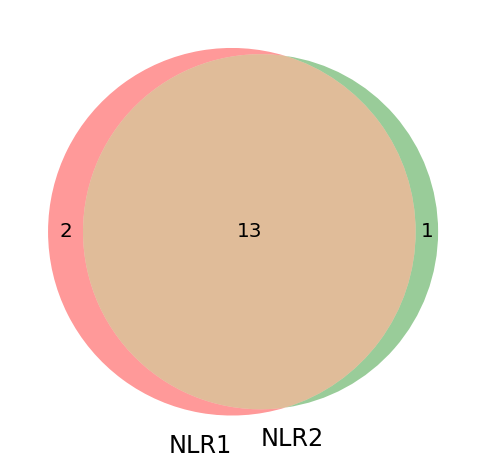

In [50]:
venn2([set(yN2H_normalized[(yN2H_normalized.detected_r1)&(yN2H_normalized.variant_id == 'PRS')].pair),
       set(yN2H_normalized[(yN2H_normalized.detected_r2)&(yN2H_normalized.variant_id == 'PRS')].pair)],
      ['NLR1','NLR2']
     )

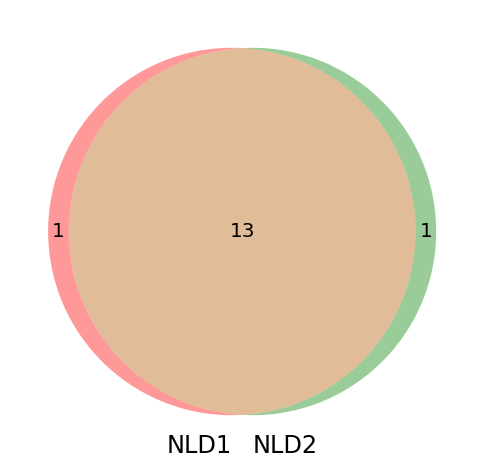

In [51]:
venn2([set(yN2H_normalized[(yN2H_normalized.detected_NLD1)&(yN2H_normalized.variant_id == 'PRS')].pair),
       set(yN2H_normalized[(yN2H_normalized.detected_NLD2)&(yN2H_normalized.variant_id == 'PRS')].pair)],
      ['NLD1','NLD2']
     )

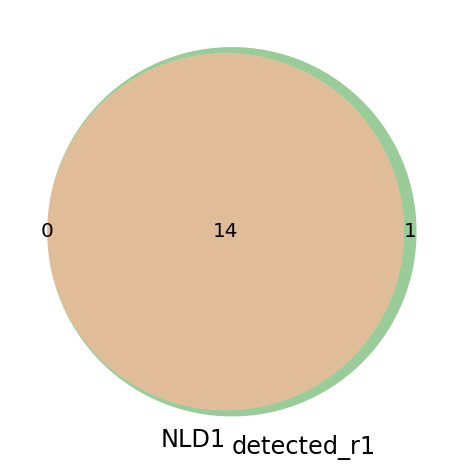

In [52]:
venn2([set(yN2H_normalized[(yN2H_normalized.detected_NLD1)&(yN2H_normalized.variant_id == 'PRS')].pair),
       set(yN2H_normalized[(yN2H_normalized.detected_r1)&(yN2H_normalized.variant_id == 'PRS')].pair)],
      ['NLD1','detected_r1']
     )

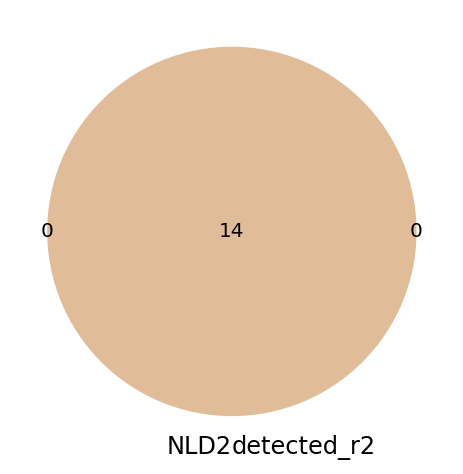

In [53]:
venn2([set(yN2H_normalized[(yN2H_normalized.detected_NLD2)&(yN2H_normalized.variant_id == 'PRS')].pair),
       set(yN2H_normalized[(yN2H_normalized.detected_r2)&(yN2H_normalized.variant_id == 'PRS')].pair)],
      ['NLD2','detected_r2']
     )

### PRS-RRS

In [54]:
yN2H_normalized.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_well_rep1,empty_well_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,NLR1,NLR2,NLD1,NLD2,detected_r1,detected_r2,detected_NLD1,detected_NLD2,NLR,NLD,pair
309,1611,SPERT,2713,MLH1,889.0,1,A01,yN2Hapwt,allele,192,165,False,False,137,206,185,137,0.932039,0.891892,-151.0,-157.0,False,False,False,False,0.911965,-154.0,"(1611, 2713)"
307,11130,SLC35E3,4062,PLP1,201426.0,1,A02,yN2Hapwt,allele,2026,1277,False,False,130,460,96,460,4.404348,2.776087,1436.0,721.0,True,True,True,True,3.590217,1078.5,"(4062, 11130)"
283,7515,XRCC4,9905,PNKP,216952.0,1,A05,yN2Hapwt,allele,5405,2726,False,False,343,247,254,330,15.758017,8.260606,4815.0,2142.0,True,True,True,True,12.009312,3478.5,"(7515, 9905)"
251,55939,FAM9C,4723,TPM1,8952.0,1,A09,yN2Hapwt,allele,55,82,True,True,62,323,82,460,NaN,NaN,NaN,NaN,False,False,False,False,NaN,NaN,"(4723, 55939)"
310,6552,MAGEA8,2713,MLH1,919.0,1,B01,yN2Hapwt,allele,74907,12231,False,False,227,1490,192,845,50.273154,14.474556,73190.0,11194.0,True,True,True,True,32.373855,42192.0,"(2713, 6552)"


In [55]:
yN2H_normalized['raw_log2_rep1'] =  yN2H_normalized.yN2H_score_rep1.apply(np.log2)
yN2H_normalized['raw_log2_rep2'] =  yN2H_normalized.yN2H_score_rep2.apply(np.log2)
# yN2H_normalized['NC_log2_rep1'] =  yN2H_normalized.NC_yN2H_rep1.apply(np.log2)
# yN2H_normalized['NC_log2_rep2'] =  yN2H_normalized.NC_yN2H_rep2.apply(np.log2)

Text(0, 0.5, 'raw_log2_rep2')

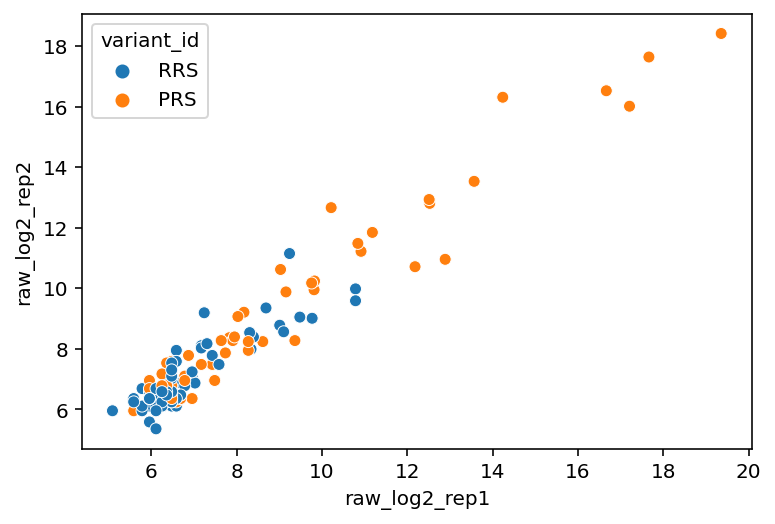

In [56]:
sns.scatterplot(data=yN2H_normalized[yN2H_normalized.variant_id.isin(['PRS','RRS'])], x='raw_log2_rep1', y='raw_log2_rep2', hue='variant_id')
plt.xlabel('raw_log2_rep1')
plt.ylabel('raw_log2_rep2')

pearson (0.9664470300500263, 3.7074147057507506e-82)
spearman SpearmanrResult(correlation=0.8632159296078311, pvalue=3.3534770198503834e-42)


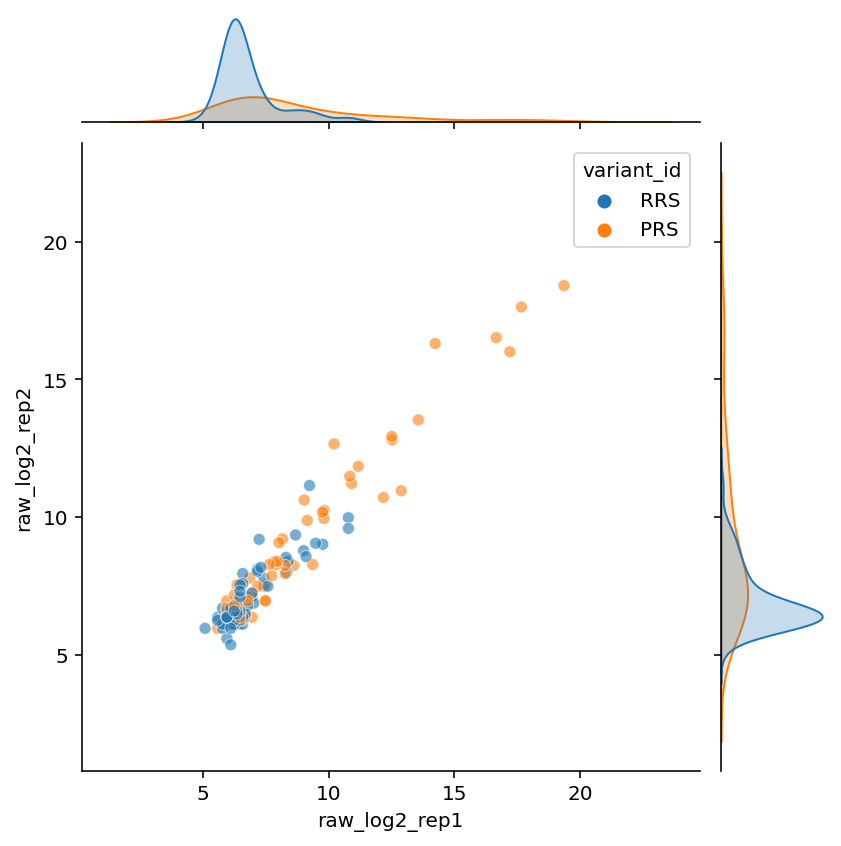

In [57]:
data1 = yN2H_normalized[yN2H_normalized.variant_id.isin(['PRS','RRS'])].raw_log2_rep1
data2 = yN2H_normalized[yN2H_normalized.variant_id.isin(['PRS','RRS'])].raw_log2_rep2

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

sns.jointplot(data=yN2H_normalized[yN2H_normalized.variant_id.isin(['PRS','RRS'])], x='raw_log2_rep1', y='raw_log2_rep2',alpha=0.6, hue='variant_id')



In [58]:
# data1 = yN2H_normalized[yN2H_normalized.variant_id.isin(['PRS','RRS'])].NC_log2_rep1

# data2 = yN2H_normalized[yN2H_normalized.variant_id.isin(['PRS','RRS'])].NC_log2_rep2

# pearson_corr = pearsonr(data1, data2)
# spearman_corr = spearmanr(data1, data2)
# print('pearson',pearson_corr)
# print('spearman',spearman_corr)

# sns.jointplot(data=yN2H_normalized[yN2H_normalized.variant_id.isin(['PRS','RRS'])], x='NC_log2_rep1', y='NC_log2_rep2',alpha=0.6, hue='variant_id')


Text(0, 0.5, 'NLR2')

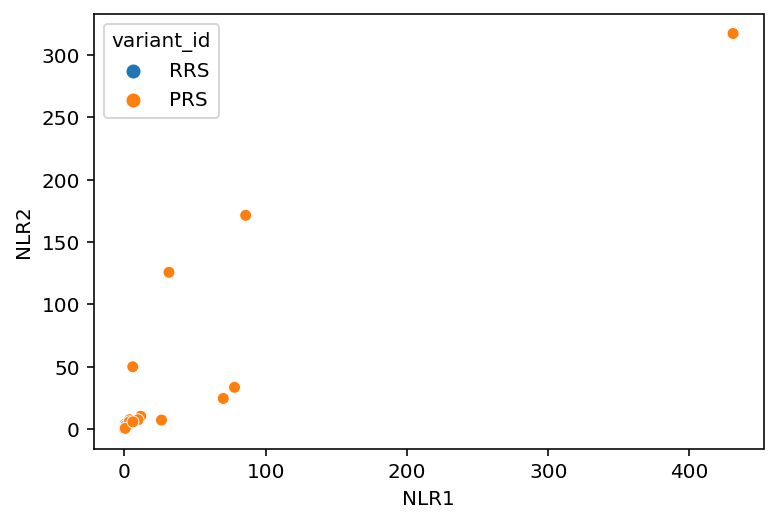

In [59]:
sns.scatterplot(data=yN2H_normalized[yN2H_normalized.variant_id.isin(['PRS','RRS'])], x='NLR1', y='NLR2', hue='variant_id')
plt.xlabel('NLR1')
plt.ylabel('NLR2')

Text(0, 0.5, 'NLD2')

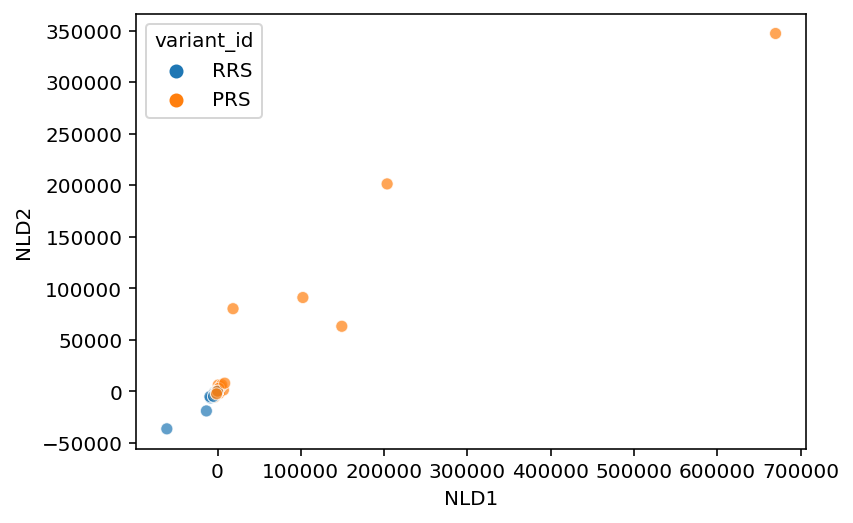

In [60]:
sns.scatterplot(data=yN2H_normalized[yN2H_normalized.variant_id.isin(['PRS','RRS'])], x='NLD1', y='NLD2', hue='variant_id', alpha=0.7, y_jitter=10)
plt.xlabel('NLD1')
plt.ylabel('NLD2')

# First PRS-RRS yN2H xp

In [61]:
first_prs = pd.read_csv('../20210223_yN2H_PRS/yN2H_PRS_RRS_table.csv',sep='\t',index_col=0)
first_prs.head()

,ad_orf_id,db_orf_id,retest_type,plate,N2_source_well,N1_source_plate,N2_source_plate,N1_source_well,pair,YN2H_N1N2_XY,AB_GFP,AF2_GFP,BF1_GFP,AB_old,AF2_old,BF1_old,NLR_old,NLR_GFP,positive_SG,positive_old,positive_GFP,NLR_old_log2,NLR_GFP_log2,NLR_SG_log2
0,1108,5001,PRS,1,A01,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,A01,"('LCP2', 'NCK1')",10.476279,8687,1161,1717,4319,948,2026,2.131787,5.059406,True,True,True,1.092063,2.338968,3.389055
1,617,4447,RRS,1,D01,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,D01,"('SHMT2', 'STAC3')",0.253102,110,89,247,82,76,220,0.372727,0.445344,False,False,False,-1.423808,-1.167008,-1.982211
2,3535,5887,RRS,1,F01,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,F01,"('ARMC1', 'EMD')",0.331672,1806,2246,261,2925,3090,185,0.946602,0.804096,False,False,False,-0.079170,-0.314560,-1.592169
3,3174,7186,RRS,1,G01,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,G01,"('PDHB', 'ZC3HC1')",0.077327,103,721,103,144,591,69,0.243655,0.142857,False,False,False,-2.037089,-2.807355,-3.692885
4,273,5046,RRS,1,A02,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,A02,"('FKBP3', 'NQO2')",0.061356,1476,1442,172,1600,1250,110,1.280000,1.023578,False,False,False,0.356144,0.033622,-4.026647


# WT pwt & PRS-RRS

In [62]:
res = {}
for elem in glob.glob('../20210302_yN2H_WT_PWT/data/*'):
    if 'Plate' in elem:
        
        retest_pla = int(elem.split('_')[4][-2:])
        
        df = pd.read_excel(elem, skiprows=10, skipfooter=35)
        df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)
        
        value_d = dict()
        for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
            for i, value in enumerate(row):
                key = (retest_pla,f'{l}{str(i+1).zfill(2)}')
                
                res[key] = value

col = ['ad_orf_id', 'ad_symbol', 'db_orf_id',
       
       'db_symbol', 'retest_pla', 'retest_pos',
       'standard_batch', 'variant_id']


query = f'select distinct { ", ".join(c for c in col)} from vus.retest where `standard_batch` in ("yN2Hwtpwt");'

yN2H_wt_retest = GetDFv2(query, col)
yN2H_wt_retest['yN2H_score'] = [res[(pla, pos)] for pla, pos in zip(yN2H_wt_retest.retest_pla, yN2H_wt_retest.retest_pos)]

empty_N1_d = dict(zip(yN2H_wt_retest[yN2H_wt_retest.variant_id == 'empty_N1'].db_orf_id, yN2H_wt_retest[yN2H_wt_retest.variant_id == 'empty_N1'].yN2H_score))
empty_N2_d = dict(zip(yN2H_wt_retest[yN2H_wt_retest.variant_id == 'empty_N2'].ad_orf_id, yN2H_wt_retest[yN2H_wt_retest.variant_id == 'empty_N2'].yN2H_score))


yN2H_wt_normalized = yN2H_wt_retest[yN2H_wt_retest.variant_id.isin(['wt','RRS','PRS','litbm'])].copy()
yN2H_wt_normalized['pair'] = [tuple(sorted([x,y])) for x, y in zip(yN2H_wt_normalized.ad_orf_id, yN2H_wt_normalized.db_orf_id)]
yN2H_wt_normalized['variant_idv2'] = yN2H_wt_normalized.variant_id.apply(lambda x: x if x !=  'litbm' else 'wt')

yN2H_wt_normalized['empty_N1'] = yN2H_wt_normalized.db_orf_id.map(empty_N1_d)
yN2H_wt_normalized['empty_N2'] = yN2H_wt_normalized.ad_orf_id.map(empty_N2_d)

yN2H_wt_normalized['NLR'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(yN2H_wt_normalized.yN2H_score, yN2H_wt_normalized.empty_N1, yN2H_wt_normalized.empty_N2)]
yN2H_wt_normalized['NLD'] = [N1N2-max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(yN2H_wt_normalized.yN2H_score, yN2H_wt_normalized.empty_N1, yN2H_wt_normalized.empty_N2)]


yN2H_wt_normalized.head()


*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 'ascii'
*** No CODEPAGE record, no encoding_override: will use 

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score,pair,variant_idv2,empty_N1,empty_N2,NLR,NLD
2,53053,CCHCR1,386,STAR,1,C01,yN2Hwtpwt,litbm,96,"(386, 53053)",wt,179,151,0.536313,-83
3,52859,CCDC136,54082,PRPF31,1,D01,yN2Hwtpwt,wt,89,"(52859, 54082)",wt,261,165,0.340996,-172
8,6759,RPS27A,52920,LITAF,1,B02,yN2Hwtpwt,wt,103,"(6759, 52920)",wt,137,2479,0.041549,-2376
11,70408,OXER1,5933,TFG,1,E02,yN2Hwtpwt,wt,69,"(5933, 70408)",wt,199,89,0.346734,-130
12,14862,GOLGA2,54459,RNF135,1,F02,yN2Hwtpwt,wt,144,"(14862, 54459)",wt,185,920,0.156522,-776


In [63]:
prs_df = yN2H_wt_normalized[yN2H_wt_normalized.variant_id.isin(['PRS','RRS'])].copy()

col =  ['ad_orf_id', 'db_orf_id', 'retest_type', 'positive_SG', 'positive_old','positive_GFP', 'NLR_old_log2', 'NLR_GFP_log2', 'NLR_SG_log2']
previous_prs_df  = pd.read_csv('../20210223_yN2H_PRS/yN2H_PRS_RRS_table.csv', sep='\t', index_col=0)

prs_df =  prs_df.merge(previous_prs_df[col], on=['ad_orf_id', 'db_orf_id'])
prs_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score,pair,variant_idv2,empty_N1,empty_N2,NLR,NLD,retest_type,positive_SG,positive_old,positive_GFP,NLR_old_log2,NLR_GFP_log2,NLR_SG_log2
0,3621,CD81,7941,NPC2,1,B03,yN2Hwtpwt,RRS,76,"(3621, 7941)",RRS,96,515,0.147573,-439,RRS,False,False,False,-0.299560,-1.718818,-1.725975
1,7772,PSMD12,5546,CRIPT,1,F04,yN2Hwtpwt,RRS,96,"(5546, 7772)",RRS,82,240,0.400000,-144,RRS,False,False,False,-0.739764,-0.285402,-3.821796
2,4958,ATF3,3944,DDIT3,1,D05,yN2Hwtpwt,PRS,886,"(3944, 4958)",PRS,110,172,5.151163,714,PRS,False,True,True,2.365476,1.790711,0.287552
3,5545,LUM,9673,UGGT2,1,F05,yN2Hwtpwt,RRS,76,"(5545, 9673)",RRS,117,151,0.503311,-75,RRS,False,False,False,-0.812373,-0.898853,-0.842899
4,1938,CBLB,8010,GRB2,1,A06,yN2Hwtpwt,PRS,3090,"(1938, 8010)",PRS,378,597,5.175879,2493,PRS,True,True,True,3.097238,2.328508,2.099091


# Merge all pairwise tests

## PRS-RRS: GFP and classic vector + Soon Gang data

In [64]:
first_prs.columns

Index(['ad_orf_id', 'db_orf_id', 'retest_type', 'plate', 'N2_source_well',
       'N1_source_plate', 'N2_source_plate', 'N1_source_well', 'pair',
       'YN2H_N1N2_XY', 'AB_GFP', 'AF2_GFP', 'BF1_GFP', 'AB_old', 'AF2_old',
       'BF1_old', 'NLR_old', 'NLR_GFP', 'positive_SG', 'positive_old',
       'positive_GFP', 'NLR_old_log2', 'NLR_GFP_log2', 'NLR_SG_log2'],
      dtype='object')

In [65]:
col = ['ad_orf_id', 'db_orf_id',  'pair',
       'YN2H_N1N2_XY', 'AB_GFP', 'AF2_GFP', 'BF1_GFP', 'AB_old', 'AF2_old',
       'BF1_old', 'NLR_old', 'NLR_GFP', 'positive_SG', 'positive_old',
       'positive_GFP', 'NLR_old_log2', 'NLR_GFP_log2', 'NLR_SG_log2']

In [66]:
first_prs.head()

,ad_orf_id,db_orf_id,retest_type,plate,N2_source_well,N1_source_plate,N2_source_plate,N1_source_well,pair,YN2H_N1N2_XY,AB_GFP,AF2_GFP,BF1_GFP,AB_old,AF2_old,BF1_old,NLR_old,NLR_GFP,positive_SG,positive_old,positive_GFP,NLR_old_log2,NLR_GFP_log2,NLR_SG_log2
0,1108,5001,PRS,1,A01,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,A01,"('LCP2', 'NCK1')",10.476279,8687,1161,1717,4319,948,2026,2.131787,5.059406,True,True,True,1.092063,2.338968,3.389055
1,617,4447,RRS,1,D01,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,D01,"('SHMT2', 'STAC3')",0.253102,110,89,247,82,76,220,0.372727,0.445344,False,False,False,-1.423808,-1.167008,-1.982211
2,3535,5887,RRS,1,F01,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,F01,"('ARMC1', 'EMD')",0.331672,1806,2246,261,2925,3090,185,0.946602,0.804096,False,False,False,-0.079170,-0.314560,-1.592169
3,3174,7186,RRS,1,G01,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,G01,"('PDHB', 'ZC3HC1')",0.077327,103,721,103,144,591,69,0.243655,0.142857,False,False,False,-2.037089,-2.807355,-3.692885
4,273,5046,RRS,1,A02,yN2H_PRS_N1_1A,yN2H_PRS_N2_1B,A02,"('FKBP3', 'NQO2')",0.061356,1476,1442,172,1600,1250,110,1.280000,1.023578,False,False,False,0.356144,0.033622,-4.026647


## WT PWT PRS-RRS  and WT pairs

In [67]:
#wtpwt
yN2H_wt_d = {(ad,db):(yN2H_score,empty_N1,empty_N2,NLR,NLD) for ad,db,yN2H_score,empty_N1,empty_N2,NLR,NLD in zip(yN2H_wt_normalized.ad_orf_id,
                                                                                                                  yN2H_wt_normalized.db_orf_id,
                                                                                                                  yN2H_wt_normalized.yN2H_score,
                                                                                                                  yN2H_wt_normalized.empty_N1,
                                                                                                                  yN2H_wt_normalized.empty_N2,
                                                                                                                  yN2H_wt_normalized.NLR,
                                                                                                                  yN2H_wt_normalized.NLD)}


yN2H_normalized['wtpwt_yn2h_raw'] = [yN2H_wt_d[(ad,db)][0] for ad, db in zip(yN2H_normalized.ad_orf_id, yN2H_normalized.db_orf_id)]
yN2H_normalized['wtpwt_en1_raw'] = [yN2H_wt_d[(ad,db)][1] for ad, db in zip(yN2H_normalized.ad_orf_id, yN2H_normalized.db_orf_id)]
yN2H_normalized['wtpwt_en2_raw'] = [yN2H_wt_d[(ad,db)][2] for ad, db in zip(yN2H_normalized.ad_orf_id, yN2H_normalized.db_orf_id)]
yN2H_normalized['wtpwt_nlr'] = [yN2H_wt_d[(ad,db)][3] for ad, db in zip(yN2H_normalized.ad_orf_id, yN2H_normalized.db_orf_id)]
yN2H_normalized['wtpwt_nld'] = [yN2H_wt_d[(ad,db)][4] for ad, db in zip(yN2H_normalized.ad_orf_id, yN2H_normalized.db_orf_id)]


#prs-rrs first xp
all_dataset = yN2H_normalized.merge(first_prs[col], how='outer', on=['ad_orf_id', 'db_orf_id'])

all_dataset.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_well_rep1,empty_well_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,NLR1,NLR2,NLD1,NLD2,detected_r1,detected_r2,detected_NLD1,detected_NLD2,NLR,NLD,pair_x,raw_log2_rep1,raw_log2_rep2,wtpwt_yn2h_raw,wtpwt_en1_raw,wtpwt_en2_raw,wtpwt_nlr,wtpwt_nld,pair_y,YN2H_N1N2_XY,AB_GFP,AF2_GFP,BF1_GFP,AB_old,AF2_old,BF1_old,NLR_old,NLR_GFP,positive_SG,positive_old,positive_GFP,NLR_old_log2,NLR_GFP_log2,NLR_SG_log2
0,1611,SPERT,2713,MLH1,889.0,1,A01,yN2Hapwt,allele,192,165,False,False,137,206,185,137,0.932039,0.891892,-151.0,-157.0,False,False,False,False,0.911965,-154.0,"(1611, 2713)",7.584963,7.366322,165,240,151,0.6875,-75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1611,SPERT,2713,MLH1,4554.0,1,B09,yN2Hapwt,allele,62,69,True,True,48,206,76,137,NaN,NaN,NaN,NaN,False,False,False,False,NaN,NaN,"(1611, 2713)",5.954196,6.108524,165,240,151,0.6875,-75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1611,SPERT,2713,MLH1,200834.0,1,H04,yN2Hapwt,allele,110,137,False,False,288,206,179,137,0.381944,0.765363,-384.0,-179.0,False,False,False,False,0.573654,-281.5,"(1611, 2713)",6.781360,7.098032,165,240,151,0.6875,-75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1611,SPERT,2713,MLH1,200837.0,2,H06,yN2Hapwt,allele,76,69,False,False,151,206,82,137,0.368932,0.503650,-281.0,-150.0,False,False,False,False,0.436291,-215.5,"(1611, 2713)",6.247928,6.108524,165,240,151,0.6875,-75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1611,SPERT,2713,MLH1,472.0,4,F12,yN2Hapwt,allele,110,110,False,False,124,206,137,137,0.533981,0.802920,-220.0,-164.0,False,False,False,False,0.668450,-192.0,"(1611, 2713)",6.781360,6.781360,165,240,151,0.6875,-75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# all dataset analysis

## SG  data analysis

In [68]:
raw_sg_data = pd.read_excel('../../../MasterThesis_Gaspard/data/41467_2019_11809_MOESM6_ESM.xlsx',sheet_name='N2H raw data with 3 replicates')
raw_sg_data.rename(columns={c:'_'.join(w for w in c.replace('(','').replace(')','').split()) for c in raw_sg_data.columns},inplace=True)

col = ['Category', 'Symbol_X', 'Symbol_Y',
       'YN2H_N1N2_rep1', 'YN2H_N1N2_rep2', 'YN2H_N1N2_rep3',
       'YN2H_F1N2_rep1', 'YN2H_F1N2_rep2', 'YN2H_F1N2_rep3','YN2H_N1F2_rep1', 'YN2H_N1F2_rep2', 'YN2H_N1F2_rep3']

raw_sg_data = raw_sg_data[col].copy()
for rep in ['1','2','3']:
    raw_sg_data[f'NLR{rep}'] = [n1n2 / max(n2, n1) for n1n2, n2, n1 in zip(raw_sg_data[f'YN2H_N1N2_rep{rep}'], raw_sg_data[f'YN2H_F1N2_rep{rep}'], raw_sg_data[f'YN2H_N1F2_rep{rep}'])]
    raw_sg_data[f'NLD{rep}'] = [n1n2 - max(n2, n1) for n1n2, n2, n1 in zip(raw_sg_data[f'YN2H_N1N2_rep{rep}'], raw_sg_data[f'YN2H_F1N2_rep{rep}'], raw_sg_data[f'YN2H_N1F2_rep{rep}'])]
    
    raw_sg_data[f'NLDA{rep}'] = [n1n2 - (n2 + n1) for n1n2, n2, n1 in zip(raw_sg_data[f'YN2H_N1N2_rep{rep}'], raw_sg_data[f'YN2H_F1N2_rep{rep}'], raw_sg_data[f'YN2H_N1F2_rep{rep}'])]
    raw_sg_data[f'NLDP{rep}'] = [n1n2 - (n2 * n1) for n1n2, n2, n1 in zip(raw_sg_data[f'YN2H_N1N2_rep{rep}'], raw_sg_data[f'YN2H_F1N2_rep{rep}'], raw_sg_data[f'YN2H_N1F2_rep{rep}'])]
    
    raw_sg_data[f'NLRA{rep}'] = [n1n2 / (n2 + n1) for n1n2, n2, n1 in zip(raw_sg_data[f'YN2H_N1N2_rep{rep}'], raw_sg_data[f'YN2H_F1N2_rep{rep}'], raw_sg_data[f'YN2H_N1F2_rep{rep}'])]
    raw_sg_data[f'NLRP{rep}'] = [n1n2 / (n2 * n1) for n1n2, n2, n1 in zip(raw_sg_data[f'YN2H_N1N2_rep{rep}'], raw_sg_data[f'YN2H_F1N2_rep{rep}'], raw_sg_data[f'YN2H_N1F2_rep{rep}'])]


raw_sg_data['avg_NLR'] = [np.mean([NLR1,NLR2,NLR3]) for NLR1,NLR2,NLR3 in zip(raw_sg_data.NLR1, raw_sg_data.NLR2, raw_sg_data.NLR3)]
raw_sg_data['avg_NLD'] = [np.mean([NLD1,NLD2,NLD3]) for NLD1,NLD2,NLD3 in zip(raw_sg_data.NLD1, raw_sg_data.NLD2, raw_sg_data.NLD3)]
raw_sg_data['avg_NLRA'] = [np.mean([NLRA1,NLRA2,NLRA3]) for NLRA1,NLRA2,NLRA3 in zip(raw_sg_data.NLRA1, raw_sg_data.NLRA2, raw_sg_data.NLRA3)]
raw_sg_data['avg_NLDA'] = [np.mean([NLDA1,NLDA2,NLDA3]) for NLDA1,NLDA2,NLDA3 in zip(raw_sg_data.NLDA1, raw_sg_data.NLDA2, raw_sg_data.NLDA3)]
    
#for rep in ['1','2','3']:
#    raw_sg_data[f'zNLR{rep}'] = raw_sg_data[f'NLR{rep}'].apply(lambda x: ((x - np.mean([e for e in raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLR{rep}']]))/np.std([e for e in raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLR{rep}']])))
#    raw_sg_data[f'zNLD{rep}'] = raw_sg_data[f'NLD{rep}_neg'].apply(lambda x: (x - np.mean(raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLD{rep}_neg']))   / np.std(raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLD{rep}_neg']))

raw_sg_data['pair'] = [tuple(sorted([x,y])) for x,y in zip(raw_sg_data.Symbol_X, raw_sg_data.Symbol_Y)]
raw_sg_data.head()

,Category,Symbol_X,Symbol_Y,YN2H_N1N2_rep1,YN2H_N1N2_rep2,YN2H_N1N2_rep3,YN2H_F1N2_rep1,YN2H_F1N2_rep2,YN2H_F1N2_rep3,YN2H_N1F2_rep1,YN2H_N1F2_rep2,YN2H_N1F2_rep3,NLR1,NLD1,NLDA1,NLDP1,NLRA1,NLRP1,NLR2,NLD2,NLDA2,NLDP2,NLRA2,NLRP2,NLR3,NLD3,NLDA3,NLDP3,NLRA3,NLRP3,avg_NLR,avg_NLD,avg_NLRA,avg_NLDA,pair
0,PRS,LCP2,NCK1,625453,123989,513902,60500,22027,20680,55819,20735,44037,10.338066,564953,509134,-3376424047,5.377049,0.000185,5.628955,101962,81227,-456605856,2.899514,0.000271,11.669778,469865,449185,-910171258,7.940757,0.000564,9.212266,378926.666667,5.405773,346515.333333,"(LCP2, NCK1)"
1,RRS,SHMT2,STAC3,254,117,240,1463,563,391,728,199,378,0.173616,-1209,-1937,-1064810,0.115929,0.000238,0.207815,-446,-645,-111920,0.153543,0.001044,0.613811,-151,-529,-147558,0.312094,0.001624,0.331747,-602.000000,0.193855,-1037.000000,"(SHMT2, STAC3)"
2,RRS,EMD,ARMC1,20268,3962,11915,1071,618,488,69955,16497,22522,0.289729,-49687,-50758,-74901537,0.285360,0.000271,0.240165,-12535,-13153,-10191184,0.231493,0.000389,0.529038,-10607,-11095,-10978821,0.517818,0.001084,0.352977,-24276.333333,0.344890,-25002.000000,"(ARMC1, EMD)"
3,RRS,PDHB,ZC3HC1,254,103,130,309,185,130,4354,1003,927,0.058337,-4100,-4409,-1345132,0.054471,0.000189,0.102692,-900,-1085,-185452,0.086700,0.000555,0.140237,-797,-927,-120380,0.122990,0.001079,0.100422,-1932.333333,0.088054,-2140.333333,"(PDHB, ZC3HC1)"
4,RRS,FKBP3,NQO2,1566,405,453,309,144,185,25902,5920,7685,0.060459,-24336,-24645,-8002152,0.059746,0.000196,0.068412,-5515,-5659,-852075,0.066788,0.000475,0.058946,-7232,-7417,-1421272,0.057560,0.000319,0.062606,-12361.000000,0.061365,-12573.666667,"(FKBP3, NQO2)"


In [69]:
raw_sg_data_d = {tuple(sorted([x,y])):(YN2H_N1N2_rep1,YN2H_N1N2_rep2,YN2H_N1N2_rep3,YN2H_F1N2_rep1,YN2H_F1N2_rep2,YN2H_F1N2_rep3,YN2H_N1F2_rep1,YN2H_N1F2_rep2,YN2H_N1F2_rep3,NLR1,NLR2,NLR3) 
                 for x,y,YN2H_N1N2_rep1,YN2H_N1N2_rep2,YN2H_N1N2_rep3,YN2H_F1N2_rep1,YN2H_F1N2_rep2,YN2H_F1N2_rep3,YN2H_N1F2_rep1,YN2H_N1F2_rep2,YN2H_N1F2_rep3,NLR1,NLR2,NLR3 
                 in zip(raw_sg_data.Symbol_X,
                        raw_sg_data.Symbol_Y,
                        raw_sg_data.YN2H_N1N2_rep1,
                        raw_sg_data.YN2H_N1N2_rep2,
                        raw_sg_data.YN2H_N1N2_rep3,
                        raw_sg_data.YN2H_F1N2_rep1,
                        raw_sg_data.YN2H_F1N2_rep2,
                        raw_sg_data.YN2H_F1N2_rep3,
                        raw_sg_data.YN2H_N1F2_rep1,
                        raw_sg_data.YN2H_N1F2_rep2,
                        raw_sg_data.YN2H_N1F2_rep3,
                        raw_sg_data.NLR1,
                        raw_sg_data.NLR2,
                        raw_sg_data.NLR3
                 )}


In [70]:
np.std(raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLR{rep}'])

0.2901570707759067

In [71]:
np.mean(raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLR{rep}'])

0.28618167489856533

In [72]:
np.mean(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_F1N2_rep1)

3575.602564102564

In [73]:
np.mean(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1N2_rep1)

2858.346153846154

In [74]:
np.mean(raw_sg_data[raw_sg_data.Category == 'PRS'].YN2H_N1N2_rep1)

335034.3

In [75]:
np.mean(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1F2_rep1)

36364.11538461538

In [76]:
np.mean(raw_sg_data[raw_sg_data.Category == 'PRS'].YN2H_N1F2_rep1)

21872.983333333334

In [77]:
# np.mean(raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLD2_neg'])

In [78]:
# np.mean(raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLD3_neg'])

In [79]:
# fig, ax = plt.subplots(figsize=(10,5))
# fig.suptitle('NLD1_neg', size=20)
# sns.kdeplot(data=raw_sg_data[raw_sg_data.Category == 'RRS'], x ='NLD1_neg', color='g',ax=ax)#, log_scale=2)
# sns.kdeplot(data=raw_sg_data[raw_sg_data.Category == 'PRS'], x ='NLD1_neg', color='r',ax=ax)#, log_scale=2)

In [80]:
# raw_sg_data[raw_sg_data.Category == 'RRS'].zNLR1.plot.hist(bins=100)

In [81]:
# raw_sg_data[raw_sg_data.Category == 'RRS'].zNLR3.plot.hist(bins=20)

In [82]:
# raw_sg_data[raw_sg_data.Category == 'RRS'].zNLD3.plot.hist(bins=30)

In [83]:
# raw_sg_data[raw_sg_data.Category == 'RRS'].zNLD3.max()

In [84]:
# raw_sg_data[raw_sg_data.Category == 'RRS'].zNLD1.max()

In [85]:
# for e in raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLD{rep}_neg'].tolist():

#     std = np.std(raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLD{rep}_neg'])
#     mean = np.mean(raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLD{rep}_neg'])
    
#     print(e, (e-mean)/std)

In [86]:
# for e in raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLR{rep}'].tolist():
#     print(e)
#     std = np.std(raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLR{rep}'])
#     mean = np.mean(raw_sg_data[raw_sg_data.Category == 'RRS'][f'NLR{rep}'])
    
#     print((e-mean)/std)

### raw correlation between replicates + NLR, NLD

pearson (0.9621231322742698, 1.2181779956181941e-78)
spearman SpearmanrResult(correlation=0.9072201227274429, pvalue=5.371546260758415e-53)


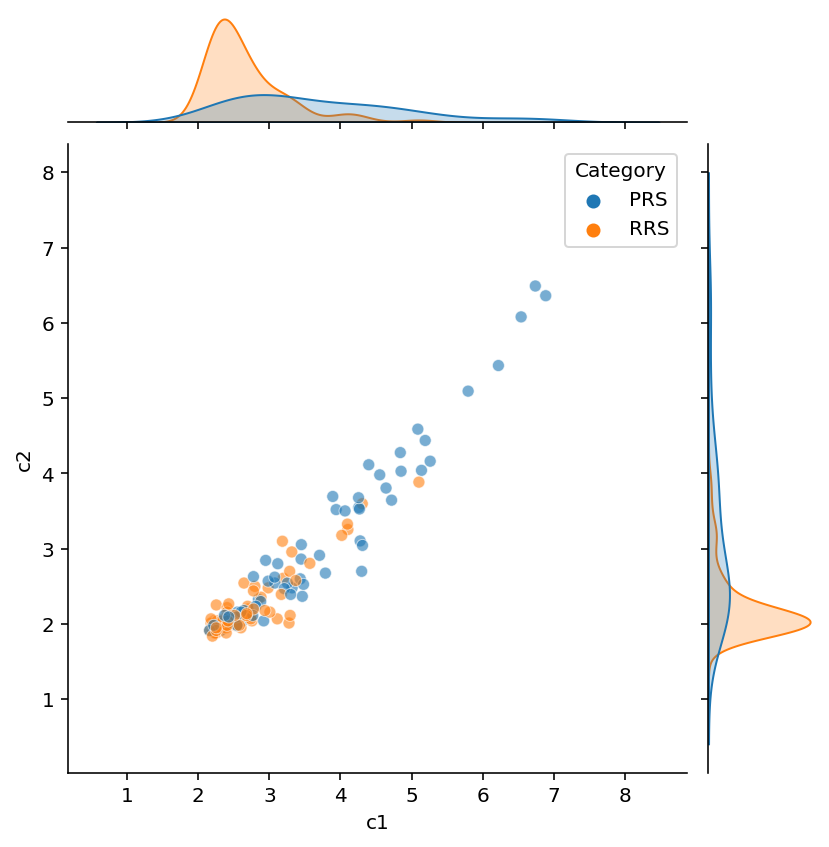

In [87]:
data1 = raw_sg_data.YN2H_N1N2_rep1.apply(np.log10)
data2 = raw_sg_data.YN2H_N1N2_rep2.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data.copy()

df['c1'] = df.YN2H_N1N2_rep1.apply(np.log10)
df['c2'] = df.YN2H_N1N2_rep2.apply(np.log10)

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

pearson (0.9492951501034319, 3.248400505408514e-70)
spearman SpearmanrResult(correlation=0.9125256504641739, pvalue=1.1767399891247887e-54)


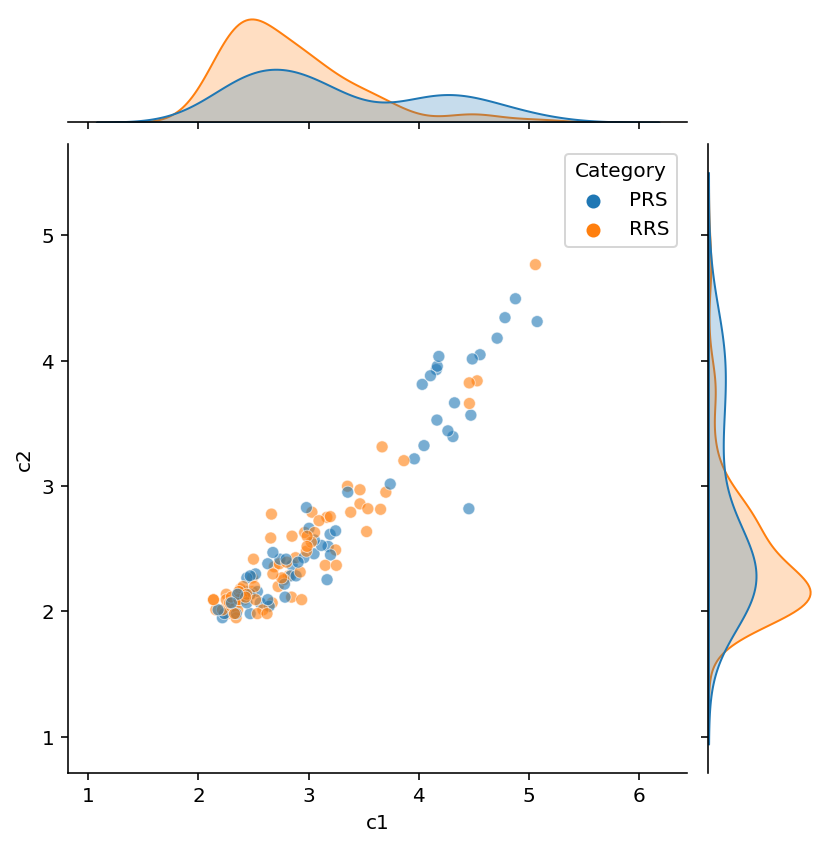

In [88]:
data1 = raw_sg_data.YN2H_F1N2_rep1.apply(np.log10)
data2 = raw_sg_data.YN2H_F1N2_rep2.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data.copy()

df['c1'] = df.YN2H_F1N2_rep1.apply(np.log10)
df['c2'] = df.YN2H_F1N2_rep2.apply(np.log10)

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

pearson (0.9818517996676285, 4.4028240068838645e-100)
spearman SpearmanrResult(correlation=0.940892285153517, pvalue=8.247579428341708e-66)


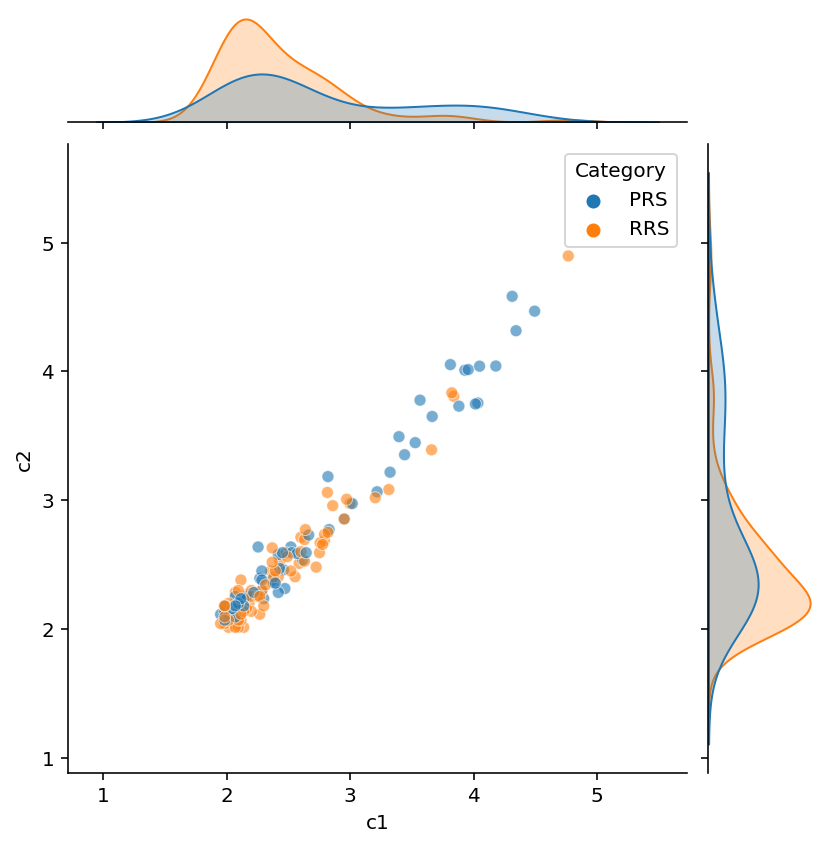

In [89]:
data1 = raw_sg_data.YN2H_F1N2_rep2.apply(np.log10)
data2 = raw_sg_data.YN2H_F1N2_rep3.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data.copy()

df['c1'] = df.YN2H_F1N2_rep2.apply(np.log10)
df['c2'] = df.YN2H_F1N2_rep3.apply(np.log10)

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

pearson (0.9567873035777948, 7.939732619473495e-75)
spearman SpearmanrResult(correlation=0.9460199181188431, pvalue=2.05115813169677e-68)


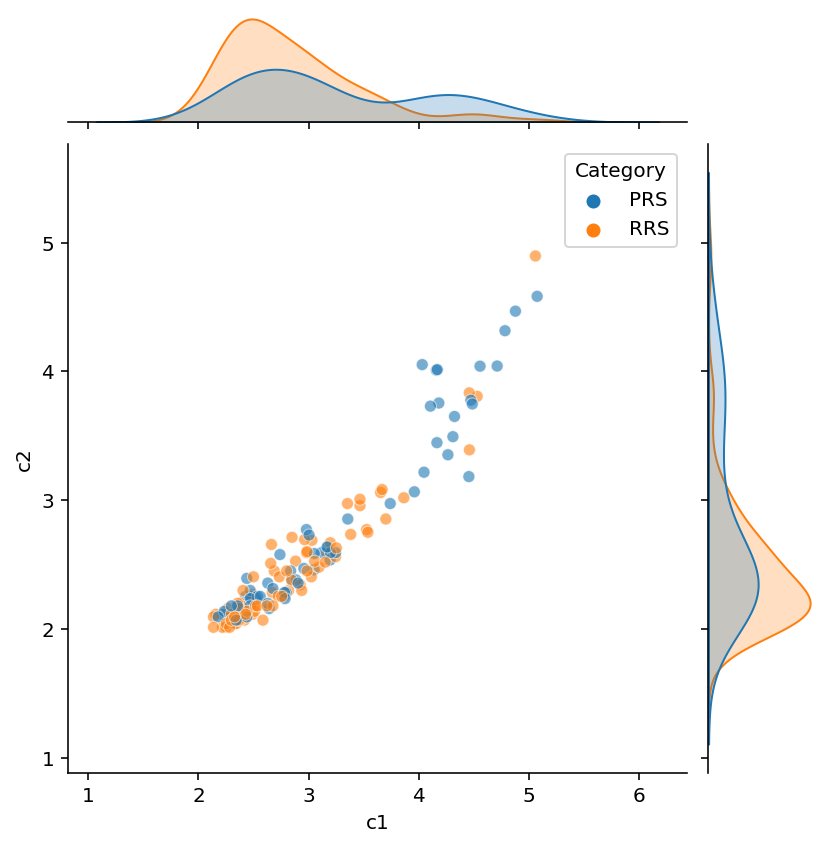

In [90]:
data1 = raw_sg_data.YN2H_F1N2_rep1.apply(np.log10)
data2 = raw_sg_data.YN2H_F1N2_rep3.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data.copy()

df['c1'] = df.YN2H_F1N2_rep1.apply(np.log10)
df['c2'] = df.YN2H_F1N2_rep3.apply(np.log10)

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

pearson (0.9573053986083195, 3.5577969196741366e-75)
spearman SpearmanrResult(correlation=0.953810499817163, pvalue=6.661105018698293e-73)


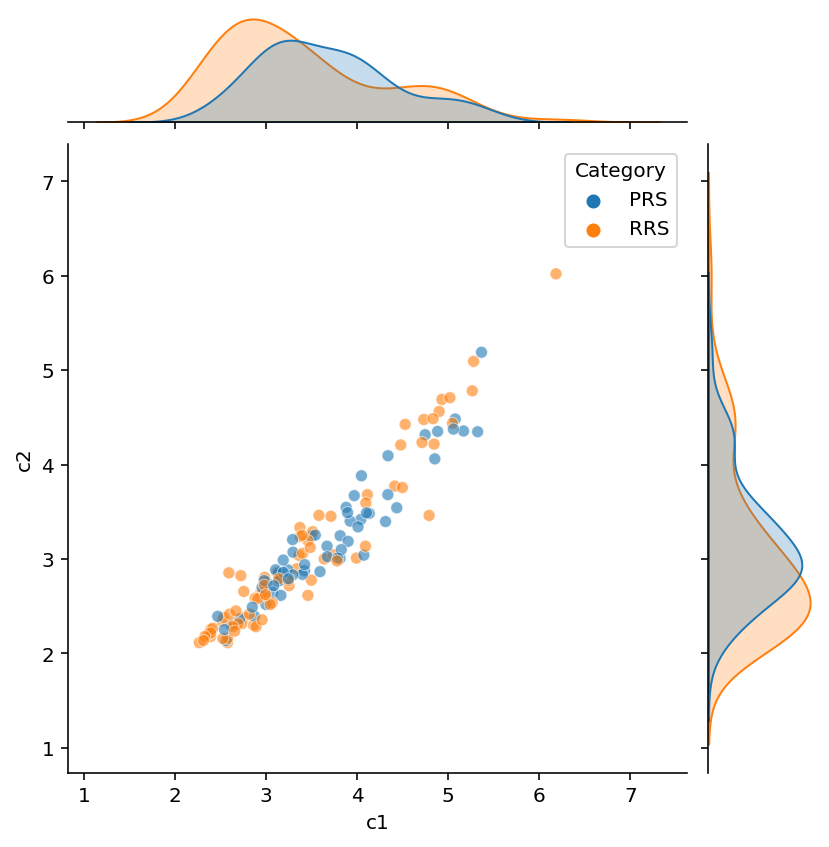

In [91]:
data1 = raw_sg_data.YN2H_N1F2_rep1.apply(np.log10)
data2 = raw_sg_data.YN2H_N1F2_rep2.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data.copy()

df['c1'] = df.YN2H_N1F2_rep1.apply(np.log10)
df['c2'] = df.YN2H_N1F2_rep2.apply(np.log10)

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

pearson (0.9746053267943485, 2.8875993684777007e-90)
spearman SpearmanrResult(correlation=0.969539218193728, pvalue=5.738421310907796e-85)


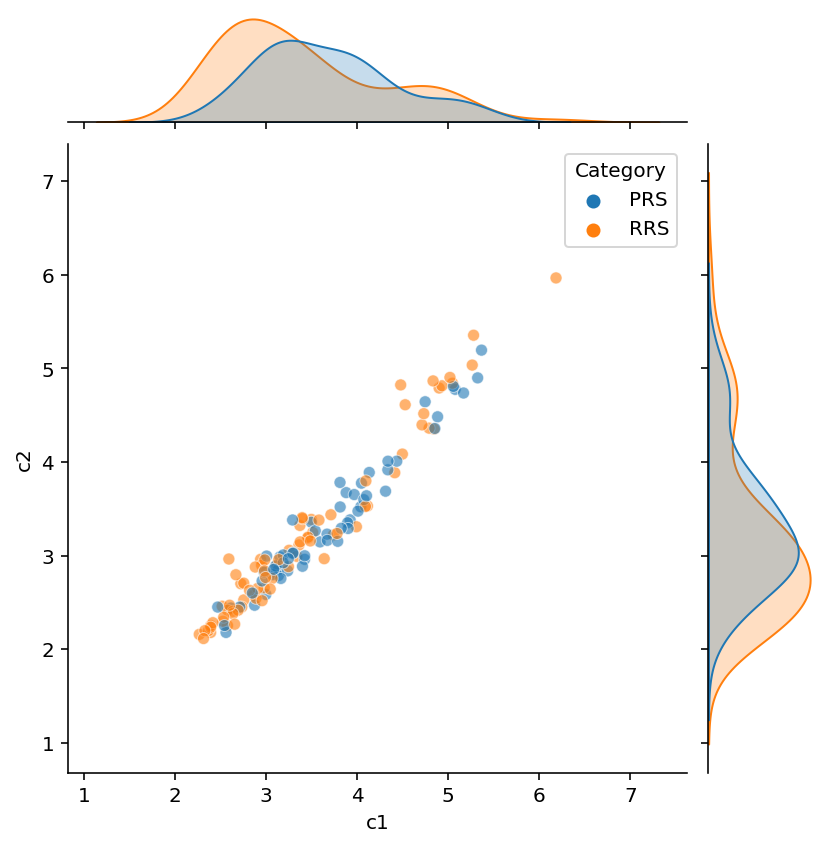

In [92]:
data1 = raw_sg_data.YN2H_N1F2_rep1.apply(np.log10)
data2 = raw_sg_data.YN2H_N1F2_rep3.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data.copy()

df['c1'] = df.YN2H_N1F2_rep1.apply(np.log10)
df['c2'] = df.YN2H_N1F2_rep3.apply(np.log10)

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

pearson (0.9777036321463322, 4.601533373177525e-94)
spearman SpearmanrResult(correlation=0.9700489423994418, pvalue=1.8528728392434697e-85)


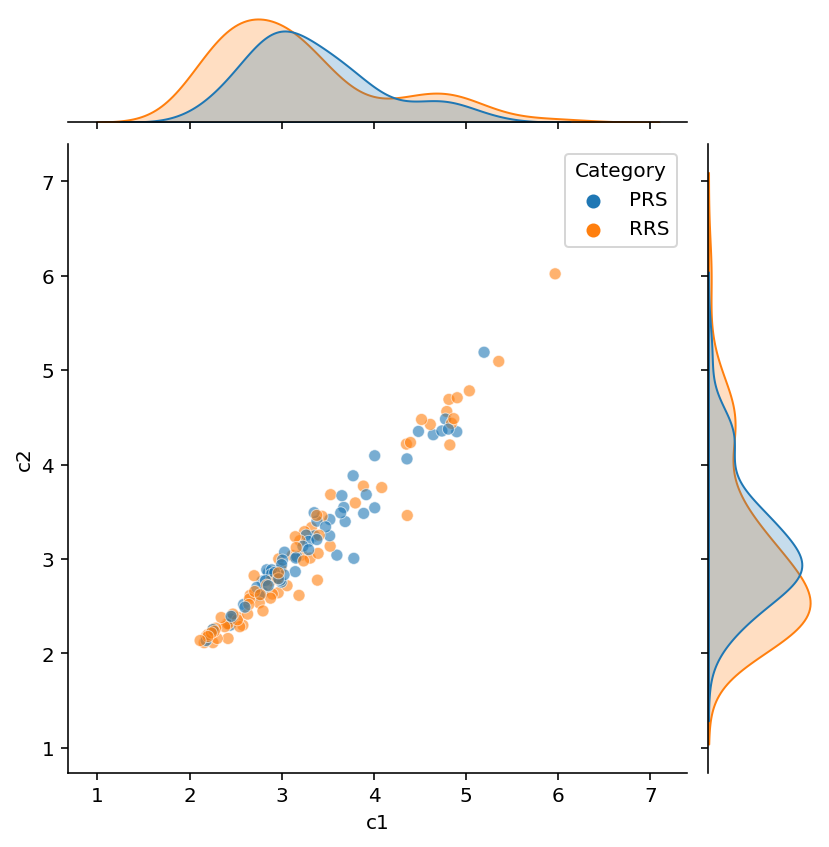

In [93]:
data1 = raw_sg_data.YN2H_N1F2_rep3.apply(np.log10)
data2 = raw_sg_data.YN2H_N1F2_rep2.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data.copy()

df['c1'] = df.YN2H_N1F2_rep3.apply(np.log10)
df['c2'] = df.YN2H_N1F2_rep2.apply(np.log10)

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

pearson (0.93257180114837, 4.815807546614486e-62)
spearman SpearmanrResult(correlation=0.9035002300592941, pvalue=6.841086190381713e-52)


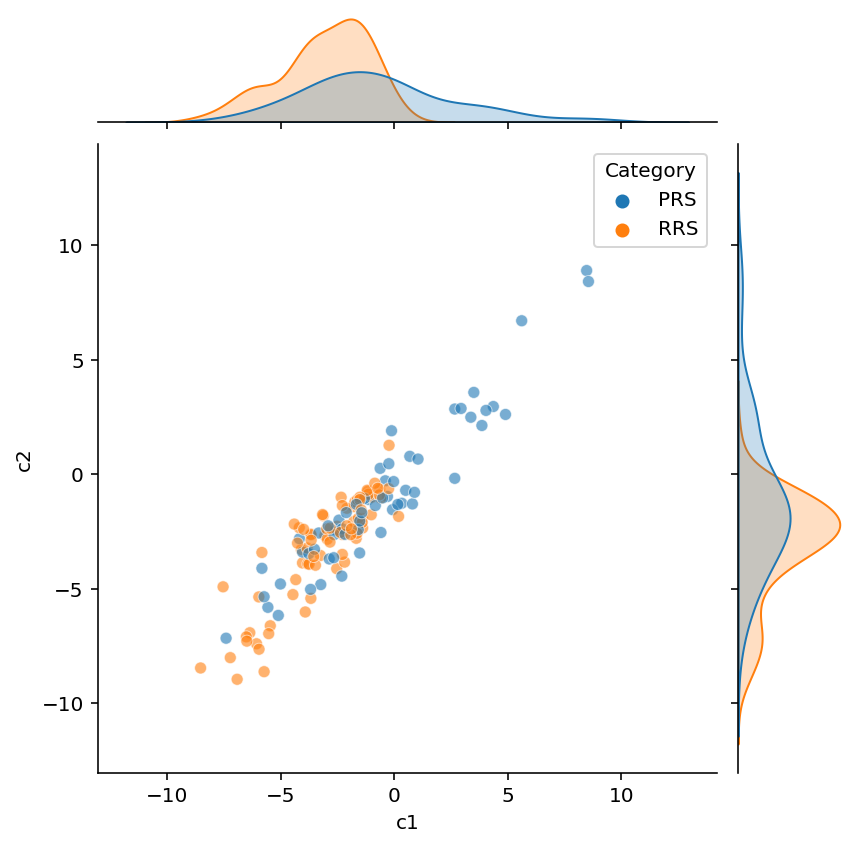

In [94]:
data1 = raw_sg_data.NLR1.apply(np.log10)
data2 = raw_sg_data.NLR2.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data.copy()

df['c1'] = df.NLR1.apply(np.log2)
df['c2'] = df.NLR2.apply(np.log2)

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

In [95]:
# data1 = raw_sg_data.NLD1.apply(np.log10)
# data2 = raw_sg_data.NLD2.apply(np.log10)

# pearson_corr = pearsonr(data1, data2)
# spearman_corr = spearmanr(data1, data2)
# print('pearson',pearson_corr)
# print('spearman',spearman_corr)

# df = raw_sg_data.copy()

# df['c1'] = df.NLD1.apply(np.log2)
# df['c2'] = df.NLD2.apply(np.log2)

# sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

pearson (0.9704542983073694, 3.892248875490041e-08)
spearman SpearmanrResult(correlation=0.9285714285714285, pvalue=4.607427269933694e-06)
PRS    13
Name: Category, dtype: int64


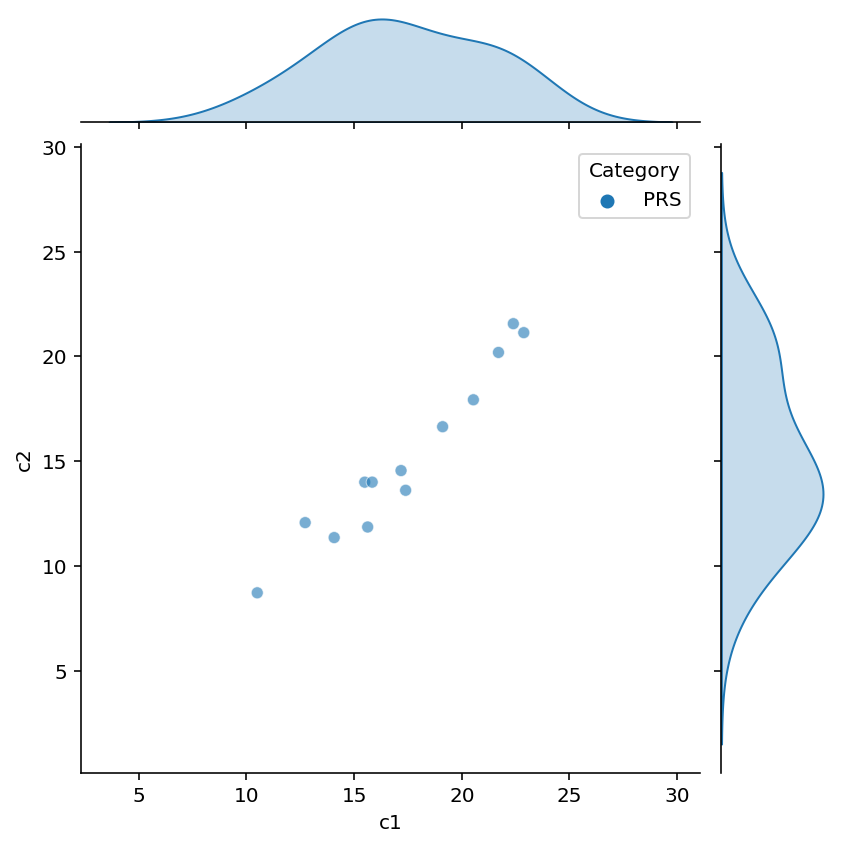

In [96]:
data1 = raw_sg_data[(raw_sg_data.NLD1 > 0.1)&(raw_sg_data.NLD2 > 0.1)].NLD1.apply(np.log10)
data2 = raw_sg_data[(raw_sg_data.NLD1 > 0.1)&(raw_sg_data.NLD2 > 0.1)].NLD2.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data[(raw_sg_data.NLD1 > 0.1)&(raw_sg_data.NLD2 > 0.1)].copy()

df['c1'] = df.NLD1.apply(np.log2)
df['c2'] = df.NLD2.apply(np.log2)

print(df.Category.value_counts())

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

### what drives the RRS signal?

pearson (0.4249059536824474, 0.00010552284457484022)
spearman SpearmanrResult(correlation=0.36185039847542916, pvalue=0.0011329673467544025)


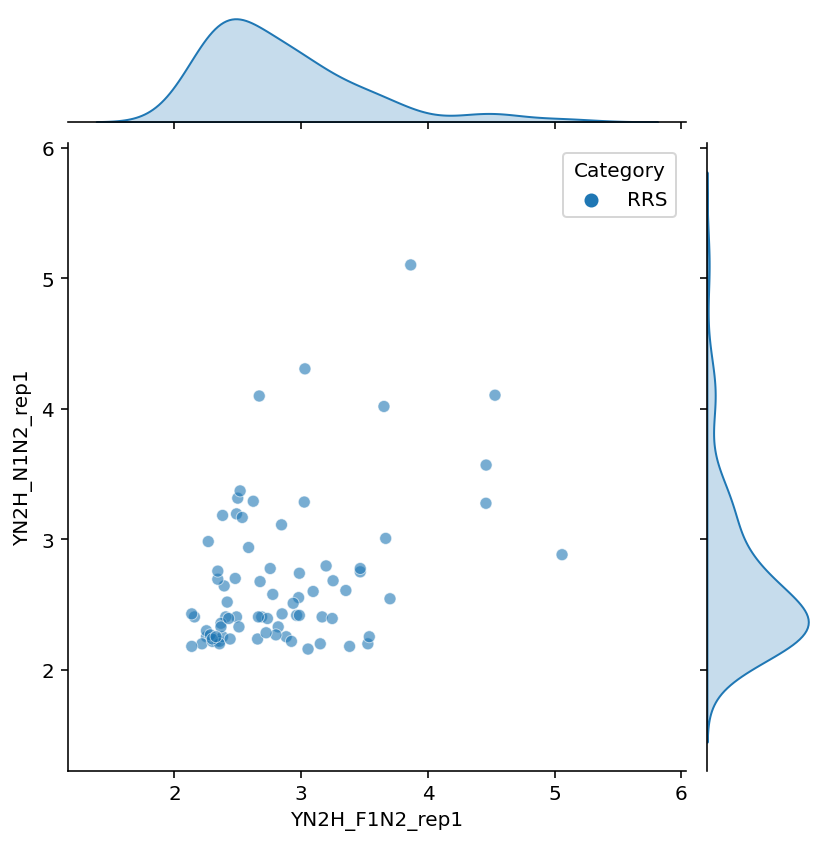

In [97]:
data1 = raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1N2_rep1.apply(np.log10)
data2 = raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_F1N2_rep1.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data[raw_sg_data.Category == 'RRS'].copy()

df['YN2H_N1N2_rep1'] = df.YN2H_N1N2_rep1.apply(np.log10)
df['YN2H_F1N2_rep1'] = df.YN2H_F1N2_rep1.apply(np.log10)

sns.jointplot(data=df, y='YN2H_N1N2_rep1', x='YN2H_F1N2_rep1',alpha=0.6, hue='Category')


pearson (0.6738512579729183, 1.3681007020085846e-11)
spearman SpearmanrResult(correlation=0.675714431420235, pvalue=1.1449702924297821e-11)


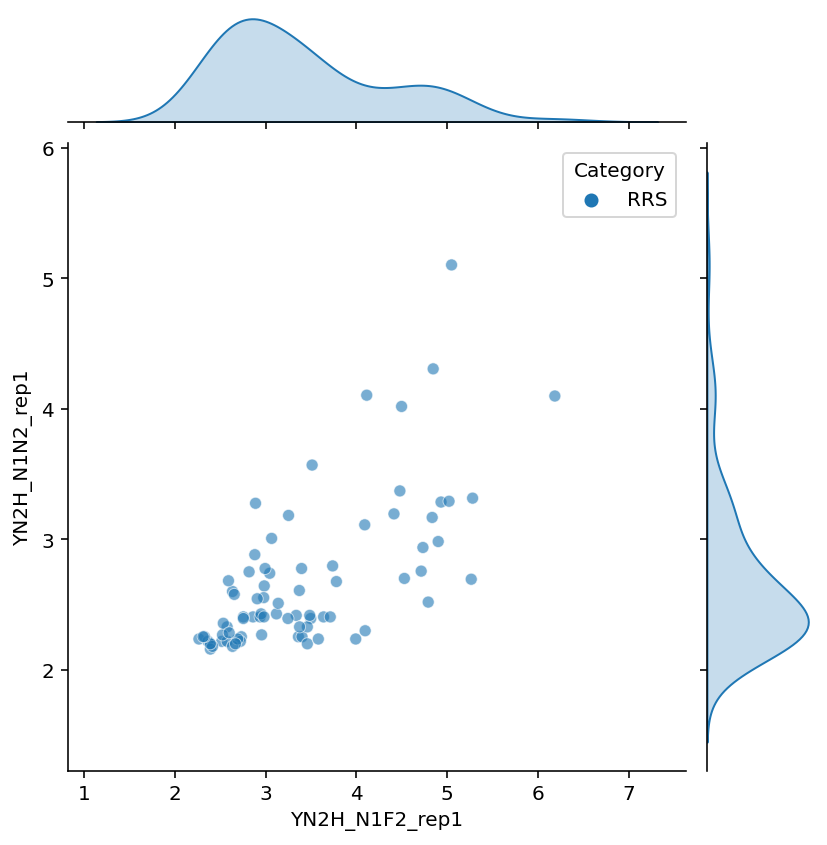

In [98]:
data1 = raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1N2_rep1.apply(np.log10)
data2 = raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1F2_rep1.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data[raw_sg_data.Category == 'RRS'].copy()

df['YN2H_N1N2_rep1'] = df.YN2H_N1N2_rep1.apply(np.log10)
df['YN2H_N1F2_rep1'] = df.YN2H_N1F2_rep1.apply(np.log10)

sns.jointplot(data=df, y='YN2H_N1N2_rep1', x='YN2H_N1F2_rep1',alpha=0.6, hue='Category')

pearson (0.7367861199306611, 1.4800836690459294e-14)
spearman SpearmanrResult(correlation=0.6973429152593009, pvalue=1.3132123440097397e-12)


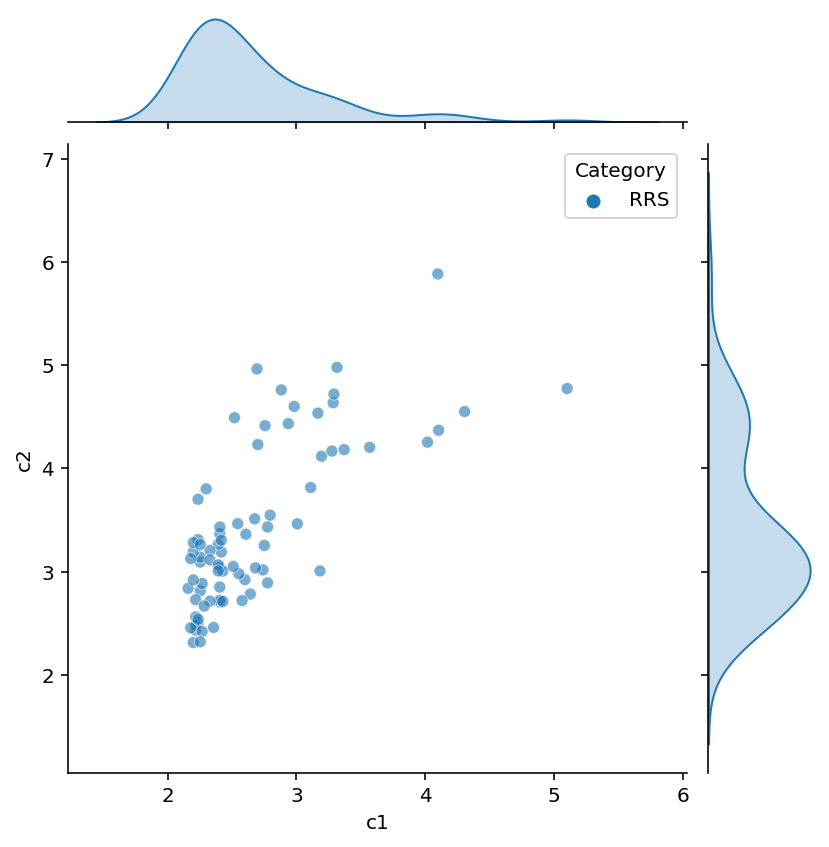

In [99]:
data1 = raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1N2_rep1.apply(np.log10)
data2 = [np.log10(np.mean([f1n2, n1f2])) for f1n2, n1f2 in zip(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_F1N2_rep1, raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1F2_rep1)]

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data[raw_sg_data.Category == 'RRS'].copy()

df['c1'] = df.YN2H_N1N2_rep1.apply(np.log10)
df['c2'] = [np.log10(np.mean([f1n2, n1f2])) for f1n2, n1f2 in zip(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_F1N2_rep1, raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1F2_rep1)]

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

pearson (0.7185390980043439, 1.2957663372964225e-13)
spearman SpearmanrResult(correlation=0.6733837743661588, pvalue=1.430314863577733e-11)


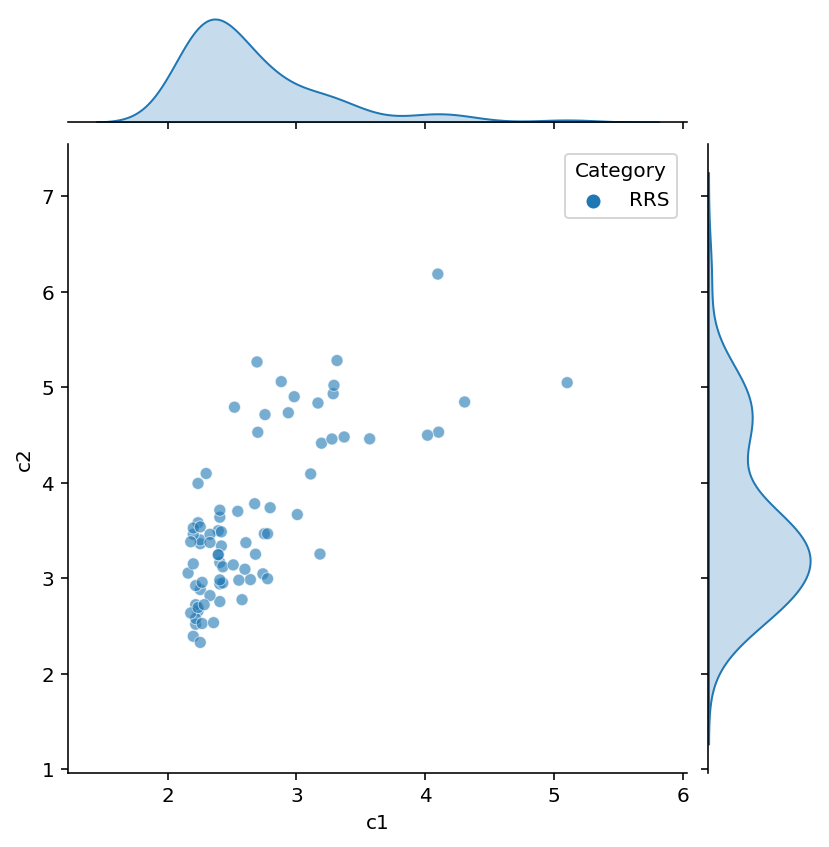

In [100]:
data1 = raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1N2_rep1.apply(np.log10)
data2 = [np.log10(max(f1n2, n1f2)) for f1n2, n1f2 in zip(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_F1N2_rep1, raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1F2_rep1)]

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data[raw_sg_data.Category == 'RRS'].copy()

df['c1'] = df.YN2H_N1N2_rep1.apply(np.log10)
df['c2'] = [np.log10(max(f1n2, n1f2)) for f1n2, n1f2 in zip(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_F1N2_rep1, raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1F2_rep1)]

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

pearson (0.7367861199306611, 1.4800836690459294e-14)
spearman SpearmanrResult(correlation=0.6973429152593009, pvalue=1.3132123440097397e-12)


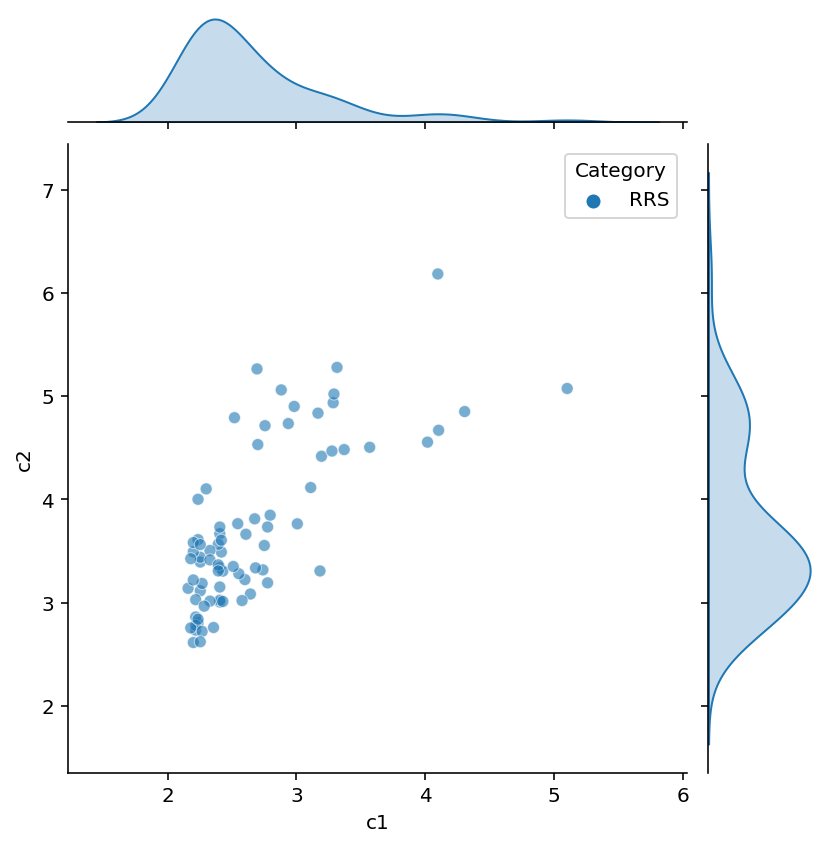

In [101]:
data1 = raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1N2_rep1.apply(np.log10)
data2 = [np.log10(f1n2+n1f2) for f1n2, n1f2 in zip(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_F1N2_rep1, raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1F2_rep1)]

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data[raw_sg_data.Category == 'RRS'].copy()

df['c1'] = df.YN2H_N1N2_rep1.apply(np.log10)
df['c2'] = [np.log10(f1n2+n1f2) for f1n2, n1f2 in zip(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_F1N2_rep1, raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1F2_rep1)]

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

pearson (0.7367861199306611, 1.4800836690459294e-14)
spearman SpearmanrResult(correlation=0.6973429152593009, pvalue=1.3132123440097397e-12)


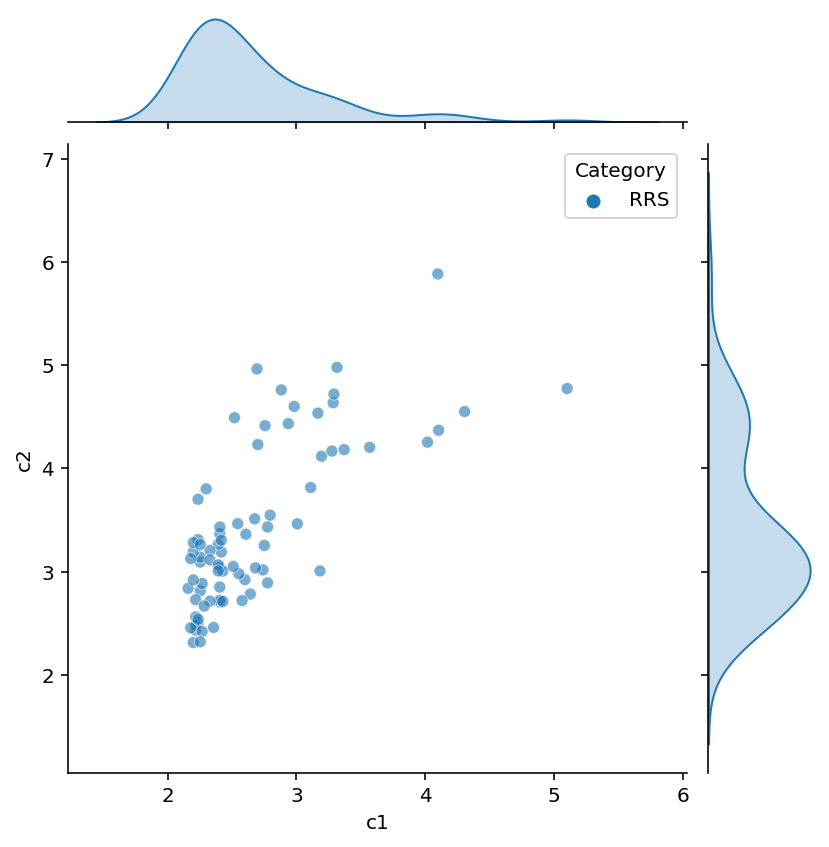

In [155]:
data1 = raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1N2_rep1.apply(np.log10)
data2 = [np.log10((f1n2+n1f2)/2) for f1n2, n1f2 in zip(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_F1N2_rep1, raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1F2_rep1)]

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data[raw_sg_data.Category == 'RRS'].copy()

df['c1'] = df.YN2H_N1N2_rep1.apply(np.log10)
df['c2'] = [np.log10((f1n2+n1f2)/2) for f1n2, n1f2 in zip(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_F1N2_rep1, raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1F2_rep1)]

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

pearson (0.8307140136922522, 5.074160600884896e-21)
spearman SpearmanrResult(correlation=0.7722511923425524, pvalue=1.2472306871844292e-16)


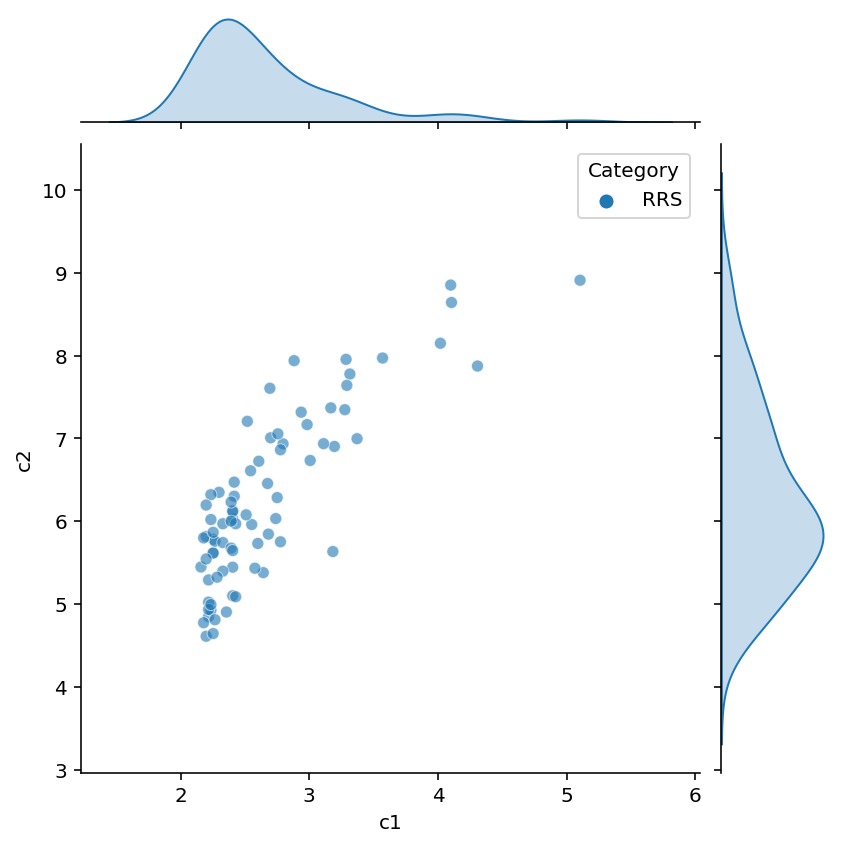

In [102]:
data1 = raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1N2_rep1.apply(np.log10)
data2 = [np.log10(f1n2*n1f2) for f1n2, n1f2 in zip(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_F1N2_rep1, raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1F2_rep1)]

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data[raw_sg_data.Category == 'RRS'].copy()

df['c1'] = df.YN2H_N1N2_rep1.apply(np.log10)
df['c2'] = [np.log10(f1n2*n1f2) for f1n2, n1f2 in zip(raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_F1N2_rep1, raw_sg_data[raw_sg_data.Category == 'RRS'].YN2H_N1F2_rep1)]

sns.jointplot(data=df, x='c1', y='c2',alpha=0.6, hue='Category')

### zscore normalization

In [103]:
raw_sg_data.head()

,Category,Symbol_X,Symbol_Y,YN2H_N1N2_rep1,YN2H_N1N2_rep2,YN2H_N1N2_rep3,YN2H_F1N2_rep1,YN2H_F1N2_rep2,YN2H_F1N2_rep3,YN2H_N1F2_rep1,YN2H_N1F2_rep2,YN2H_N1F2_rep3,NLR1,NLD1,NLDA1,NLDP1,NLRA1,NLRP1,NLR2,NLD2,NLDA2,NLDP2,NLRA2,NLRP2,NLR3,NLD3,NLDA3,NLDP3,NLRA3,NLRP3,avg_NLR,avg_NLD,avg_NLRA,avg_NLDA,pair
0,PRS,LCP2,NCK1,625453,123989,513902,60500,22027,20680,55819,20735,44037,10.338066,564953,509134,-3376424047,5.377049,0.000185,5.628955,101962,81227,-456605856,2.899514,0.000271,11.669778,469865,449185,-910171258,7.940757,0.000564,9.212266,378926.666667,5.405773,346515.333333,"(LCP2, NCK1)"
1,RRS,SHMT2,STAC3,254,117,240,1463,563,391,728,199,378,0.173616,-1209,-1937,-1064810,0.115929,0.000238,0.207815,-446,-645,-111920,0.153543,0.001044,0.613811,-151,-529,-147558,0.312094,0.001624,0.331747,-602.000000,0.193855,-1037.000000,"(SHMT2, STAC3)"
2,RRS,EMD,ARMC1,20268,3962,11915,1071,618,488,69955,16497,22522,0.289729,-49687,-50758,-74901537,0.285360,0.000271,0.240165,-12535,-13153,-10191184,0.231493,0.000389,0.529038,-10607,-11095,-10978821,0.517818,0.001084,0.352977,-24276.333333,0.344890,-25002.000000,"(ARMC1, EMD)"
3,RRS,PDHB,ZC3HC1,254,103,130,309,185,130,4354,1003,927,0.058337,-4100,-4409,-1345132,0.054471,0.000189,0.102692,-900,-1085,-185452,0.086700,0.000555,0.140237,-797,-927,-120380,0.122990,0.001079,0.100422,-1932.333333,0.088054,-2140.333333,"(PDHB, ZC3HC1)"
4,RRS,FKBP3,NQO2,1566,405,453,309,144,185,25902,5920,7685,0.060459,-24336,-24645,-8002152,0.059746,0.000196,0.068412,-5515,-5659,-852075,0.066788,0.000475,0.058946,-7232,-7417,-1421272,0.057560,0.000319,0.062606,-12361.000000,0.061365,-12573.666667,"(FKBP3, NQO2)"


In [104]:
#sns.jointplot(data=raw_sg_data, x='zNLR1', y='zNLR2',alpha=0.6, hue='Category')

### analysis  with Flo Data

<AxesSubplot:ylabel='Frequency'>

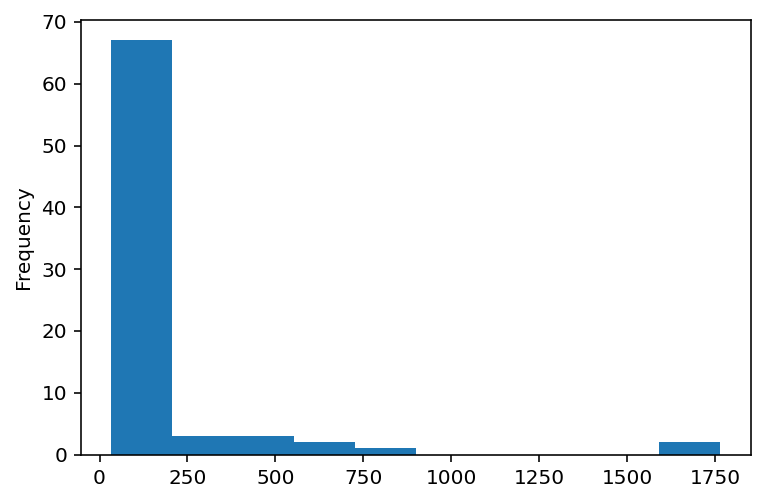

In [105]:
all_dataset[all_dataset.variant_id ==  'RRS'].yN2H_score_rep1.plot.hist()

<AxesSubplot:ylabel='Frequency'>

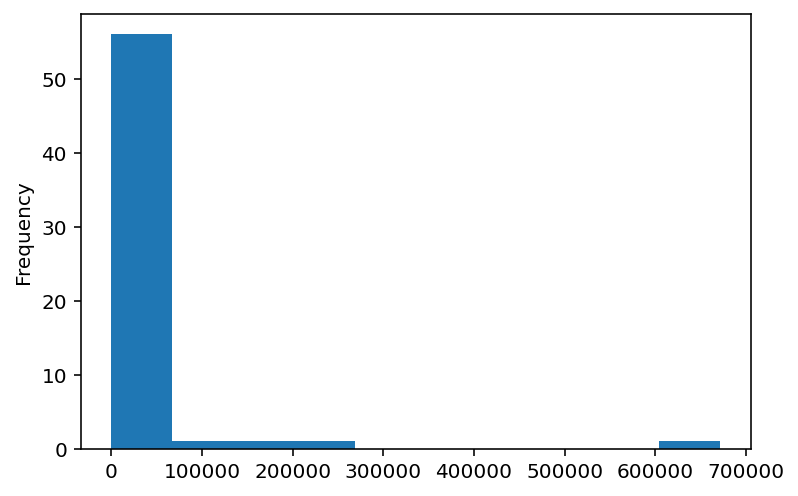

In [106]:
all_dataset[all_dataset.variant_id ==  'PRS'].yN2H_score_rep1.plot.hist()

## Noise over signal

In [107]:
all_dataset.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_well_rep1,empty_well_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,NLR1,NLR2,NLD1,NLD2,detected_r1,detected_r2,detected_NLD1,detected_NLD2,NLR,NLD,pair_x,raw_log2_rep1,raw_log2_rep2,wtpwt_yn2h_raw,wtpwt_en1_raw,wtpwt_en2_raw,wtpwt_nlr,wtpwt_nld,pair_y,YN2H_N1N2_XY,AB_GFP,AF2_GFP,BF1_GFP,AB_old,AF2_old,BF1_old,NLR_old,NLR_GFP,positive_SG,positive_old,positive_GFP,NLR_old_log2,NLR_GFP_log2,NLR_SG_log2
0,1611,SPERT,2713,MLH1,889.0,1,A01,yN2Hapwt,allele,192,165,False,False,137,206,185,137,0.932039,0.891892,-151.0,-157.0,False,False,False,False,0.911965,-154.0,"(1611, 2713)",7.584963,7.366322,165,240,151,0.6875,-75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1611,SPERT,2713,MLH1,4554.0,1,B09,yN2Hapwt,allele,62,69,True,True,48,206,76,137,NaN,NaN,NaN,NaN,False,False,False,False,NaN,NaN,"(1611, 2713)",5.954196,6.108524,165,240,151,0.6875,-75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1611,SPERT,2713,MLH1,200834.0,1,H04,yN2Hapwt,allele,110,137,False,False,288,206,179,137,0.381944,0.765363,-384.0,-179.0,False,False,False,False,0.573654,-281.5,"(1611, 2713)",6.781360,7.098032,165,240,151,0.6875,-75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1611,SPERT,2713,MLH1,200837.0,2,H06,yN2Hapwt,allele,76,69,False,False,151,206,82,137,0.368932,0.503650,-281.0,-150.0,False,False,False,False,0.436291,-215.5,"(1611, 2713)",6.247928,6.108524,165,240,151,0.6875,-75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1611,SPERT,2713,MLH1,472.0,4,F12,yN2Hapwt,allele,110,110,False,False,124,206,137,137,0.533981,0.802920,-220.0,-164.0,False,False,False,False,0.668450,-192.0,"(1611, 2713)",6.781360,6.781360,165,240,151,0.6875,-75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [108]:
all_dataset.variant_id.value_counts()

allele    1786
wt         239
RRS         78
PRS         60
Name: variant_id, dtype: int64

In [109]:
raw_sg_data.columns

Index(['Category', 'Symbol_X', 'Symbol_Y', 'YN2H_N1N2_rep1', 'YN2H_N1N2_rep2',
       'YN2H_N1N2_rep3', 'YN2H_F1N2_rep1', 'YN2H_F1N2_rep2', 'YN2H_F1N2_rep3',
       'YN2H_N1F2_rep1', 'YN2H_N1F2_rep2', 'YN2H_N1F2_rep3', 'NLR1', 'NLD1',
       'NLDA1', 'NLDP1', 'NLRA1', 'NLRP1', 'NLR2', 'NLD2', 'NLDA2', 'NLDP2',
       'NLRA2', 'NLRP2', 'NLR3', 'NLD3', 'NLDA3', 'NLDP3', 'NLRA3', 'NLRP3',
       'avg_NLR', 'avg_NLD', 'avg_NLRA', 'avg_NLDA', 'pair'],
      dtype='object')

In [110]:
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id', 'db_symbol',
        'variant_id',
       'yN2H_score_rep1', 'yN2H_score_rep2', 'empty_N1_rep1', 'empty_N2_rep1',
       'empty_N1_rep2', 'empty_N2_rep2', 'NLR1', 'NLR2', 'NLD1', 'NLD2',
       'NLR',
       'NLD', 'wtpwt_yn2h_raw', 'wtpwt_en1_raw', 'wtpwt_en2_raw',
       'wtpwt_nlr', 'wtpwt_nld']#, 'AB_GFP', 'AF2_GFP','BF1_GFP','NLR_GFP']

wt_df = all_dataset[(all_dataset.variant_id.isin(['wt','RRS','PRS']))&
                 (all_dataset.empty_well_rep1!=True)&
                 (all_dataset.empty_well_rep2!=True)][col].copy()

wt_df['pair'] = [tuple(sorted([ad,db])) for ad,db in zip(wt_df.ad_symbol, wt_df.db_symbol)]

sg_df = raw_sg_data.copy()

sg_df.rename(columns={'NLR1':'sgNLR1', 
                      'NLD1':'sgNLD1',
                      'NLR2':'sgNLR2', 
                      'NLD2':'sgNLD2',
                      'NLR3':'sgNLR3', 
                      'NLD3':'sgNLD3'},inplace=True)

col = ['YN2H_N1N2_rep1', 'YN2H_N1N2_rep2',
       'YN2H_N1N2_rep3', 'YN2H_F1N2_rep1', 'YN2H_F1N2_rep2', 'YN2H_F1N2_rep3',
       'YN2H_N1F2_rep1', 'YN2H_N1F2_rep2', 'YN2H_N1F2_rep3', 'sgNLR1', 'sgNLD1','sgNLR2', 'sgNLD2','sgNLR3', 'sgNLD3','pair']

wt_df = wt_df.merge(sg_df[col],on='pair', how='outer')

wt_df['NLRm_fl'] = [np.mean([s_1/max(n1_1, n2_1),s_2/max(n1_2, n2_2)]) for s_1, s_2, n1_1, n1_2, n2_1, n2_2 in zip(wt_df.yN2H_score_rep1,  wt_df.yN2H_score_rep2, wt_df.empty_N1_rep1, wt_df.empty_N1_rep2, wt_df.empty_N2_rep1, wt_df.empty_N2_rep2)]

wt_df['deltaNLR'] = [abs(v1-v2) for v1,v2 in zip(wt_df.NLR, wt_df.wtpwt_nlr)]
wt_df['deltaNLD'] = [abs(v1-v2) for v1,v2 in zip(wt_df.NLR, wt_df.wtpwt_nlr)]

wt_df['FracDeltaNLR'] = [abs(v1-v2)/max([v1,v2]) for v1,v2 in zip(wt_df.NLR, wt_df.wtpwt_nlr)]
wt_df['FracDeltaNLD'] = [abs(v1-v2)/max([v1,v2]) for v1,v2 in zip(wt_df.NLR, wt_df.wtpwt_nlr)]

wt_df['meanNLR'] = [np.mean([v1,v2]) for v1,v2 in zip(wt_df.NLR, wt_df.wtpwt_nlr)]
wt_df['meanNLD'] = [np.mean([v1,v2]) for v1,v2 in zip(wt_df.NLD, wt_df.wtpwt_nld)]

wt_df['catNLR'] = wt_df.meanNLR.apply(lambda x: 'a0-1' if  x < 1 else 'b1-5' if x <= 5 else 'c6-20' if x <= 20 else 'd21+')
wt_df['catNLD'] = wt_df.meanNLD.apply(lambda x: 'aneg' if  x < 0 else 'b0-1000' if x <= 1000 else 'c1001-5000' if x <= 5000 else 'd5001-50000' if x<= 50000 else 'e50000+')

wt_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,NLR1,NLR2,NLD1,NLD2,NLR,NLD,wtpwt_yn2h_raw,wtpwt_en1_raw,wtpwt_en2_raw,wtpwt_nlr,wtpwt_nld,pair,YN2H_N1N2_rep1,YN2H_N1N2_rep2,YN2H_N1N2_rep3,YN2H_F1N2_rep1,YN2H_F1N2_rep2,YN2H_F1N2_rep3,YN2H_N1F2_rep1,YN2H_N1F2_rep2,YN2H_N1F2_rep3,sgNLR1,sgNLD1,sgNLR2,sgNLD2,sgNLR3,sgNLD3,NLRm_fl,deltaNLR,deltaNLD,FracDeltaNLR,FracDeltaNLD,meanNLR,meanNLD,catNLR,catNLD
0,1611.0,SPERT,2713.0,MLH1,wt,96.0,144.0,165.0,206.0,199.0,137.0,0.466019,0.723618,-275.0,-192.0,0.594819,-233.5,165.0,240.0,151.0,0.687500,-75.0,"(MLH1, SPERT)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.594819,0.092681,0.092681,0.134809,0.134809,0.641159,-154.25,a0-1,aneg
1,11130.0,SLC35E3,4062.0,PLP1,wt,4835.0,2513.0,206.0,460.0,124.0,460.0,10.510870,5.463043,4169.0,1929.0,7.986957,3049.0,2472.0,213.0,700.0,3.531429,1772.0,"(PLP1, SLC35E3)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.986957,4.455528,4.455528,0.557851,0.557851,5.759193,2410.50,c6-20,c1001-5000
2,7515.0,XRCC4,9905.0,PNKP,wt,2204.0,4958.0,1785.0,247.0,1215.0,330.0,1.234734,4.080658,172.0,3413.0,2.657696,1792.5,11819.0,1387.0,426.0,8.521269,10432.0,"(PNKP, XRCC4)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.657696,5.863573,5.863573,0.688110,0.688110,5.589483,6112.25,c6-20,d5001-50000
3,55939.0,FAM9C,4723.0,TPM1,wt,82.0,76.0,172.0,323.0,158.0,460.0,0.253870,0.165217,-413.0,-542.0,0.209544,-477.5,1229.0,179.0,577.0,2.129983,652.0,"(FAM9C, TPM1)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.209544,1.920439,1.920439,0.901622,0.901622,1.169763,87.25,b1-5,b0-1000
4,6552.0,MAGEA8,2713.0,MLH1,wt,11964.0,13660.0,165.0,1490.0,199.0,845.0,8.029530,16.165680,10309.0,12616.0,12.097605,11462.5,22611.0,240.0,852.0,26.538732,21759.0,"(MAGEA8, MLH1)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.097605,14.441127,14.441127,0.544153,0.544153,19.318169,16610.75,c6-20,d5001-50000


In [111]:
wt_df.variant_id.value_counts()

wt     234
RRS     77
PRS     60
Name: variant_id, dtype: int64

In [112]:
np.mean([124/max([63.837329,57.599319]),137/max([57.599319, 4265]) ])

0.9872795409625469

In [113]:
(0.007399+0.027577)/2

0.017488

In [114]:
wt_df.variant_id.value_counts()

wt     234
RRS     77
PRS     60
Name: variant_id, dtype: int64

In [115]:
wt_df.catNLR.value_counts()

a0-1     147
b1-5     147
c6-20     59
d21+      22
Name: catNLR, dtype: int64

In [116]:
wt_df.catNLD.value_counts()

aneg           180
b0-1000        108
d5001-50000     39
c1001-5000      38
e50000+         10
Name: catNLD, dtype: int64

Text(0, 0.5, 'FracDeltaNLR')

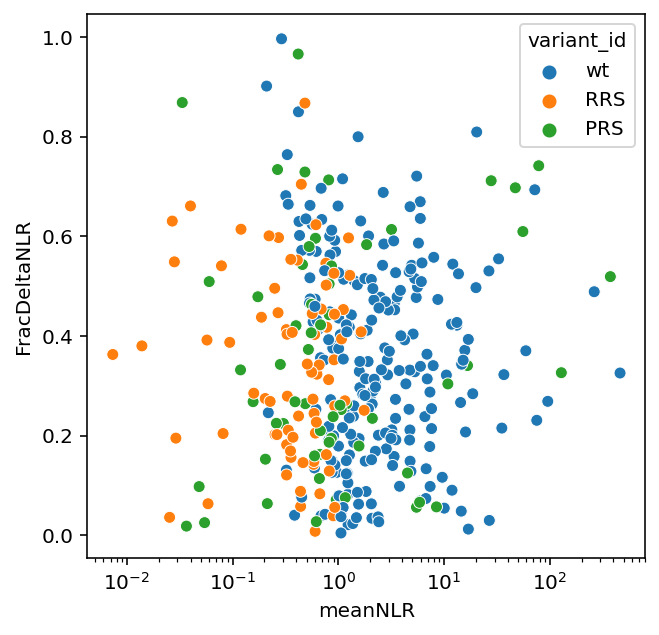

In [117]:
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLR', y='FracDeltaNLR', data=wt_df,hue='variant_id');

plt.xlabel('meanNLR')
plt.xscale('log')
# plt.yscale('log')

plt.ylabel('FracDeltaNLR')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

Text(0, 0.5, 'FracDeltaNLD')

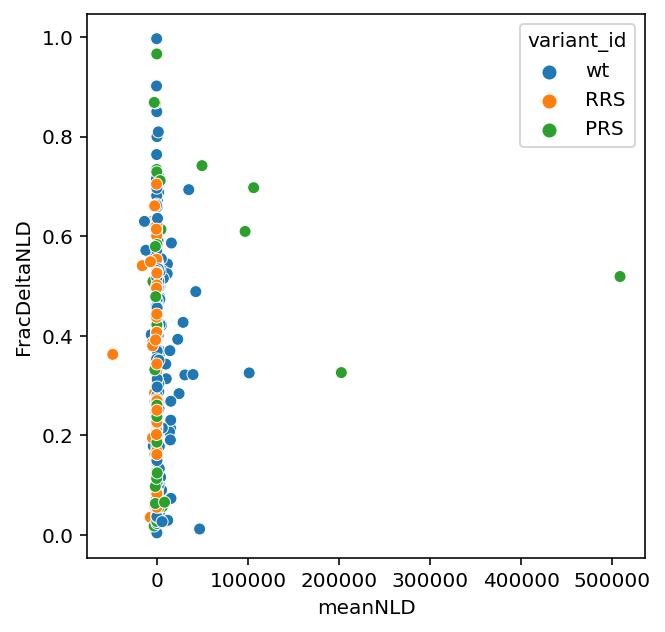

In [118]:
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLD', y='FracDeltaNLD', data=wt_df,hue='variant_id');

plt.xlabel('meanNLD')
#plt.xscale('log')
# plt.yscale('log')

plt.ylabel('FracDeltaNLD')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

Text(0, 0.5, 'deltaNLR')

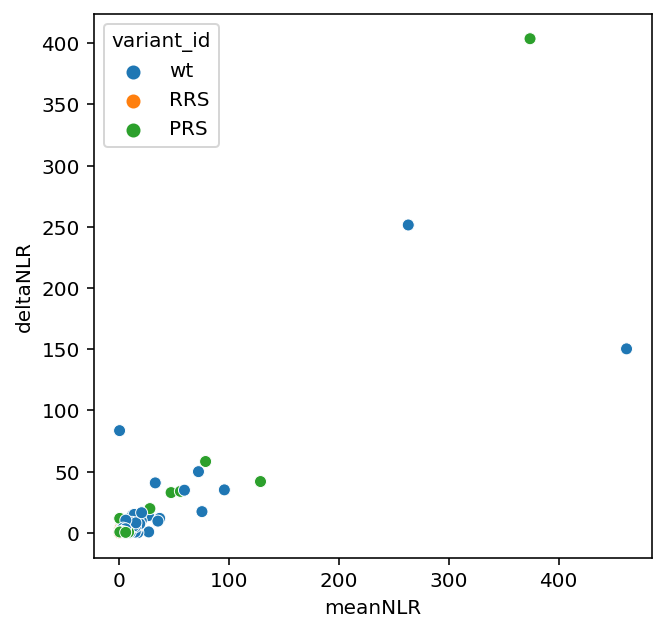

In [119]:
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLR', y='deltaNLR', data=wt_df,hue='variant_id');

plt.xlabel('meanNLR')
# plt.xscale('log')
# plt.yscale('log')

plt.ylabel('deltaNLR')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

Text(0, 0.5, 'deltaNLD')

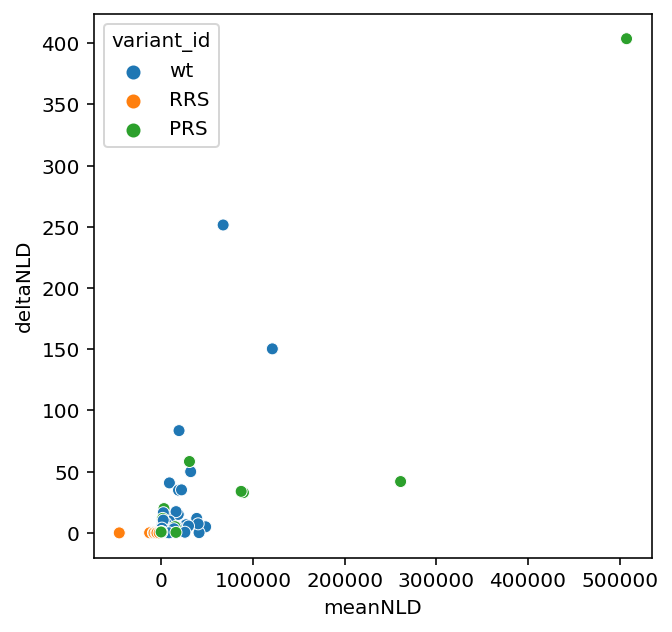

In [120]:
plt.figure(figsize=(5,5))
sns.scatterplot(x='meanNLD', y='deltaNLD', data=wt_df,hue='variant_id');

plt.xlabel('meanNLD')
#plt.xscale('log')
# plt.yscale('log')

plt.ylabel('deltaNLD')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

<AxesSubplot:xlabel='catNLR', ylabel='deltaNLR'>

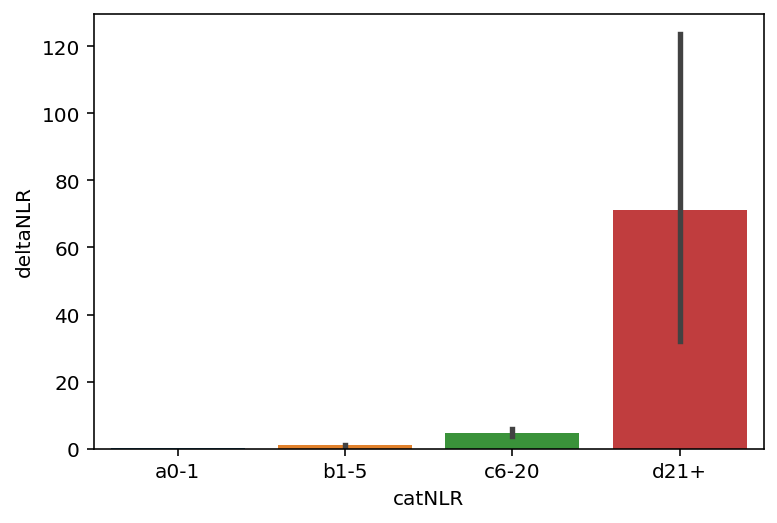

In [121]:
sns.barplot(data=wt_df.sort_values(by='catNLR'), x='catNLR', y ='deltaNLR')

<AxesSubplot:xlabel='catNLD', ylabel='deltaNLD'>

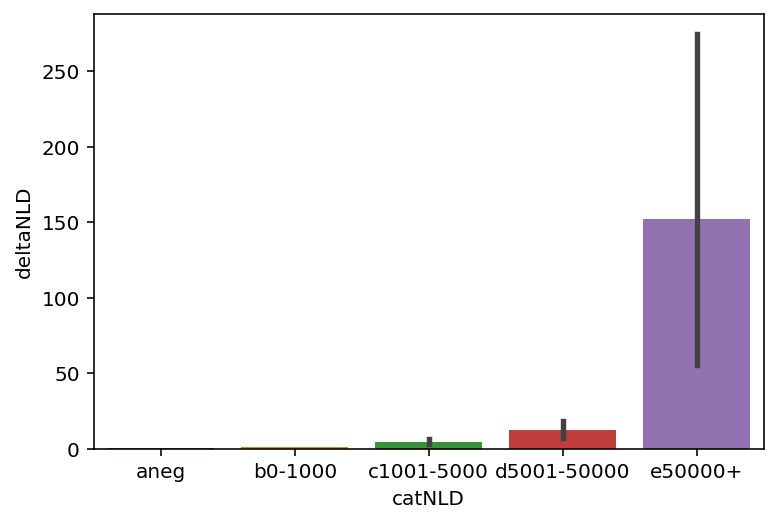

In [122]:
sns.barplot(data=wt_df.sort_values(by='catNLD'), x='catNLD', y ='deltaNLD')

<AxesSubplot:xlabel='catNLR', ylabel='FracDeltaNLR'>

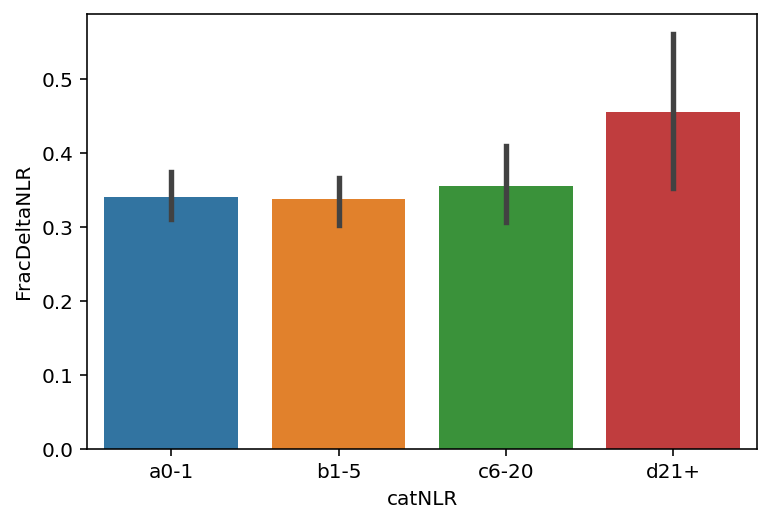

In [123]:
sns.barplot(data=wt_df.sort_values(by='catNLR'), x='catNLR', y ='FracDeltaNLR')

<AxesSubplot:xlabel='catNLD', ylabel='FracDeltaNLD'>

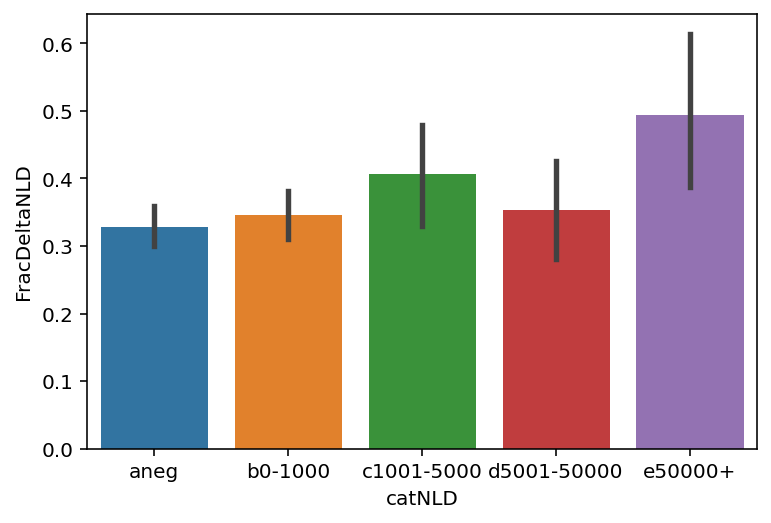

In [124]:
sns.barplot(data=wt_df.sort_values(by='catNLD'), x='catNLD', y ='FracDeltaNLD')

pearson (0.8613256877313599, 3.579733942059728e-70)
spearman SpearmanrResult(correlation=0.822084616928258, pvalue=1.1314688402095981e-58)


Text(0, 0.5, 'wtpwt_nlr')

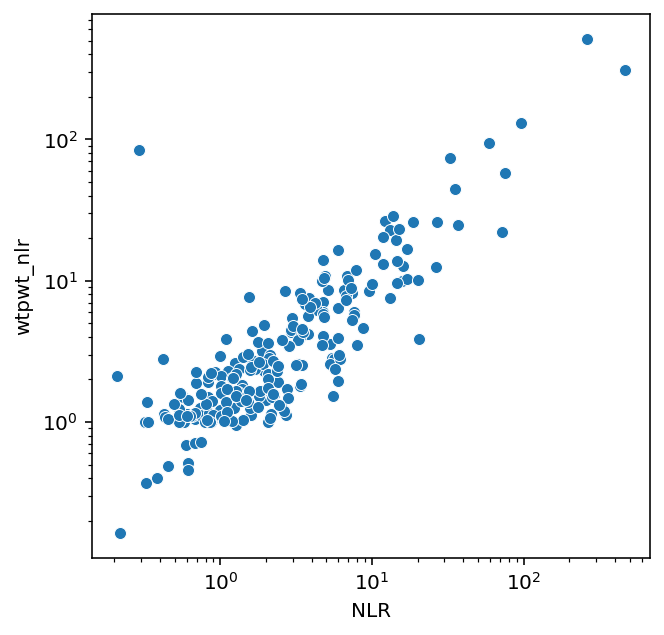

In [125]:
data1 = wt_df[(wt_df.variant_id == 'wt')&(wt_df.NLR>0)&(wt_df.wtpwt_nlr>0)].NLR
data2 = wt_df[(wt_df.variant_id == 'wt')&(wt_df.NLR>0)&(wt_df.wtpwt_nlr>0)].wtpwt_nlr

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLR', y='wtpwt_nlr', data=wt_df[(wt_df.variant_id == 'wt')&(wt_df.NLR>0)&(wt_df.wtpwt_nlr>0)]);


plt.xlabel('NLR')
plt.xscale('log')
plt.yscale('log')

plt.ylabel('wtpwt_nlr')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

In [126]:
wt_df.variant_id.value_counts()

wt     234
RRS     77
PRS     60
Name: variant_id, dtype: int64

In [127]:
wt_df[(wt_df.variant_id != 'wt')].wtpwt_nlr

29       0.072703
45       0.265372
51       0.232353
54       0.607595
76       0.414489
92       2.679012
98       0.114314
99       0.424581
109      0.423077
120      0.691489
128      0.433544
130      0.170638
131      0.052930
135      0.500000
142      0.698266
144    777.751534
145      0.299213
146     10.993930
147      0.026276
153     14.283574
154      0.035893
165      0.300971
167      0.562579
170      0.221661
178      0.500000
182      0.762205
184      0.708155
186      0.057537
187      0.240964
189      0.661290
192      1.000000
194      0.589744
195      0.201079
196      0.503311
202      0.405512
204      0.326633
205      0.185743
208     21.727566
209      0.715278
210     20.307947
211      0.400000
213      0.533981
215      0.011531
216      0.452555
218      0.395833
219      3.643725
220      0.346369
222      0.456954
226      0.130882
233      0.649573
237      0.880342
241      0.245421
242      0.209091
245      0.109458
246      0.395833
249      0

pearson (0.9503889508647373, 2.4686200914352538e-70)
spearman SpearmanrResult(correlation=0.8474123406869815, pvalue=6.12714093813201e-39)


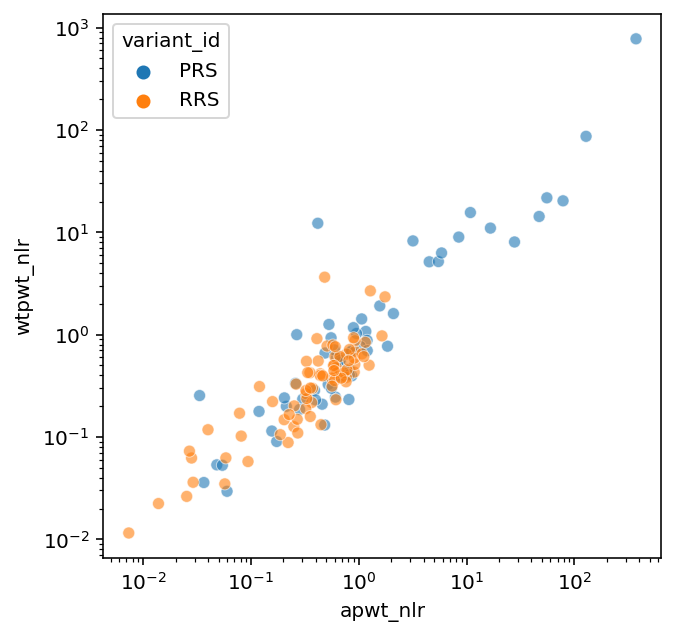

In [128]:
data1 = wt_df[(wt_df.variant_id != 'wt')&(~wt_df.NLR.isnull())&(~wt_df.wtpwt_nlr.isnull())].NLR
data2 = wt_df[(wt_df.variant_id != 'wt')&(~wt_df.NLR.isnull())&(~wt_df.wtpwt_nlr.isnull())].wtpwt_nlr



pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLR', y='wtpwt_nlr', data=wt_df[(wt_df.variant_id != 'wt')].sort_values(by='variant_id'), hue='variant_id',alpha=0.6);


plt.xlabel('apwt_nlr')
plt.xscale('log')
plt.yscale('log')

plt.ylabel('wtpwt_nlr')
plt.savefig('figures/prs_rrs_WTvsAllele_nlr_correlation.pdf')

In [129]:
raw_sg_data.head()

,Category,Symbol_X,Symbol_Y,YN2H_N1N2_rep1,YN2H_N1N2_rep2,YN2H_N1N2_rep3,YN2H_F1N2_rep1,YN2H_F1N2_rep2,YN2H_F1N2_rep3,YN2H_N1F2_rep1,YN2H_N1F2_rep2,YN2H_N1F2_rep3,NLR1,NLD1,NLDA1,NLDP1,NLRA1,NLRP1,NLR2,NLD2,NLDA2,NLDP2,NLRA2,NLRP2,NLR3,NLD3,NLDA3,NLDP3,NLRA3,NLRP3,avg_NLR,avg_NLD,avg_NLRA,avg_NLDA,pair
0,PRS,LCP2,NCK1,625453,123989,513902,60500,22027,20680,55819,20735,44037,10.338066,564953,509134,-3376424047,5.377049,0.000185,5.628955,101962,81227,-456605856,2.899514,0.000271,11.669778,469865,449185,-910171258,7.940757,0.000564,9.212266,378926.666667,5.405773,346515.333333,"(LCP2, NCK1)"
1,RRS,SHMT2,STAC3,254,117,240,1463,563,391,728,199,378,0.173616,-1209,-1937,-1064810,0.115929,0.000238,0.207815,-446,-645,-111920,0.153543,0.001044,0.613811,-151,-529,-147558,0.312094,0.001624,0.331747,-602.000000,0.193855,-1037.000000,"(SHMT2, STAC3)"
2,RRS,EMD,ARMC1,20268,3962,11915,1071,618,488,69955,16497,22522,0.289729,-49687,-50758,-74901537,0.285360,0.000271,0.240165,-12535,-13153,-10191184,0.231493,0.000389,0.529038,-10607,-11095,-10978821,0.517818,0.001084,0.352977,-24276.333333,0.344890,-25002.000000,"(ARMC1, EMD)"
3,RRS,PDHB,ZC3HC1,254,103,130,309,185,130,4354,1003,927,0.058337,-4100,-4409,-1345132,0.054471,0.000189,0.102692,-900,-1085,-185452,0.086700,0.000555,0.140237,-797,-927,-120380,0.122990,0.001079,0.100422,-1932.333333,0.088054,-2140.333333,"(PDHB, ZC3HC1)"
4,RRS,FKBP3,NQO2,1566,405,453,309,144,185,25902,5920,7685,0.060459,-24336,-24645,-8002152,0.059746,0.000196,0.068412,-5515,-5659,-852075,0.066788,0.000475,0.058946,-7232,-7417,-1421272,0.057560,0.000319,0.062606,-12361.000000,0.061365,-12573.666667,"(FKBP3, NQO2)"


pearson (0.93257180114837, 4.815807546614486e-62)
spearman SpearmanrResult(correlation=0.9035002300592941, pvalue=6.841086190381713e-52)


<AxesSubplot:xlabel='NLR1', ylabel='NLR2'>

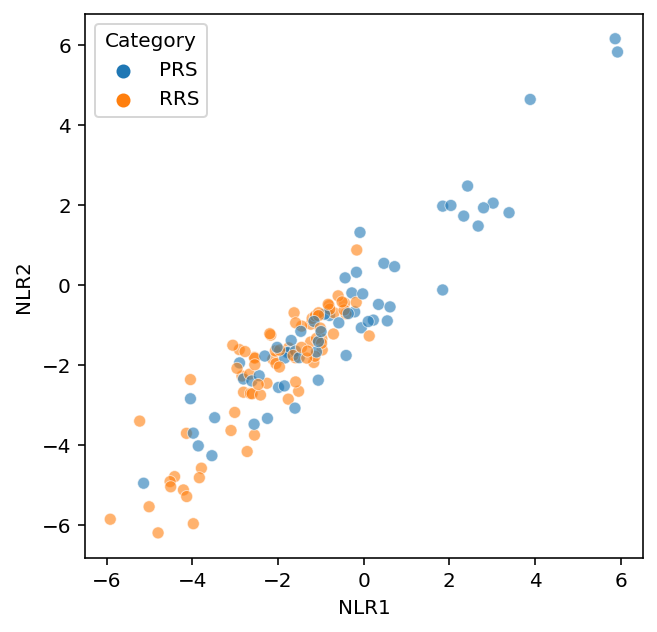

In [130]:
data1 = raw_sg_data.NLR1.apply(np.log10)
data2 = raw_sg_data.NLR2.apply(np.log10)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

df = raw_sg_data.copy()

df['NLR1'] = df.NLR1.apply(np.log)
df['NLR2'] = df.NLR2.apply(np.log)
plt.figure(figsize=(5,5))
sns.scatterplot(data=df, x='NLR1', y='NLR2',alpha=0.6, hue='Category')

In [131]:
wt_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,NLR1,NLR2,NLD1,NLD2,NLR,NLD,wtpwt_yn2h_raw,wtpwt_en1_raw,wtpwt_en2_raw,wtpwt_nlr,wtpwt_nld,pair,YN2H_N1N2_rep1,YN2H_N1N2_rep2,YN2H_N1N2_rep3,YN2H_F1N2_rep1,YN2H_F1N2_rep2,YN2H_F1N2_rep3,YN2H_N1F2_rep1,YN2H_N1F2_rep2,YN2H_N1F2_rep3,sgNLR1,sgNLD1,sgNLR2,sgNLD2,sgNLR3,sgNLD3,NLRm_fl,deltaNLR,deltaNLD,FracDeltaNLR,FracDeltaNLD,meanNLR,meanNLD,catNLR,catNLD
0,1611.0,SPERT,2713.0,MLH1,wt,96.0,144.0,165.0,206.0,199.0,137.0,0.466019,0.723618,-275.0,-192.0,0.594819,-233.5,165.0,240.0,151.0,0.687500,-75.0,"(MLH1, SPERT)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.594819,0.092681,0.092681,0.134809,0.134809,0.641159,-154.25,a0-1,aneg
1,11130.0,SLC35E3,4062.0,PLP1,wt,4835.0,2513.0,206.0,460.0,124.0,460.0,10.510870,5.463043,4169.0,1929.0,7.986957,3049.0,2472.0,213.0,700.0,3.531429,1772.0,"(PLP1, SLC35E3)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.986957,4.455528,4.455528,0.557851,0.557851,5.759193,2410.50,c6-20,c1001-5000
2,7515.0,XRCC4,9905.0,PNKP,wt,2204.0,4958.0,1785.0,247.0,1215.0,330.0,1.234734,4.080658,172.0,3413.0,2.657696,1792.5,11819.0,1387.0,426.0,8.521269,10432.0,"(PNKP, XRCC4)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.657696,5.863573,5.863573,0.688110,0.688110,5.589483,6112.25,c6-20,d5001-50000
3,55939.0,FAM9C,4723.0,TPM1,wt,82.0,76.0,172.0,323.0,158.0,460.0,0.253870,0.165217,-413.0,-542.0,0.209544,-477.5,1229.0,179.0,577.0,2.129983,652.0,"(FAM9C, TPM1)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.209544,1.920439,1.920439,0.901622,0.901622,1.169763,87.25,b1-5,b0-1000
4,6552.0,MAGEA8,2713.0,MLH1,wt,11964.0,13660.0,165.0,1490.0,199.0,845.0,8.029530,16.165680,10309.0,12616.0,12.097605,11462.5,22611.0,240.0,852.0,26.538732,21759.0,"(MAGEA8, MLH1)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.097605,14.441127,14.441127,0.544153,0.544153,19.318169,16610.75,c6-20,d5001-50000


pearson (0.8843744458247734, 1.6439336351469255e-45)
spearman SpearmanrResult(correlation=0.7131984189329045, pvalue=4.132669417530103e-22)


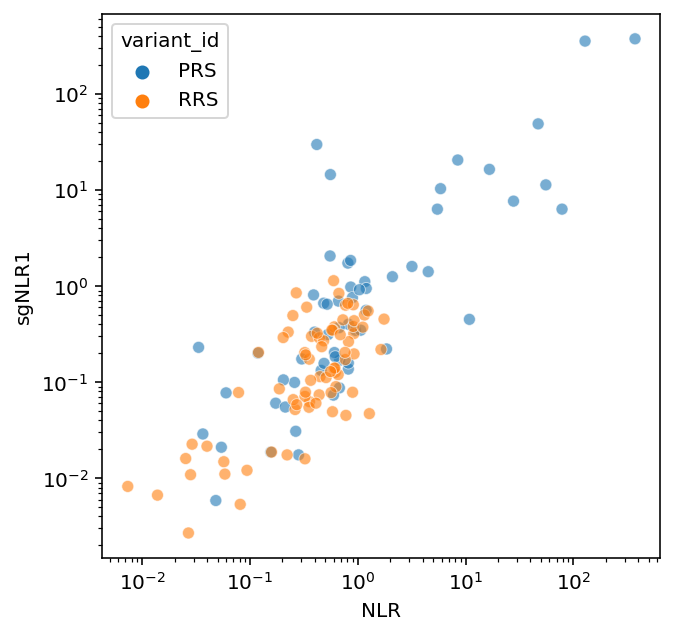

In [132]:
data1 = wt_df[(wt_df.variant_id != 'wt')&(~wt_df.NLR.isnull())&(~wt_df.sgNLR1.isnull())].NLR
data2 = wt_df[(wt_df.variant_id != 'wt')&(~wt_df.NLR.isnull())&(~wt_df.sgNLR1.isnull())].sgNLR1

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLR', y='sgNLR1', data=wt_df[(wt_df.variant_id != 'wt')&(~wt_df.NLR.isnull())&(~wt_df.sgNLR1.isnull())].sort_values(by='variant_id'), hue='variant_id',alpha=0.6);


#plt.xlabel('apwt_nlr')
plt.xscale('log')
plt.yscale('log')

plt.ylabel('sgNLR1')
plt.savefig('figures/prs_rrs_WTvsSGr1_correlation.pdf')

In [133]:
wt_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,variant_id,yN2H_score_rep1,yN2H_score_rep2,empty_N1_rep1,empty_N2_rep1,empty_N1_rep2,empty_N2_rep2,NLR1,NLR2,NLD1,NLD2,NLR,NLD,wtpwt_yn2h_raw,wtpwt_en1_raw,wtpwt_en2_raw,wtpwt_nlr,wtpwt_nld,pair,YN2H_N1N2_rep1,YN2H_N1N2_rep2,YN2H_N1N2_rep3,YN2H_F1N2_rep1,YN2H_F1N2_rep2,YN2H_F1N2_rep3,YN2H_N1F2_rep1,YN2H_N1F2_rep2,YN2H_N1F2_rep3,sgNLR1,sgNLD1,sgNLR2,sgNLD2,sgNLR3,sgNLD3,NLRm_fl,deltaNLR,deltaNLD,FracDeltaNLR,FracDeltaNLD,meanNLR,meanNLD,catNLR,catNLD
0,1611.0,SPERT,2713.0,MLH1,wt,96.0,144.0,165.0,206.0,199.0,137.0,0.466019,0.723618,-275.0,-192.0,0.594819,-233.5,165.0,240.0,151.0,0.687500,-75.0,"(MLH1, SPERT)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.594819,0.092681,0.092681,0.134809,0.134809,0.641159,-154.25,a0-1,aneg
1,11130.0,SLC35E3,4062.0,PLP1,wt,4835.0,2513.0,206.0,460.0,124.0,460.0,10.510870,5.463043,4169.0,1929.0,7.986957,3049.0,2472.0,213.0,700.0,3.531429,1772.0,"(PLP1, SLC35E3)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.986957,4.455528,4.455528,0.557851,0.557851,5.759193,2410.50,c6-20,c1001-5000
2,7515.0,XRCC4,9905.0,PNKP,wt,2204.0,4958.0,1785.0,247.0,1215.0,330.0,1.234734,4.080658,172.0,3413.0,2.657696,1792.5,11819.0,1387.0,426.0,8.521269,10432.0,"(PNKP, XRCC4)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.657696,5.863573,5.863573,0.688110,0.688110,5.589483,6112.25,c6-20,d5001-50000
3,55939.0,FAM9C,4723.0,TPM1,wt,82.0,76.0,172.0,323.0,158.0,460.0,0.253870,0.165217,-413.0,-542.0,0.209544,-477.5,1229.0,179.0,577.0,2.129983,652.0,"(FAM9C, TPM1)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.209544,1.920439,1.920439,0.901622,0.901622,1.169763,87.25,b1-5,b0-1000
4,6552.0,MAGEA8,2713.0,MLH1,wt,11964.0,13660.0,165.0,1490.0,199.0,845.0,8.029530,16.165680,10309.0,12616.0,12.097605,11462.5,22611.0,240.0,852.0,26.538732,21759.0,"(MAGEA8, MLH1)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.097605,14.441127,14.441127,0.544153,0.544153,19.318169,16610.75,c6-20,d5001-50000


In [134]:
wt_df.variant_id.value_counts()

wt     234
RRS     77
PRS     60
Name: variant_id, dtype: int64

pearson (0.9343380315846374, 2.6436972677200494e-58)
spearman SpearmanrResult(correlation=0.9158962737915071, pvalue=8.733593519563629e-52)


Text(0, 0.5, 'wtpwt_nld')

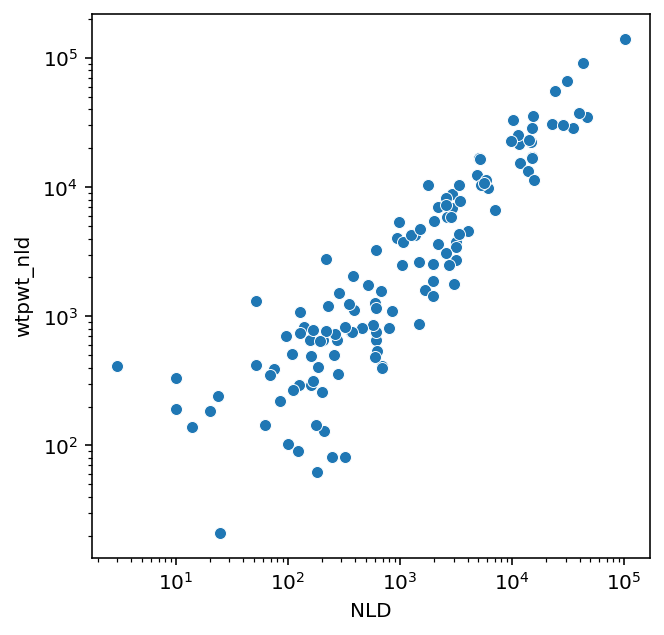

In [135]:
data1 = wt_df[(wt_df.variant_id == 'wt')&(wt_df.NLD>0)&(wt_df.wtpwt_nld>0)].NLD
data2 = wt_df[(wt_df.variant_id == 'wt')&(wt_df.NLD>0)&(wt_df.wtpwt_nld>0)].wtpwt_nld

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLD', y='wtpwt_nld', data=wt_df[(wt_df.variant_id == 'wt')&(wt_df.NLD>0)&(wt_df.wtpwt_nld>0)]);


plt.xlabel('NLD')
plt.xscale('log')
plt.yscale('log')

plt.ylabel('wtpwt_nld')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

## yN2H normalization vs LuTHy

In [136]:
prs_rrs_raw_old26_df = pd.read_excel('../../../MasterThesis_Gaspard/data/hsPRS_RRS-v2-all assays.xlsx', skiprows=1)
PRS_RRS_cat_d = dict(zip(prs_rrs_raw_old26_df.Linked, prs_rrs_raw_old26_df.Category))
prs_rrs_raw_df = pd.read_csv('../../../MasterThesis_Gaspard/data/Assayome 42 assay versions.csv', sep=',')
prs_rrs_raw_df['Category'] = prs_rrs_raw_df.Gene.map(PRS_RRS_cat_d)
prs_rrs_raw_df.rename(columns={c:'_'.join(w for w in c.replace('-','_').split()) for c in prs_rrs_raw_df.columns}, inplace=True)
prs_rrs_raw_df.head()

,Gene,cBRET_N1N2_XY,cBRET_N1C2_XY,cBRET_C1N2_XY,cBRET_C1C2_XY,cBRET_N1N2_YX,cBRET_N1C2_YX,cBRET_C1N2_YX,cBRET_C1C2_YX,cLuC_N1N2_XY,cLuC_N1C2_XY,cLuC_C1N2_XY,cLuC_C1C2_XY,cLuC_N1N2_YX,cLuC_C1N2_YX,cLuC_N1C2_YX,cLuC_C1C2_YX,Y2H_N1N2_XY,Y2H_N1N2_YX,MAPPIT_N1N2_XY,MAPPIT_N1N2_YX,KISS_N1N2_XY,KISS_N1C2_XY,NanoBiT_N1N2_XY,NanoBiT_C1C2_XY,NanoBiT_N1C2_XY,NanoBiT_C1N2_XY,GPCA_N1N2_XY,GPCA_C1C2_XY,GPCA_N1C2_XY,GPCA_C1N2_XY,YN2H_N1N2_XY,YN2H_C1C2_XY,YN2H_N1C2_XY,YN2H_C1N2_XY,MN2H_N1N2_XY,MN2H_C1C2_XY,MN2H_N1C2_XY,MN2H_C1N2_XY,VN2H_N1N2_XY,VN2H_C1C2_XY,VN2H_N1C2_XY,VN2H_C1N2_XY,Category
0,LCP2+NCK1,-0.4103,-0.4745,-0.2690,-0.8350,-0.5398,-1.5568,-0.5803,-0.2830,-0.2955,-0.3742,-0.3540,-0.3690,-0.3967,-0.3305,-0.3532,-0.2904,-0.3065,-0.2923,-0.2826,-0.2370,-0.2308,0.4405,-0.2420,-0.2725,-0.2270,-0.2296,-0.2606,-0.3152,-0.2687,-0.2799,0.0520,0.5481,0.3068,0.1101,-0.2172,-0.2282,-0.1991,-0.2041,1.7948,0.0444,3.8768,0.1704,PRS
1,LCP2+GRAP2,0.6395,1.9487,0.6675,1.6086,0.4949,0.9931,0.2389,0.6432,0.3820,1.9108,1.6136,2.8257,0.3472,0.3394,0.0463,-0.0676,3.2179,-0.2923,0.4316,-0.2702,-0.3208,-0.1359,-0.2420,-0.1583,-0.0130,-0.2231,0.2157,0.5686,3.5076,2.7149,-0.1094,-0.0207,0.2410,-0.1024,0.6125,0.7454,0.5372,0.5606,0.4325,-0.0687,2.9013,-0.1924,PRS
2,LSM3+LSM2,5.9142,8.1645,7.6331,6.8810,5.3733,7.8651,3.7128,5.2898,1.6134,2.9846,3.4506,3.5430,2.6076,5.2261,4.5667,2.0423,3.2179,3.3742,8.3894,7.2090,3.1449,6.2960,0.1181,1.1224,-0.0316,5.3532,0.5281,1.0751,2.2879,1.9297,0.0012,0.2928,4.3892,-0.0688,0.2476,0.3227,0.9361,0.0729,3.0408,0.7131,1.1883,0.5261,PRS
3,IFIT1+EIF3E,-0.7900,-0.7920,NaN,NaN,-0.6415,-1.3403,-0.7140,-0.3990,-0.2955,-0.3722,NaN,NaN,-0.3016,-0.3300,-0.2623,-0.2904,-0.3065,-0.2923,-0.2941,-0.2472,-0.2217,-0.1051,-0.2389,-0.2696,-0.2270,-0.2309,-0.2695,-0.3151,-0.2676,-0.2824,-0.1514,-0.1060,-0.0787,-0.1309,-0.2796,-0.2314,-0.2027,-0.2697,-0.5131,-0.1641,-0.3865,-0.2431,PRS
4,PSMD4+RAD23A,0.6412,-0.2221,0.7230,-0.3891,-0.1840,-0.2349,-0.1898,-0.4047,-0.2150,-0.3722,-0.3145,-0.3250,-0.3016,-0.3300,-0.2623,-0.2802,-0.3065,-0.2923,-0.3061,-0.1457,-0.1754,-0.3914,-0.1908,-0.2652,-0.4130,-0.2218,-0.1994,-0.3100,-0.2639,-0.0589,-0.1313,-0.1329,-0.2668,0.1613,0.9954,-0.1794,-0.1460,1.2245,4.8518,2.0832,3.5596,6.2446,PRS


In [137]:
xp_data_columns = ['cBRET_N1N2_XY', 'cBRET_N1C2_XY', 'cBRET_C1N2_XY',
       'cBRET_C1C2_XY', 'cBRET_N1N2_YX', 'cBRET_N1C2_YX', 'cBRET_C1N2_YX',
       'cBRET_C1C2_YX', 'cLuC_N1N2_XY', 'cLuC_N1C2_XY', 'cLuC_C1N2_XY',
       'cLuC_C1C2_XY', 'cLuC_N1N2_YX', 'cLuC_C1N2_YX', 'cLuC_N1C2_YX',
       'cLuC_C1C2_YX', 'Y2H_N1N2_XY', 'Y2H_N1N2_YX', 'MAPPIT_N1N2_XY',
       'MAPPIT_N1N2_YX', 'KISS_N1N2_XY', 'KISS_N1C2_XY', 'NanoBiT_N1N2_XY',
       'NanoBiT_C1C2_XY', 'NanoBiT_N1C2_XY', 'NanoBiT_C1N2_XY', 'GPCA_N1N2_XY',
       'GPCA_C1C2_XY', 'GPCA_N1C2_XY', 'GPCA_C1N2_XY', 'YN2H_N1N2_XY',
       'YN2H_C1C2_XY', 'YN2H_N1C2_XY', 'YN2H_C1N2_XY', 'MN2H_N1N2_XY',
       'MN2H_C1C2_XY', 'MN2H_N1C2_XY', 'MN2H_C1N2_XY', 'VN2H_N1N2_XY',
       'VN2H_C1C2_XY', 'VN2H_N1C2_XY', 'VN2H_C1N2_XY']

RRS_max_value_d = dict()
for column in xp_data_columns:
    
    
    rrs_raw_data = prs_rrs_raw_df[prs_rrs_raw_df.Category == 'RRS'][column].tolist()
    rrs_raw_data = [elem for elem in rrs_raw_data if type(elem) != str]
    
    max_RRS_value = max(rrs_raw_data)
    RRS_max_value_d[column] = max_RRS_value

PRS_max_value_d = dict()
for column in xp_data_columns:
    
    
    prs_raw_data = prs_rrs_raw_df[prs_rrs_raw_df.Category == 'PRS'][column].tolist()
    prs_raw_data = [elem for elem in prs_raw_data if type(elem) != str]
    
    max_PRS_value = max(prs_raw_data)
    PRS_max_value_d[column] = max_PRS_value

In [138]:
PRS_normalized = prs_rrs_raw_df[prs_rrs_raw_df.Category == 'PRS'].copy()

def normalize_assay_raw_data(values, assay_name, PRS_max_value_d, RRS_max_value_d):
    
    max_prs_val = PRS_max_value_d[assay_name]
    max_rrs_val = RRS_max_value_d[assay_name]
    
    values = [val if val != 'n.e.' and val > max_rrs_val  else max_rrs_val for val in values]
    values = [(val - max_rrs_val) / (max_prs_val - max_rrs_val) for val in values]

    return values


for col in xp_data_columns:
    PRS_normalized[col] = normalize_assay_raw_data(PRS_normalized[col], col, PRS_max_value_d, RRS_max_value_d)
    
PRS_normalized['pair'] = PRS_normalized.Gene.apply(lambda x: tuple(sorted(x.split('+'))))
PRS_normalized.head()

,Gene,cBRET_N1N2_XY,cBRET_N1C2_XY,cBRET_C1N2_XY,cBRET_C1C2_XY,cBRET_N1N2_YX,cBRET_N1C2_YX,cBRET_C1N2_YX,cBRET_C1C2_YX,cLuC_N1N2_XY,cLuC_N1C2_XY,cLuC_C1N2_XY,cLuC_C1C2_XY,cLuC_N1N2_YX,cLuC_C1N2_YX,cLuC_N1C2_YX,cLuC_C1C2_YX,Y2H_N1N2_XY,Y2H_N1N2_YX,MAPPIT_N1N2_XY,MAPPIT_N1N2_YX,KISS_N1N2_XY,KISS_N1C2_XY,NanoBiT_N1N2_XY,NanoBiT_C1C2_XY,NanoBiT_N1C2_XY,NanoBiT_C1N2_XY,GPCA_N1N2_XY,GPCA_C1C2_XY,GPCA_N1C2_XY,GPCA_C1N2_XY,YN2H_N1N2_XY,YN2H_C1C2_XY,YN2H_N1C2_XY,YN2H_C1N2_XY,MN2H_N1N2_XY,MN2H_C1C2_XY,MN2H_N1C2_XY,MN2H_C1N2_XY,VN2H_N1N2_XY,VN2H_C1C2_XY,VN2H_N1C2_XY,VN2H_C1N2_XY,Category,pair
0,LCP2+NCK1,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.045947,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.021229,0.015491,0.000000,0.018008,0.000000,0.0,0.000000,0.000000,0.100913,0.000000,0.499583,0.008485,PRS,"(LCP2, NCK1)"
1,LCP2+GRAP2,0.0,0.127742,0.090154,0.0,0.066212,0.088896,0.032698,0.130469,0.067213,0.454956,0.352600,0.636968,0.068383,0.064352,0.008012,0.000000,1.0,0.0,0.058917,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.005276,0.0,0.363207,0.261320,0.002055,0.000000,0.000000,0.000000,0.050564,0.0,0.013425,0.038582,0.000000,0.000000,0.363942,0.000000,PRS,"(GRAP2, LCP2)"
2,LSM3+LSM2,1.0,1.000000,1.000000,1.0,0.873533,1.000000,0.565227,1.000000,0.204927,0.696254,0.709986,0.807892,0.344405,1.000000,0.515962,0.257157,1.0,1.0,1.000000,1.0,0.317439,1.000000,0.0,0.138009,0.0,0.692258,0.042230,0.0,0.233183,0.157543,0.015194,0.000000,0.479879,0.002262,0.012165,0.0,0.051059,0.000000,0.318039,0.000000,0.125754,0.051599,PRS,"(LSM2, LSM3)"
3,IFIT1+EIF3E,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,PRS,"(EIF3E, IFIT1)"
4,PSMD4+RAD23A,0.0,0.000000,0.097403,0.0,0.000000,0.000000,0.000000,0.000000,0.000447,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.022514,0.090856,0.0,0.000000,0.122263,0.633621,0.106107,0.455477,0.744733,PRS,"(PSMD4, RAD23A)"


In [139]:
def calculate_mean(xp_values):

    #xp_values = [val if val >= RRS_max_value_d[method] else 0 for val in xp_values] #change negative values in 0
    xp_values = [val for val in xp_values if val > 0]
    if len(xp_values) ==  0:
        mean = 0
    else:
        mean = np.mean(xp_values)
    
    return mean
    
PRS_normalized['mean_BRET'] =   [calculate_mean([N1N2_XY,N1C2_XY,C1N2_XY,C1C2_XY,N1N2_YX,N1C2_YX,C1N2_YX,C1C2_YX]) for N1N2_XY,N1C2_XY,C1N2_XY,C1C2_XY,N1N2_YX,N1C2_YX,C1N2_YX,C1C2_YX in zip(PRS_normalized.cBRET_N1N2_XY, PRS_normalized.cBRET_N1C2_XY,
                                     PRS_normalized.cBRET_C1N2_XY,PRS_normalized.cBRET_C1C2_XY, 
                                     PRS_normalized.cBRET_N1N2_YX,PRS_normalized.cBRET_N1C2_YX,
                                     PRS_normalized.cBRET_C1N2_YX,PRS_normalized.cBRET_C1C2_YX,
                                    )]

PRS_normalized['mean_LuC'] =   [calculate_mean([N1N2_XY,N1C2_XY,C1N2_XY,C1C2_XY,N1N2_YX,N1C2_YX,C1N2_YX,C1C2_YX]) for N1N2_XY,N1C2_XY,C1N2_XY,C1C2_XY,N1N2_YX,N1C2_YX,C1N2_YX,C1C2_YX in zip(PRS_normalized.cLuC_N1N2_XY, PRS_normalized.cLuC_N1C2_XY,
                                     PRS_normalized.cLuC_C1N2_XY,PRS_normalized.cLuC_C1C2_XY, 
                                     PRS_normalized.cLuC_N1N2_YX,PRS_normalized.cLuC_N1C2_YX,
                                     PRS_normalized.cLuC_C1N2_YX,PRS_normalized.cLuC_C1C2_YX,
                                    )]
    
    
    
PRS_normalized.head()

,Gene,cBRET_N1N2_XY,cBRET_N1C2_XY,cBRET_C1N2_XY,cBRET_C1C2_XY,cBRET_N1N2_YX,cBRET_N1C2_YX,cBRET_C1N2_YX,cBRET_C1C2_YX,cLuC_N1N2_XY,cLuC_N1C2_XY,cLuC_C1N2_XY,cLuC_C1C2_XY,cLuC_N1N2_YX,cLuC_C1N2_YX,cLuC_N1C2_YX,cLuC_C1C2_YX,Y2H_N1N2_XY,Y2H_N1N2_YX,MAPPIT_N1N2_XY,MAPPIT_N1N2_YX,KISS_N1N2_XY,KISS_N1C2_XY,NanoBiT_N1N2_XY,NanoBiT_C1C2_XY,NanoBiT_N1C2_XY,NanoBiT_C1N2_XY,GPCA_N1N2_XY,GPCA_C1C2_XY,GPCA_N1C2_XY,GPCA_C1N2_XY,YN2H_N1N2_XY,YN2H_C1C2_XY,YN2H_N1C2_XY,YN2H_C1N2_XY,MN2H_N1N2_XY,MN2H_C1C2_XY,MN2H_N1C2_XY,MN2H_C1N2_XY,VN2H_N1N2_XY,VN2H_C1C2_XY,VN2H_N1C2_XY,VN2H_C1N2_XY,Category,pair,mean_BRET,mean_LuC
0,LCP2+NCK1,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.045947,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.021229,0.015491,0.000000,0.018008,0.000000,0.0,0.000000,0.000000,0.100913,0.000000,0.499583,0.008485,PRS,"(LCP2, NCK1)",0.000000,0.000000
1,LCP2+GRAP2,0.0,0.127742,0.090154,0.0,0.066212,0.088896,0.032698,0.130469,0.067213,0.454956,0.352600,0.636968,0.068383,0.064352,0.008012,0.000000,1.0,0.0,0.058917,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.005276,0.0,0.363207,0.261320,0.002055,0.000000,0.000000,0.000000,0.050564,0.0,0.013425,0.038582,0.000000,0.000000,0.363942,0.000000,PRS,"(GRAP2, LCP2)",0.089362,0.236069
2,LSM3+LSM2,1.0,1.000000,1.000000,1.0,0.873533,1.000000,0.565227,1.000000,0.204927,0.696254,0.709986,0.807892,0.344405,1.000000,0.515962,0.257157,1.0,1.0,1.000000,1.0,0.317439,1.000000,0.0,0.138009,0.0,0.692258,0.042230,0.0,0.233183,0.157543,0.015194,0.000000,0.479879,0.002262,0.012165,0.0,0.051059,0.000000,0.318039,0.000000,0.125754,0.051599,PRS,"(LSM2, LSM3)",0.929845,0.567073
3,IFIT1+EIF3E,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,PRS,"(EIF3E, IFIT1)",0.000000,0.000000
4,PSMD4+RAD23A,0.0,0.000000,0.097403,0.0,0.000000,0.000000,0.000000,0.000000,0.000447,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.022514,0.090856,0.0,0.000000,0.122263,0.633621,0.106107,0.455477,0.744733,PRS,"(PSMD4, RAD23A)",0.097403,0.000447


In [140]:
PRS_normalized['norm_mean_BRET'] = [val/max(PRS_normalized.mean_BRET) for val in PRS_normalized.mean_BRET]
PRS_normalized['norm_mean_LuC'] = [val/max(PRS_normalized.mean_LuC) for val in PRS_normalized.mean_LuC]

In [141]:
PRS_normalized['LuTHy'] = [calculate_mean([bret, luc]) for bret, luc in zip(PRS_normalized.norm_mean_BRET, PRS_normalized.norm_mean_LuC)]
PRS_normalized['norm_LuTHy'] = [val/max(PRS_normalized.LuTHy) for val in PRS_normalized.LuTHy]

In [142]:
luthy_d = dict(zip(PRS_normalized.pair, PRS_normalized.norm_LuTHy))

In [143]:
raw_sg_data['LuTHy'] =[luthy_d[tuple(sorted([x,y]))] if tuple(sorted([x,y])) in luthy_d else np.nan for x, y in zip(raw_sg_data.Symbol_X, raw_sg_data.Symbol_Y)]
raw_sg_data.head()

,Category,Symbol_X,Symbol_Y,YN2H_N1N2_rep1,YN2H_N1N2_rep2,YN2H_N1N2_rep3,YN2H_F1N2_rep1,YN2H_F1N2_rep2,YN2H_F1N2_rep3,YN2H_N1F2_rep1,YN2H_N1F2_rep2,YN2H_N1F2_rep3,NLR1,NLD1,NLDA1,NLDP1,NLRA1,NLRP1,NLR2,NLD2,NLDA2,NLDP2,NLRA2,NLRP2,NLR3,NLD3,NLDA3,NLDP3,NLRA3,NLRP3,avg_NLR,avg_NLD,avg_NLRA,avg_NLDA,pair,LuTHy
0,PRS,LCP2,NCK1,625453,123989,513902,60500,22027,20680,55819,20735,44037,10.338066,564953,509134,-3376424047,5.377049,0.000185,5.628955,101962,81227,-456605856,2.899514,0.000271,11.669778,469865,449185,-910171258,7.940757,0.000564,9.212266,378926.666667,5.405773,346515.333333,"(LCP2, NCK1)",0.0
1,RRS,SHMT2,STAC3,254,117,240,1463,563,391,728,199,378,0.173616,-1209,-1937,-1064810,0.115929,0.000238,0.207815,-446,-645,-111920,0.153543,0.001044,0.613811,-151,-529,-147558,0.312094,0.001624,0.331747,-602.000000,0.193855,-1037.000000,"(SHMT2, STAC3)",NaN
2,RRS,EMD,ARMC1,20268,3962,11915,1071,618,488,69955,16497,22522,0.289729,-49687,-50758,-74901537,0.285360,0.000271,0.240165,-12535,-13153,-10191184,0.231493,0.000389,0.529038,-10607,-11095,-10978821,0.517818,0.001084,0.352977,-24276.333333,0.344890,-25002.000000,"(ARMC1, EMD)",NaN
3,RRS,PDHB,ZC3HC1,254,103,130,309,185,130,4354,1003,927,0.058337,-4100,-4409,-1345132,0.054471,0.000189,0.102692,-900,-1085,-185452,0.086700,0.000555,0.140237,-797,-927,-120380,0.122990,0.001079,0.100422,-1932.333333,0.088054,-2140.333333,"(PDHB, ZC3HC1)",NaN
4,RRS,FKBP3,NQO2,1566,405,453,309,144,185,25902,5920,7685,0.060459,-24336,-24645,-8002152,0.059746,0.000196,0.068412,-5515,-5659,-852075,0.066788,0.000475,0.058946,-7232,-7417,-1421272,0.057560,0.000319,0.062606,-12361.000000,0.061365,-12573.666667,"(FKBP3, NQO2)",NaN


pearson (0.9758770017990501, 4.967548302328832e-40)
spearman SpearmanrResult(correlation=0.936093359266463, pvalue=5.342136386097916e-28)


Text(0, 0.5, 'NLR2')

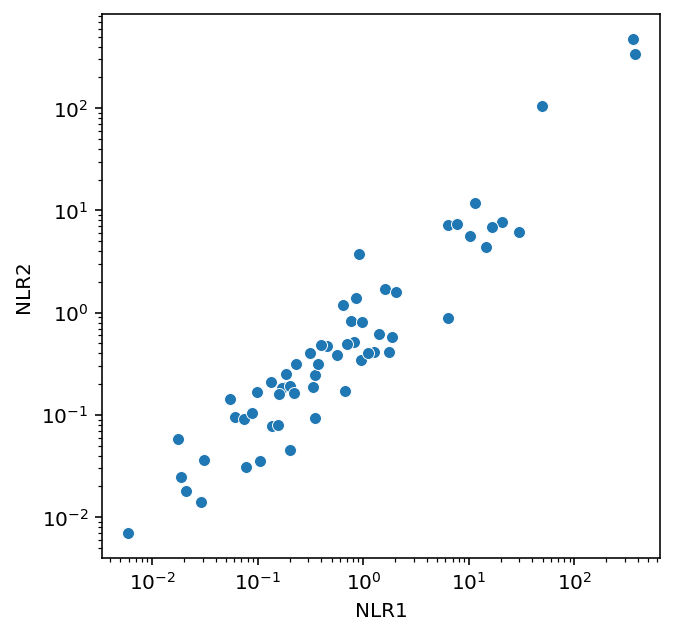

In [144]:
data1 = raw_sg_data[raw_sg_data.Category == 'PRS'].NLR1
data2 = raw_sg_data[raw_sg_data.Category == 'PRS'].NLR2

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLR1', y='NLR2', data=raw_sg_data[raw_sg_data.Category == 'PRS']);


plt.xlabel('NLR1')
plt.xscale('log')
plt.yscale('log')

plt.ylabel('NLR2')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

pearson (0.37464471307315705, 0.15279868671699415)
spearman SpearmanrResult(correlation=0.39999999999999997, pvalue=0.12475042359840012)


Text(0, 0.5, 'LuTHy')

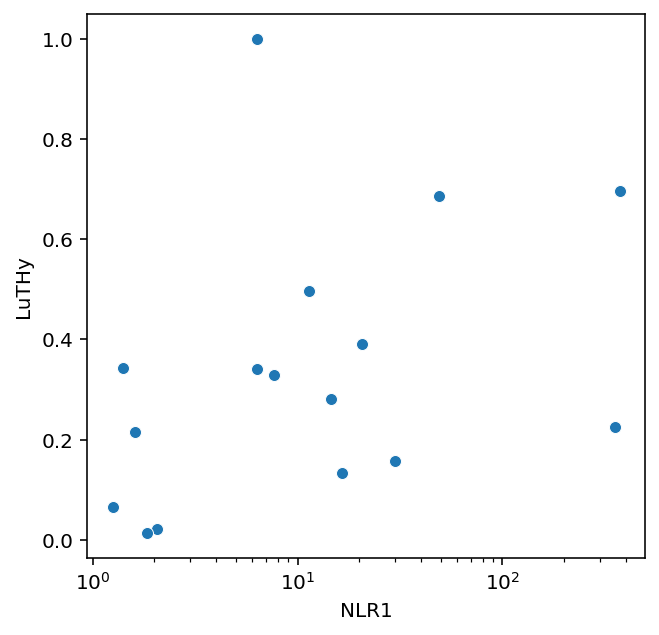

In [145]:
data1 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLR1 > 1)].NLR1.apply(np.log10)
data2 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLR1 > 1)].LuTHy

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLR1', y='LuTHy', data=raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLR1 > 1)]);


plt.xlabel('NLR1')
plt.xscale('log')
#plt.yscale('log')

plt.ylabel('LuTHy')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

pearson (0.4830809762114762, 0.06813369763521789)
spearman SpearmanrResult(correlation=0.7, pvalue=0.0036660678988013817)


Text(0, 0.5, 'LuTHy')

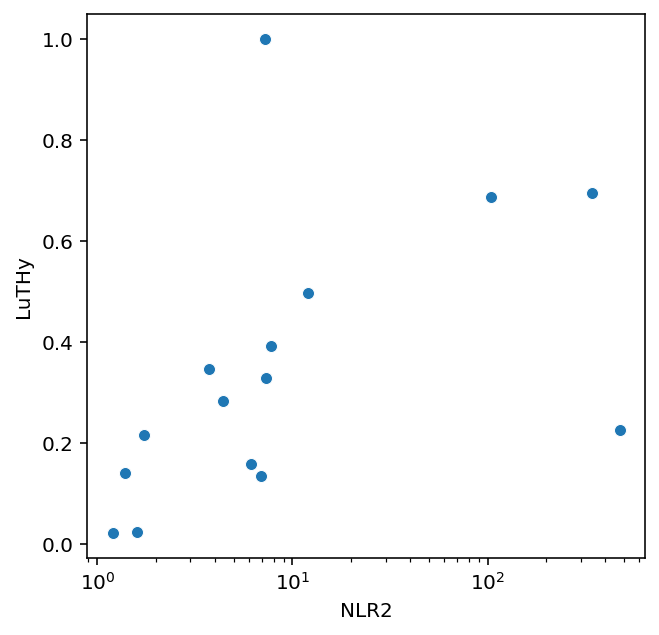

In [146]:
data1 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLR2 > 1)].NLR2.apply(np.log10)
data2 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLR2 > 1)].LuTHy

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLR2', y='LuTHy', data=raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLR2 > 1)]);


plt.xlabel('NLR2')
plt.xscale('log')
#plt.yscale('log')

plt.ylabel('LuTHy')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

pearson (0.41757624982526576, 0.07525483370832255)
spearman SpearmanrResult(correlation=0.32807017543859646, pvalue=0.17029675998814747)


Text(0, 0.5, 'LuTHy')

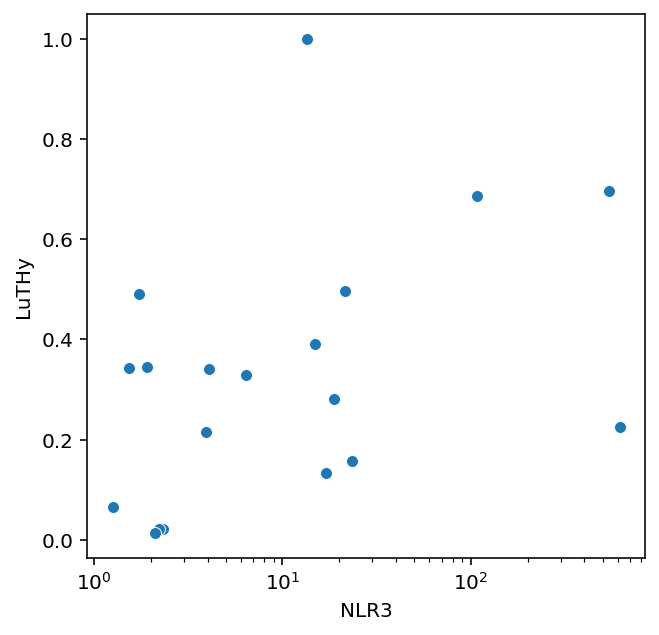

In [147]:
data1 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLR3 > 1)].NLR3.apply(np.log10)
data2 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLR3 > 1)].LuTHy

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLR3', y='LuTHy', data=raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLR3 > 1)]);


plt.xlabel('NLR3')
plt.xscale('log')
#plt.yscale('log')

plt.ylabel('LuTHy')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

pearson (0.4738646374032317, 0.06370505059788516)
spearman SpearmanrResult(correlation=0.4852941176470588, pvalue=0.05671771428191195)


Text(0, 0.5, 'LuTHy')

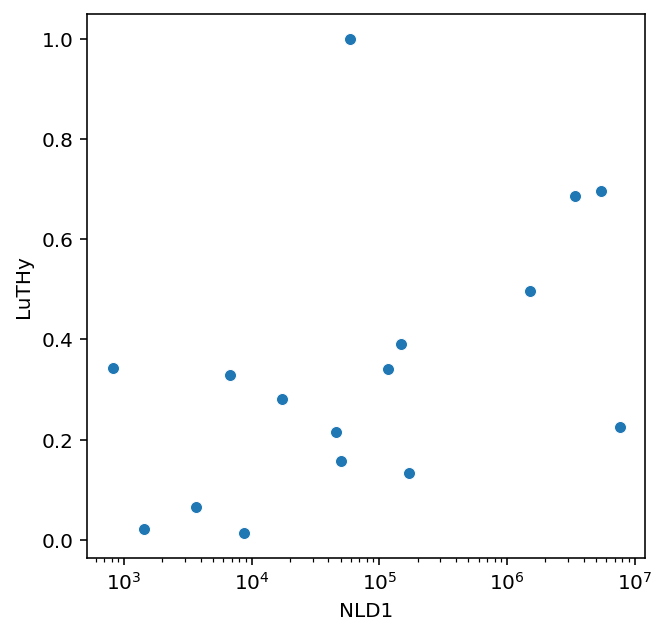

In [148]:
data1 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLD1 > 1)].NLD1.apply(np.log10)
data2 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLD1 > 1)].LuTHy

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLD1', y='LuTHy', data=raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLD1 > 1)]);


plt.xlabel('NLD1')
plt.xscale('log')
#plt.yscale('log')

plt.ylabel('LuTHy')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

pearson (0.5919889267652748, 0.020073759573757472)
spearman SpearmanrResult(correlation=0.7357142857142855, pvalue=0.0017698686421442707)


Text(0, 0.5, 'LuTHy')

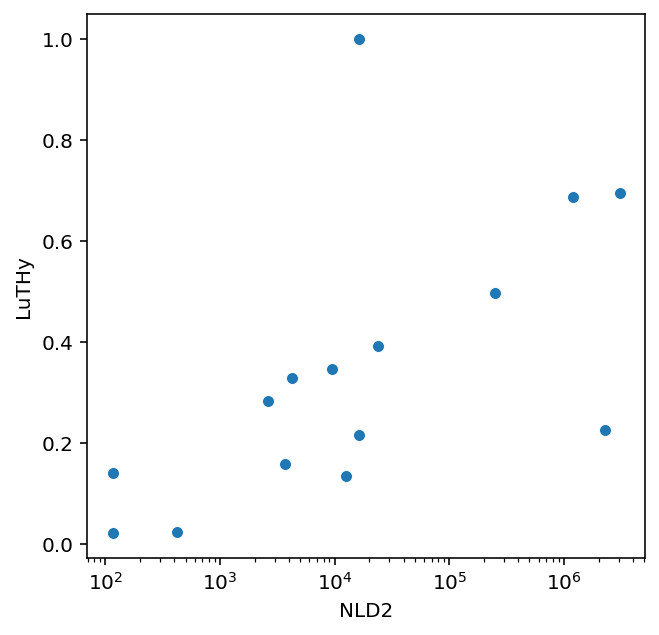

In [149]:
data1 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLD2 > 1)].NLD2.apply(np.log10)
data2 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLD2 > 1)].LuTHy

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLD2', y='LuTHy', data=raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLD2 > 1)]);


plt.xlabel('NLD2')
plt.xscale('log')
#plt.yscale('log')

plt.ylabel('LuTHy')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

pearson (0.4632079212533609, 0.04579233238213187)
spearman SpearmanrResult(correlation=0.4280701754385965, pvalue=0.0674881686246779)


Text(0, 0.5, 'LuTHy')

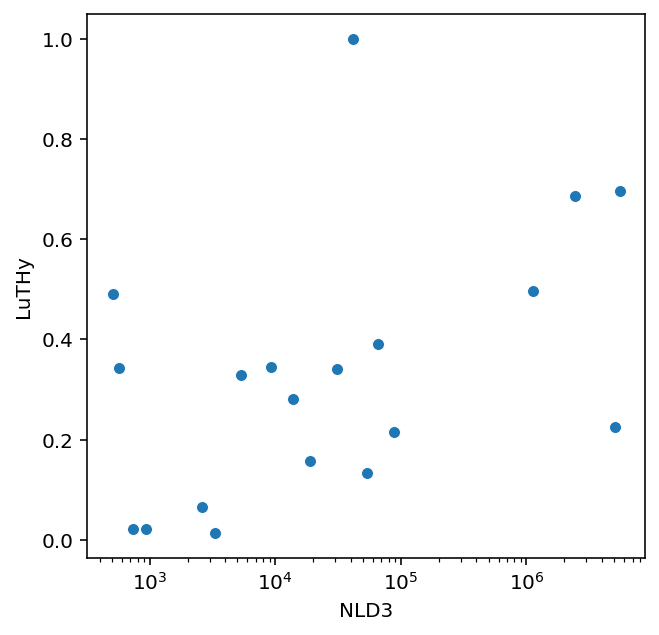

In [150]:
data1 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLD3 > 1)].NLD3.apply(np.log10)
data2 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLD3 > 1)].LuTHy

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(5,5))
sns.scatterplot(x='NLD3', y='LuTHy', data=raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data.NLD3 > 1)]);


plt.xlabel('NLD3')
plt.xscale('log')
#plt.yscale('log')

plt.ylabel('LuTHy')
#plt.savefig('../figures/scatterplot_corr_systdetect_LuTHys.pdf')

NLRA1
pearson (0.4584807977088706, 0.07407919132210274)
spearman SpearmanrResult(correlation=0.5676470588235295, pvalue=0.02181459214374292)
NLRA2
pearson (0.45700543729524357, 0.11641418500070501)
spearman SpearmanrResult(correlation=0.6263736263736264, pvalue=0.02198860240988966)
NLRA3
pearson (0.45670363478143566, 0.049338710945255694)
spearman SpearmanrResult(correlation=0.44912280701754387, pvalue=0.053731734799895854)
NLRP1
NLRP1 0
NLRP2
NLRP2 0
NLRP3
NLRP3 0
NLDA1
pearson (0.5016117057525971, 0.04774448017071959)
spearman SpearmanrResult(correlation=0.5352941176470588, pvalue=0.03261586329402191)
NLDA2
pearson (0.5091858559027247, 0.07553078193043725)
spearman SpearmanrResult(correlation=0.6318681318681317, pvalue=0.020516042572872463)
NLDA3
pearson (0.46079634649702994, 0.047083704799682775)
spearman SpearmanrResult(correlation=0.4280701754385965, pvalue=0.0674881686246779)
NLDP1
NLDP1 0
NLDP2
NLDP2 0
NLDP3
NLDP3 0


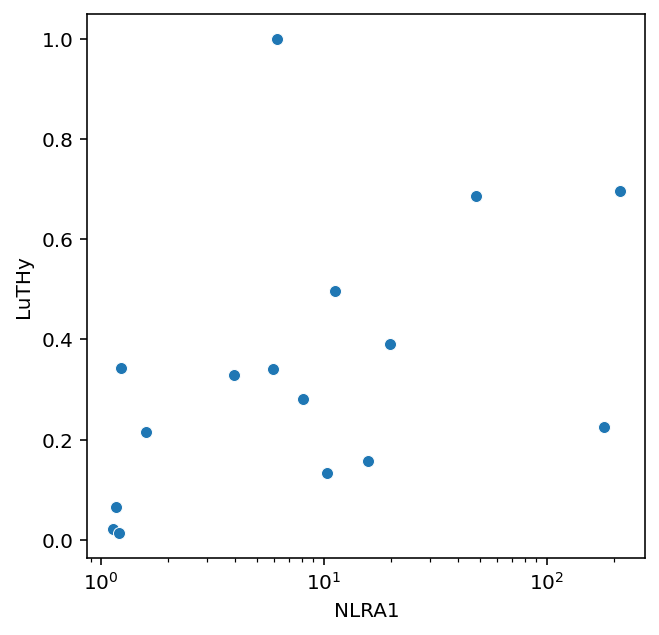

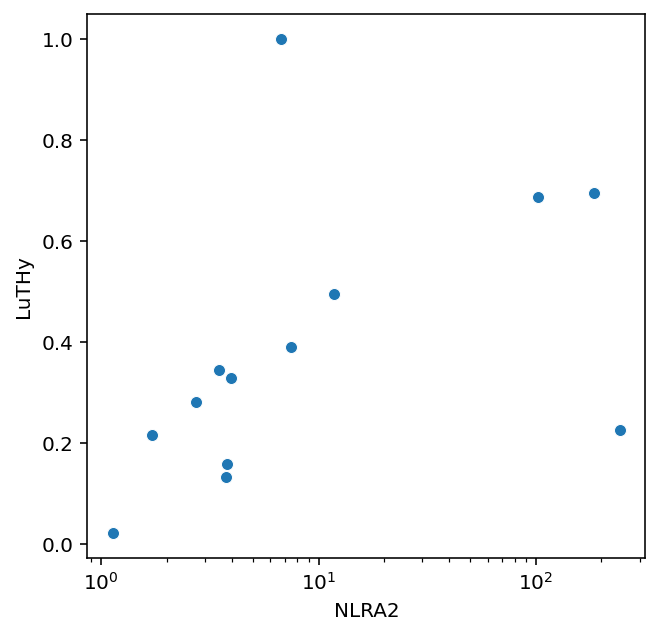

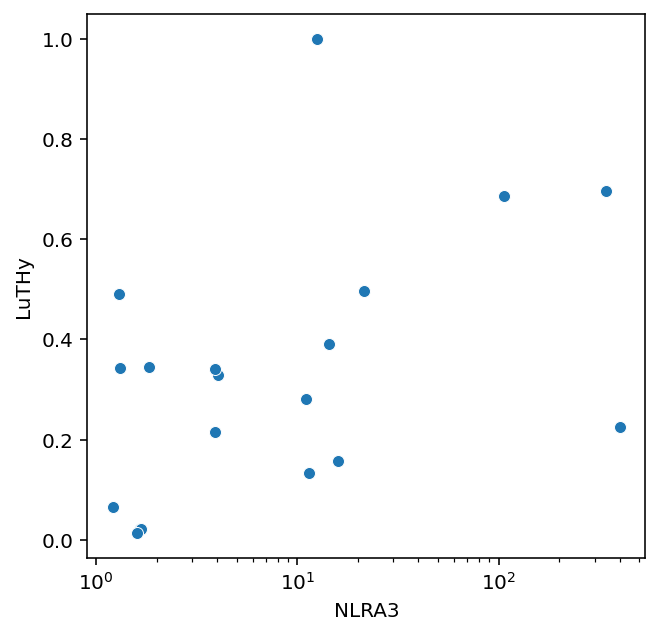

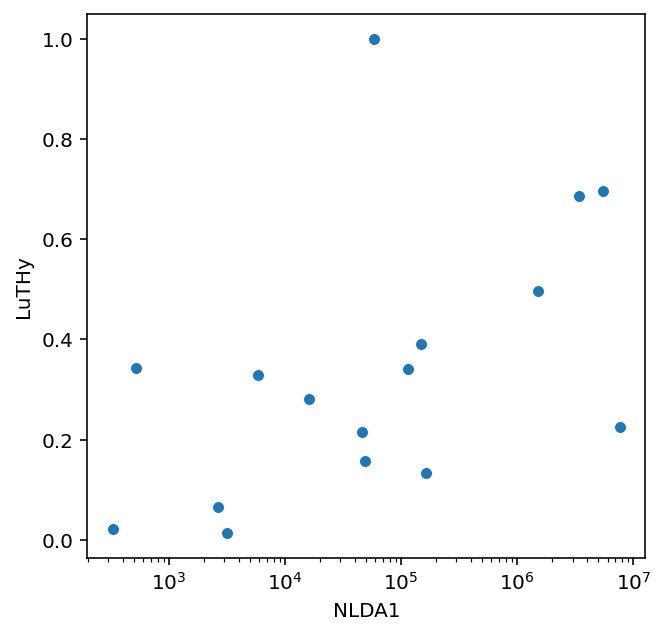

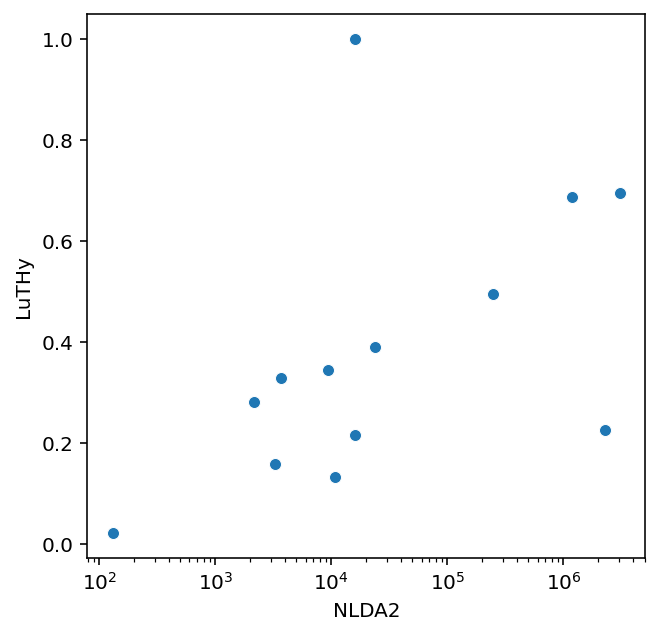

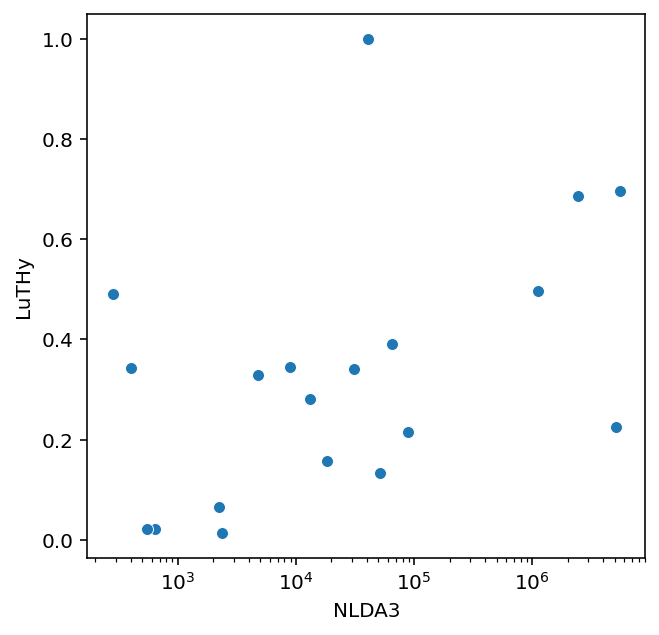

In [151]:
for xp in ['NLRA', 'NLRP', 'NLDA', 'NLDP']:
    for rep in ['1','2','3']:
        
        try:
            xp_rep = xp + rep
            print(xp_rep)

            data1 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data[xp_rep] > 1)][xp_rep].apply(np.log10)
            data2 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data[xp_rep] > 1)].LuTHy

            pearson_corr = pearsonr(data1, data2)
            spearman_corr = spearmanr(data1, data2)
            print('pearson',pearson_corr)
            print('spearman',spearman_corr)
            plt.figure(figsize=(5,5))
            sns.scatterplot(x=xp_rep, y='LuTHy', data=raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data[xp_rep] > 1)]);

            plt.xlabel(xp_rep)
            plt.xscale('log')
            plt.ylabel('LuTHy')
            
        except:
            print(xp_rep, len(raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.LuTHy > 0)&(raw_sg_data[xp_rep] > 1)]))


# qY2H integration

In [152]:
stop

NameError: name 'stop' is not defined

## PRS-RRS

In [ ]:
PRS_RRS_df = pd.read_csv('../../../MasterThesis_Gaspard/data/PRS_RRS.csv',sep='\t')
PRS_RRS_df.drop(columns=['Unnamed: 0','pair'],inplace=True)
PRS_RRS_df['pair'] = [tuple(sorted([ad,db])) for ad, db  in zip(PRS_RRS_df.ad_symbol, PRS_RRS_df.db_symbol)]
PRS_RRS_df.head()

In [ ]:
def calculate_score_cumulative(LW,LWH1,LWH10,LWH25,LWA,LWAH1,LW_ead,LWH1_ead,LWH10_ead,LWH25_ead,LWA_ead,LWAH1_ead):
    '''
    #1|all scores are normalized by LW level or NA if LW = 0 
    #2|NA if AA on most stringent detected level, otherwise normalized score
    #3|final score = sum of all processed GS
    '''
    res = np.nan
    
    ead_scores = [LWH1_ead,LWH10_ead,LWH25_ead,LWA_ead,LWAH1_ead]
    scores = [LWH1,LWH10,LWH25,LWA,LWAH1]
    
    if LW > 0 and LW_ead > 0: 
        
        scores = [s/LW for s in scores]
        ead_scores = [s/LW for s in ead_scores]
        
        aa = False
        for aa,s in zip(ead_scores[::-1], scores[::-1]):
            if aa >= s and aa > 0:
                res = np.nan
                aa = True
                break
            elif s > 0 and aa == 0:
                break
                
        if aa == False:

            scores = [s - ead_s for s,ead_s in zip(scores, ead_scores)]
            scores = [s for s in scores if s == s]

            res = sum(scores)/len(scores)

            if res < 0:
                res = 0
        
    return res

PRS_RRS_df['cum_score'] = [calculate_score_cumulative(LW,LWH1,LWH10,LWH25,LWA,LWAH1,LW_ead,LWH1_ead,LWH10_ead,LWH25_ead,LWA_ead,LWAH1_ead) for LW,LWH1,LWH10,LWH25,LWA,LWAH1,LW_ead,LWH1_ead,LWH10_ead,LWH25_ead,LWA_ead,LWAH1_ead in zip(PRS_RRS_df.LW,PRS_RRS_df.LWH1,PRS_RRS_df.LWH10,PRS_RRS_df.LWH25,PRS_RRS_df.LWA,PRS_RRS_df.LWAH1,PRS_RRS_df.LW_ead,PRS_RRS_df.LWH1_ead,PRS_RRS_df.LWH10_ead,PRS_RRS_df.LWH25_ead,PRS_RRS_df.LWA_ead,PRS_RRS_df.LWAH1_ead)]

PRS_RRS_df.head()

In [ ]:
xy_d = dict(zip(PRS_RRS_df[PRS_RRS_df.retest_pla.isin([1,3])].pair, PRS_RRS_df[PRS_RRS_df.retest_pla.isin([1,3])].cum_score))
yx_d = dict(zip(PRS_RRS_df[PRS_RRS_df.retest_pla.isin([2,4])].pair, PRS_RRS_df[PRS_RRS_df.retest_pla.isin([2,4])].cum_score))

PRS_RRS_cum_df = PRS_RRS_df[['pair','cat']].sort_values(by='cat').copy()
PRS_RRS_cum_df['xy'] = PRS_RRS_cum_df.pair.map(xy_d)
PRS_RRS_cum_df['yx'] = PRS_RRS_cum_df.pair.map(yx_d)

def calculate_mean(s1,s2):
    return np.mean([s for s in [s1,s2] if s == s and s > 0])

PRS_RRS_cum_df['score'] = [calculate_mean(xy,yx) for xy, yx in zip(PRS_RRS_cum_df.xy, PRS_RRS_cum_df.yx)]

PRS_RRS_cum_df[(PRS_RRS_cum_df.cat == 'PRS')&(PRS_RRS_cum_df.score > 0)].head()

In [ ]:
PRS_RRS_cum_d = dict(zip(PRS_RRS_cum_df.pair, PRS_RRS_cum_df.score))

In [ ]:
raw_sg_data['qY2H'] = raw_sg_data.pair.map(PRS_RRS_cum_d)
raw_sg_data.head()

In [ ]:
for col1 in ['avg_NLR','avg_NLD','avg_NLRA','avg_NLDA']:
    for col2 in ['LuTHy','qY2H']:
        data1 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data[col2] > 0)&(raw_sg_data[col1] > 1)][col1].apply(np.log10)
        data2 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data[col2] > 0)&(raw_sg_data[col1] > 1)][col2]

        pearson_corr = pearsonr(data1, data2)
        spearman_corr = spearmanr(data1, data2)
        print('pearson',pearson_corr)
        print('spearman',spearman_corr)
        plt.figure(figsize=(5,5))
        plt.title(f'{col1}')
        sns.scatterplot(x=col1, y=col2, data=raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data[col2] > 0)&(raw_sg_data[col1] > 1)]);


        plt.xlabel(col1)
        plt.xscale('log')
        #plt.yscale('log')

        plt.ylabel(col2)
        plt.show()
        #plt.savefig('../figures/scatterplot_corr_systdetect_qY2Hs.pdf')

In [ ]:
data1 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.qY2H > 0)&(raw_sg_data.LuTHy > 0)].LuTHy.fillna(0)
data2 = raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.qY2H > 0)&(raw_sg_data.LuTHy > 0)].qY2H.fillna(0)

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(5,5))
sns.scatterplot(x='qY2H', y='LuTHy', data=raw_sg_data[(raw_sg_data.Category == 'PRS')&(raw_sg_data.qY2H > 0)&(raw_sg_data.LuTHy > 0)]);


#plt.xlabel('LuTHy')
#plt.xscale('log')
#plt.yscale('log')

#plt.ylabel('qY2H')
#plt.savefig('../figures/scatterplot_corr_systdetect_qY2Hs.pdf')

## Allele pairwise  test

In [ ]:
col  = ['ad_orf_id', 'ad_symbol', 'db_orf_id',
       'db_symbol', 'db_mut_id', 'standard_batch', 'retest_pla', 'retest_pos', 'LW',
       'LWH1', 'LWH10', 'LWH25', 'LWA', 'LWAH1']

query = f'select {", ".join(c for c in col)} from vus.retest where standard_batch in ("VUSAPWT1B1", "VUSAPWT1B2", "VUSAPWT2B1", "VUSAPWT6B1");'

VUSAPWT_1B2_2B1_6B1 = GetDFv2(query, col)

df = VUSAPWT_1B2_2B1_6B1[(~VUSAPWT_1B2_2B1_6B1.db_orf_id.isnull())&(VUSAPWT_1B2_2B1_6B1.ad_orf_id == 0)&(VUSAPWT_1B2_2B1_6B1.LW >= 1)]

EAD_d = {(db_orf_id,db_mut_id,sb):{'LWH1':{}, 'LWH10':{}, 'LWH25':{},'LWA':{}, 'LWAH1':{}} for db_orf_id,db_mut_id,sb in  zip(df.db_orf_id, df.db_mut_id, df.standard_batch)}

for db_orf_id, db_mut_id, LW, LWH1, LWH10, LWH25, LWA, LWAH1,sb in zip(df.db_orf_id, df.db_mut_id, df.LW,df.LWH1,df.LWH10,df.LWH25, df.LWA, df.LWAH1, df.standard_batch):
    for media, score in zip(['LWH1', 'LWH10', 'LWH25', 'LWA', 'LWAH1'],[LWH1, LWH10, LWH25, LWA, LWAH1]):
        EAD_d[(db_orf_id,db_mut_id,sb)][media] = score


def get_final_score(score, ead_score, LW_score):
    res = np.nan
    
    if score == score and ead_score == ead_score and LW_score == LW_score:
        if LW_score > 0:
            if score == 0:
                res = score
            elif ead_score == 0:
                res = score
            else:
                res = score - ead_score if score - ead_score >= 2 else np.nan
            
    return res
        
        
for media in ['LWH1', 'LWH10', 'LWH25', 'LWA', 'LWAH1']:
    VUSAPWT_1B2_2B1_6B1[f'EAD_{media}'] = [EAD_d[(db_orf_id, db_mut_id,sb)][media] if (db_orf_id, db_mut_id,sb) in EAD_d else np.nan for db_orf_id, db_mut_id, sb in zip(VUSAPWT_1B2_2B1_6B1.db_orf_id, VUSAPWT_1B2_2B1_6B1.db_mut_id, VUSAPWT_1B2_2B1_6B1.standard_batch)]
    VUSAPWT_1B2_2B1_6B1[f'{media}_f'] = [get_final_score(score, ead_score,LW_score) for score, ead_score, LW_score in zip(VUSAPWT_1B2_2B1_6B1[media], VUSAPWT_1B2_2B1_6B1[f'EAD_{media}'], VUSAPWT_1B2_2B1_6B1.LW)]
    
VUSAPWT_1B2_2B1_6B1['sum_score'] = [sum([elem for elem in [a,b,c,d,e] if elem == elem ])/(len([elem for elem in [a,b,c,d,e] if elem == elem ])*4) if len([elem for elem in [a,b,c,d,e] if elem == elem ]) != 0 else np.nan for a,b,c,d,e in zip(VUSAPWT_1B2_2B1_6B1.LWH1_f , VUSAPWT_1B2_2B1_6B1.LWH10_f , VUSAPWT_1B2_2B1_6B1.LWH25_f , VUSAPWT_1B2_2B1_6B1.LWA_f,  VUSAPWT_1B2_2B1_6B1.LWAH1_f)]

VUSAPWT_1B2_2B1_6B1['prod_score'] = [np.prod([elem for elem in [a,b,c,d,e] if elem == elem  and elem > 0]) if len([elem for elem in [a,b,c,d,e] if elem == elem ]) != 0 else np.nan for a,b,c,d,e in zip(VUSAPWT_1B2_2B1_6B1.LWH1_f , VUSAPWT_1B2_2B1_6B1.LWH10_f , VUSAPWT_1B2_2B1_6B1.LWH25_f , VUSAPWT_1B2_2B1_6B1.LWA_f,  VUSAPWT_1B2_2B1_6B1.LWAH1_f)]

VUSAPWT_1B2_2B1_6B1 = VUSAPWT_1B2_2B1_6B1[(VUSAPWT_1B2_2B1_6B1.db_mut_id >= 0)&(VUSAPWT_1B2_2B1_6B1.ad_orf_id != 0)].copy()

qY2H_d = {(db_orf_id, db_mut_id, ad_orf_id):score for db_orf_id,db_mut_id,ad_orf_id,score in zip(VUSAPWT_1B2_2B1_6B1.db_orf_id,
                                                                                                 VUSAPWT_1B2_2B1_6B1.db_mut_id,
                                                                                                 VUSAPWT_1B2_2B1_6B1.ad_orf_id,
                                                                                                 VUSAPWT_1B2_2B1_6B1.sum_score)}

qY2H_prod_d = {(db_orf_id, db_mut_id, ad_orf_id):score for db_orf_id,db_mut_id,ad_orf_id,score in zip(VUSAPWT_1B2_2B1_6B1.db_orf_id,
                                                                                                 VUSAPWT_1B2_2B1_6B1.db_mut_id,
                                                                                                 VUSAPWT_1B2_2B1_6B1.ad_orf_id,
                                                                                                 VUSAPWT_1B2_2B1_6B1.prod_score)}

VUSAPWT_1B2_2B1_6B1.head()

In [ ]:
yN2H_normalized['qY2H'] = [qY2H_d[(db_orf_id, mut_id, ad_orf_id)] if (db_orf_id, mut_id, ad_orf_id) in qY2H_d else np.nan for db_orf_id, mut_id, ad_orf_id in zip(yN2H_normalized.db_orf_id, yN2H_normalized.db_mut_id, yN2H_normalized.ad_orf_id)]
yN2H_normalized['qY2H_prod'] = [qY2H_prod_d[(db_orf_id, mut_id, ad_orf_id)] if (db_orf_id, mut_id, ad_orf_id) in qY2H_prod_d else np.nan for db_orf_id, mut_id, ad_orf_id in zip(yN2H_normalized.db_orf_id, yN2H_normalized.db_mut_id, yN2H_normalized.ad_orf_id)]
yN2H_normalized.head()

In [ ]:
raw_sg_data.columns

In [ ]:
yN2H_normalized['NLRA1'] = [s/(en1+en2) for s, en1, en2 in zip(yN2H_normalized.yN2H_score_rep1, yN2H_normalized.empty_N1_rep1, yN2H_normalized.empty_N2_rep1)]
yN2H_normalized['NLRA2'] = [s/(en1+en2) for s, en1, en2 in zip(yN2H_normalized.yN2H_score_rep2, yN2H_normalized.empty_N1_rep2, yN2H_normalized.empty_N2_rep2)]
yN2H_normalized['NLDA1'] = [s-(en1+en2) for s, en1, en2 in zip(yN2H_normalized.yN2H_score_rep1, yN2H_normalized.empty_N1_rep1, yN2H_normalized.empty_N2_rep1)]
yN2H_normalized['NLDA2'] = [s-(en1+en2) for s, en1, en2 in zip(yN2H_normalized.yN2H_score_rep2, yN2H_normalized.empty_N1_rep2, yN2H_normalized.empty_N2_rep2)]

yN2H_normalized['avg_NLR'] = yN2H_normalized.NLR
yN2H_normalized['avg_NLD'] = yN2H_normalized.NLD
yN2H_normalized['avg_NLRA'] = [np.mean([NLRA1,NLRA2]) for NLRA1,NLRA2 in zip(yN2H_normalized.NLRA1, yN2H_normalized.NLRA2)]
yN2H_normalized['avg_NLDA'] = [np.mean([NLDA1,NLDA2]) for NLDA1,NLDA2 in zip(yN2H_normalized.NLDA1, yN2H_normalized.NLDA2)]


### WT correlation with qY2H

In [ ]:
yN2H_normalized.variant_id.value_counts()

In [ ]:
yN2H_normalized[yN2H_normalized.variant_id == 'wt'].head()

In [ ]:
for col1 in ['avg_NLR','avg_NLD','avg_NLRA','avg_NLDA']:
    for col2 in ['qY2H','qY2H_prod']:
        data1 = yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&(yN2H_normalized[col2] > 0)&(yN2H_normalized[col1] > 1)][col1].apply(np.log10)
        data2 = yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&(yN2H_normalized[col2] > 0)&(yN2H_normalized[col1] > 1)][col2]

        pearson_corr = pearsonr(data1, data2)
        spearman_corr = spearmanr(data1, data2)
        print('pearson',pearson_corr)
        print('spearman',spearman_corr)
        plt.figure(figsize=(5,5))
        plt.title(f'{col1}')
        sns.scatterplot(x=col1, y=col2, data=yN2H_normalized[(yN2H_normalized.variant_id == 'wt')&(yN2H_normalized[col2] > 0)&(yN2H_normalized[col1] > 1)]);


        plt.xlabel(col1)
        plt.xscale('log')
        
        if col2  == 'qY2H_prod':
            plt.yscale('log')

        plt.ylabel(col2)
        plt.show()
        #plt.savefig('../figures/scatterplot_corr_systdetect_qY2Hs.pdf')

# Analysis

## PRS / wt pair & RRS detection rate 

In [ ]:
yN2H_wt_normalized.variant_id.value_counts()
yN2H_wt_normalized['variant_idv2'] = yN2H_wt_normalized.variant_id.apply(lambda x: x if x != 'litbm' else 'wt')
yN2H_wt_normalized.variant_idv2.value_counts()

In [ ]:
yN2H_wt_normalized.variant_id.value_counts()

In [ ]:
yN2H_wt_normalized.head()

In [ ]:
n_RRS = len(sorted(yN2H_wt_normalized[yN2H_wt_normalized.variant_id == 'RRS'].NLR.tolist()))
RRS_rate_d = {i+1:val for i, val in enumerate(sorted(yN2H_wt_normalized[yN2H_wt_normalized.variant_id == 'RRS'].NLR.tolist(),reverse=True))}

tot_wt = ((yN2H_wt_normalized.variant_idv2 == 'wt') &(~yN2H_wt_normalized.NLR.isnull())).sum()
tot_prs = ((yN2H_wt_normalized.variant_idv2 == 'PRS') &(~yN2H_wt_normalized.NLR.isnull())).sum()

res = []
for n_rrs in RRS_rate_d:
    
    n_wt_detected = ((yN2H_wt_normalized.variant_idv2 == 'wt')&(yN2H_wt_normalized.NLR > RRS_rate_d[n_rrs])).sum()
    n_prs_detected = ((yN2H_wt_normalized.variant_idv2 == 'PRS')&(yN2H_wt_normalized.NLR > RRS_rate_d[n_rrs])).sum()   
    rrs_rate =  (n_rrs-1)/78
    
    #print(n_rrs, (n_rrs-1)/78, n_detected, n_detected/((yN2H_wt_normalized.variant_idv2 == variant_id) &(~yN2H_wt_normalized.NLR.isnull())).sum())
    
    res.append([n_rrs-1, rrs_rate, n_wt_detected, n_wt_detected/tot_wt, n_prs_detected, n_prs_detected/tot_prs])
    
    
detection_df = pd.DataFrame(res, columns=['n_rrs', 'rrs_rate', 'n_wt', 'frac_wt', 'n_PRS', 'frac_PRS'])


#sns.lineplot(data=detection_df[detection_df.n_rrs <= 8], y="frac_wt", x="rrs_rate", legend=True)
#sns.lineplot(data=detection_df[detection_df.n_rrs <= 8], y="frac_PRS", x="rrs_rate")

plt.figure(figsize=(4,4))

plt.title('NLR detection rates')
plt.plot(detection_df[detection_df.n_rrs <= 8].rrs_rate.apply(lambda x: x*100), detection_df[detection_df.n_rrs <= 8].frac_wt.apply(lambda x: x*100), label = "WT pairs", color='olivedrab') 
plt.plot(detection_df[detection_df.n_rrs <= 8].rrs_rate.apply(lambda x: x*100), detection_df[detection_df.n_rrs <= 8].frac_PRS.apply(lambda x: x*100), label = "PRS pairs", color='slateblue') 
plt.legend()
plt.axvline((3/78)*100, 0,1, color='lightgrey', linestyle='--')
plt.xlabel('Fraction of RRS pairs recovered (%)')
plt.ylabel('Fraction of pairs recovered (%)')
plt.ylim((0,45))
plt.savefig('RRS_NLR_detection_thresholds.pdf')
plt.savefig('RRS_NLR_detection_thresholds.png',dpi=300)
plt.show()

In [ ]:
n_RRS = len(sorted(yN2H_wt_normalized[yN2H_wt_normalized.variant_id == 'RRS'].NLD.tolist()))
RRS_rate_d = {i+1:val for i, val in enumerate(sorted(yN2H_wt_normalized[yN2H_wt_normalized.variant_id == 'RRS'].NLD.tolist(),reverse=True))}

tot_wt = ((yN2H_wt_normalized.variant_idv2 == 'wt') &(~yN2H_wt_normalized.NLD.isnull())).sum()
tot_prs = ((yN2H_wt_normalized.variant_idv2 == 'PRS') &(~yN2H_wt_normalized.NLD.isnull())).sum()

res = []
for n_rrs in RRS_rate_d:
    
    n_wt_detected = ((yN2H_wt_normalized.variant_idv2 == 'wt')&(yN2H_wt_normalized.NLD > RRS_rate_d[n_rrs])).sum()
    n_prs_detected = ((yN2H_wt_normalized.variant_idv2 == 'PRS')&(yN2H_wt_normalized.NLD > RRS_rate_d[n_rrs])).sum()   
    rrs_rate =  (n_rrs-1)/78
    
    #print(n_rrs, (n_rrs-1)/78, n_detected, n_detected/((yN2H_wt_normalized.variant_idv2 == variant_id) &(~yN2H_wt_normalized.NLD.isnull())).sum())
    
    res.append([n_rrs-1, rrs_rate, n_wt_detected, n_wt_detected/tot_wt, n_prs_detected, n_prs_detected/tot_prs])
    
    
detection_df = pd.DataFrame(res, columns=['n_rrs', 'rrs_rate', 'n_wt', 'frac_wt', 'n_PRS', 'frac_PRS'])


#sns.lineplot(data=detection_df[detection_df.n_rrs <= 8], y="frac_wt", x="rrs_rate", legend=True)
#sns.lineplot(data=detection_df[detection_df.n_rrs <= 8], y="frac_PRS", x="rrs_rate")

plt.figure(figsize=(4,4))

plt.title('NLD detection rates')
plt.plot(detection_df[detection_df.n_rrs <= 8].rrs_rate.apply(lambda x: x*100), detection_df[detection_df.n_rrs <= 8].frac_wt.apply(lambda x: x*100), label = "WT pairs", color='olivedrab') 
plt.plot(detection_df[detection_df.n_rrs <= 8].rrs_rate.apply(lambda x: x*100), detection_df[detection_df.n_rrs <= 8].frac_PRS.apply(lambda x: x*100), label = "PRS pairs", color='slateblue') 
plt.legend()
plt.axvline((3/78)*100, 0,1, color='lightgrey', linestyle='--')
plt.xlabel('Fraction of RRS pairs recovered (%)')
plt.ylabel('Fraction of pairs recovered (%)')
plt.ylim((0,45))
plt.savefig('RRS_NLD_detection_thresholds.pdf')
plt.savefig('RRS_NLD_detection_thresholds.png',dpi=300)
plt.show()

In [ ]:
data1 = yN2H_normalized[(yN2H_normalized.variant_id.isin(['PRS','RRS']))&(~yN2H_normalized.NLR.isnull())].wtpwt_nlr
data2 = yN2H_normalized[(yN2H_normalized.variant_id.isin(['PRS','RRS']))&(~yN2H_normalized.NLR.isnull())].NLR

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

sns.jointplot(data=yN2H_normalized[(yN2H_normalized.variant_id.isin(['PRS','RRS']))&(~yN2H_normalized.NLR.isnull())], x='wtpwt_nlr', y='NLR', hue='variant_id')

In [ ]:
yN2H_normalized['pair'] = [tuple(sorted([ad,db])) for ad, db in zip(yN2H_normalized.ad_orf_id, yN2H_normalized.db_orf_id)]
yN2H_normalized.head()

In [ ]:
venn2([set(yN2H_normalized[yN2H_normalized.wtpwt_nlr > 0].pair),set(yN2H_normalized[yN2H_normalized.NLR > 0].pair)],
      ['wtpwt_nlr','apwt']
     )

## WT pwt correlation

In [ ]:
yN2H_normalized[yN2H_normalized.db_mut_id == 0].head()

In [ ]:
yN2H_normalized.head()

In [ ]:
data1 = yN2H_normalized[(yN2H_normalized.db_mut_id == 0)&(~yN2H_normalized.NLR.isnull())].wtpwt_nlr
data2 = yN2H_normalized[(yN2H_normalized.db_mut_id == 0)&(~yN2H_normalized.NLR.isnull())].NLR

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

sns.jointplot(data=yN2H_normalized[(yN2H_normalized.db_mut_id == 0)&(~yN2H_normalized.NLR.isnull())], x='wtpwt_nlr', y='NLR', hue='detected_r1')


In [ ]:
yN2H_normalized[(~yN2H_normalized.NLR.isnull())&(yN2H_normalized.db_mut_id.isnull())]

In [ ]:
data1 = yN2H_normalized[(yN2H_normalized.variant_id != 'allele')&(~yN2H_normalized.NLR.isnull())].wtpwt_nlr
data2 = yN2H_normalized[(yN2H_normalized.variant_id != 'allele')&(~yN2H_normalized.NLR.isnull())].NLR

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)
plt.figure(figsize=(6,6))
ax = sns.scatterplot(data=yN2H_normalized[(yN2H_normalized.variant_id != 'allele')&(~yN2H_normalized.NLR.isnull())], x='wtpwt_nlr', y='NLR', hue='variant_id');


plt.ylabel('NLR - allele pairwise test')
plt.xlabel('NLR - WT pairwise test')


In [ ]:
data1 = yN2H_normalized[(yN2H_normalized.db_mut_id == 0)&(~yN2H_normalized.NLR.isnull())].wtpwt_nld
data2 = yN2H_normalized[(yN2H_normalized.db_mut_id == 0)&(~yN2H_normalized.NLR.isnull())].NLD

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

sns.jointplot(data=yN2H_normalized[(yN2H_normalized.db_mut_id == 0)&(~yN2H_normalized.NLR.isnull())], x='wtpwt_nld', y='NLD', hue='detected_NLD1')

In [ ]:
data1 = yN2H_normalized[(yN2H_normalized.db_mut_id == 0)&(~yN2H_normalized.NLR.isnull())].empty_N2_rep2
data2 = yN2H_normalized[(yN2H_normalized.db_mut_id == 0)&(~yN2H_normalized.NLR.isnull())].wtpwt_en2_raw

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

sns.jointplot(data=yN2H_normalized[(yN2H_normalized.db_mut_id == 0)&(~yN2H_normalized.NLR.isnull())], x='empty_N2_rep2', y='wtpwt_en2_raw', hue='detected_NLD1')



## correlation  qY2H yN2H

### overall

In [ ]:
data1 = yN2H_normalized[(~yN2H_normalized.qY2H.isnull())&(yN2H_normalized.NLD1 > 0)].qY2H
data2 = yN2H_normalized[(~yN2H_normalized.qY2H.isnull())&(yN2H_normalized.NLD1 > 0)].NLD

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

sns.jointplot(data=yN2H_normalized[(~yN2H_normalized.qY2H.isnull())&(~yN2H_normalized.NLD1.isnull())], x='qY2H', y='NLD1')

In [ ]:
sns.jointplot(data=yN2H_normalized[(~yN2H_normalized.qY2H.isnull())&(~yN2H_normalized.NLD1.isnull())&(yN2H_normalized.variant_id == 'wt')], x='qY2H', y='NLD1')

In [ ]:
sns.barplot(data=yN2H_normalized[yN2H_normalized.variant_id.isin(['allele','wt'])], y='qY2H', x='variant_id', hue='detected_r2')

In [ ]:
sns.violinplot(data=yN2H_normalized[yN2H_normalized.variant_id.isin(['allele','wt'])], y='qY2H', x='variant_id', hue='detected_r2')

#  new analysis October  2021

## PRS-RRS

In [ ]:
first_prs.head()

In [ ]:
yN2H_normalized[yN2H_normalized.variant_id.isin(['PRS','RRS'])].head()

# edgetic impact - WT difference

In [ ]:
edg_df = yN2H_normalized[(yN2H_normalized.db_mut_id > 0) & (yN2H_normalized.db_mut_id < 999999)].copy()

edg_df['wt_qY2H'] = [qY2H_d[(db,0,ad)] if (db,0,ad) in qY2H_d else np.nan for db, ad in zip(edg_df.db_orf_id, edg_df.ad_orf_id)]

wt_yN2H_d = {(db,ad):{'NLR1':NLR1,'NLR2':NLR2,'NLD1':NLD1,'NLD2':NLD2, 'detected_r1':detected_r1,'detected_r2':detected_r2,'detected_NLD1':detected_NLD1,'detected_NLD2':detected_NLD2} for ad,db,NLR1,NLR2,NLD1,NLD2,detected_r1,detected_r2,detected_NLD1,detected_NLD2 in zip(yN2H_normalized[yN2H_normalized.db_mut_id == 0].ad_orf_id,yN2H_normalized[yN2H_normalized.db_mut_id == 0].db_orf_id,yN2H_normalized[yN2H_normalized.db_mut_id == 0].NLR1,yN2H_normalized[yN2H_normalized.db_mut_id == 0].NLR2,yN2H_normalized[yN2H_normalized.db_mut_id == 0].NLD1,yN2H_normalized[yN2H_normalized.db_mut_id == 0].NLD2,yN2H_normalized[yN2H_normalized.db_mut_id == 0].detected_r1,yN2H_normalized[yN2H_normalized.db_mut_id == 0].detected_r2,yN2H_normalized[yN2H_normalized.db_mut_id == 0].detected_NLD1,yN2H_normalized[yN2H_normalized.db_mut_id == 0].detected_NLD2,)}

for key in ['NLR1','NLR2','NLD1','NLD2','detected_r1','detected_r2','detected_NLD1','detected_NLD2']:
    edg_df[f'wt_{key}'] = [wt_yN2H_d[(db,ad)][key] for db, ad in zip(edg_df.db_orf_id, edg_df.ad_orf_id)]
    
edg_df['qY2H_MS'] = [(allele-wt)/(wt) if allele == allele and wt == wt and wt != 0 else np.nan for allele, wt in zip(edg_df.qY2H, edg_df.wt_qY2H)]
edg_df['yN2H_MS'] = [(allele-wt)/(wt) if allele == allele and wt == wt and wt != 0 else np.nan for allele, wt in zip(edg_df.NLD1, edg_df.wt_NLD1)]
#edg_df['qY2H_MS_cat'] = edg_df.qY2H_MS.apply(lambda x: x < qY2H_MS_cat.)

edg_df.head()

In [ ]:
path = '../../../meetings_presentations_abstracts/Edgotyping_meeting_slides/figures/20210306_'
edg_df.qY2H_MS.plot.hist(bins=40)
plt.xlabel('qY2H Molecular Score')
plt.ylabel('Count')
plt.savefig(f'../../../meetings_presentations_abstracts/Edgotyping_meeting_slides/figures/20210306_qY2H_MS_distribution.png')

In [ ]:
edg_df.yN2H_MS.plot.hist(bins=40)
plt.xlabel('yN2H Molecular Score')
plt.ylabel('Count')

In [ ]:
edg_df[(edg_df.qY2H_MS > 1)&(~edg_df.yN2H_MS.isnull())]

In [ ]:
edg_df[(edg_df.yN2H_MS > 1)]

In [ ]:
data1 = edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.qY2H_MS > 1) & (edg_df.yN2H_MS > 1)].qY2H_MS
data2 = edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.qY2H_MS > 1) & (edg_df.yN2H_MS > 1)].yN2H_MS

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

sns.jointplot(data=edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.qY2H_MS > 1) & (edg_df.yN2H_MS > 1)], x='qY2H_MS', y='yN2H_MS',alpha=0.1)

In [ ]:
data1 = edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())].qY2H_MS
data2 = edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())].yN2H_MS

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

sns.jointplot(data=edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())], x='qY2H_MS', y='yN2H_MS',alpha=0.1)

In [ ]:
data1 = edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  == 'STXBP1')].qY2H_MS
data2 = edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  == 'STXBP1')].yN2H_MS

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

sns.jointplot(data=edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  ==  'STXBP1')], x='qY2H_MS', y='yN2H_MS')

In [ ]:
data1 = edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  == 'MLH1')].qY2H_MS
data2 = edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  == 'MLH1')].yN2H_MS

pearson_corr = pearsonr(data1, data2)
spearman_corr = spearmanr(data1, data2)
print('pearson',pearson_corr)
print('spearman',spearman_corr)

sns.jointplot(data=edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  ==  'MLH1')], x='qY2H_MS', y='yN2H_MS')

In [ ]:
pearson_corr

In [ ]:
for gene in edg_df.db_symbol.unique():

    data1 = edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  == gene)].qY2H_MS
    data2 = edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  == gene)].yN2H_MS
    
    if len(data1) >= 2 and len(data2) >= 2 and len(edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  == gene)]) > 2:

        pearson_corr = pearsonr(data1, data2)
        spearman_corr = spearmanr(data1, data2)
        
        if pearson_corr[1] <= 0.05:# or spearman_corr[1] <= 0.05:

            print(gene)
            print('pearson',pearson_corr)
            print('spearman',spearman_corr)
            print()

In [ ]:
data1 = edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  == 'AP2S1')].qY2H_MS
data2 = edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  == 'AP2S1')].yN2H_MS

In [ ]:
data1, data2

In [ ]:
edg_df[edg_df.db_symbol == 'AP2S1'].head()

In [ ]:
edg_df[edg_df.db_symbol == 'POLR1C'].head()

In [ ]:
edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  == 'POLR1C')]

In [ ]:
edg_df[(~edg_df.qY2H_MS.isnull())&(~edg_df.yN2H_MS.isnull())&(edg_df.db_symbol  == 'NAA10')]

# retests

In [ ]:
yN2H_normalized.head()

In [ ]:
sns.barplot(y='NLR1',x='variant_id',data=yN2H_normalized)

In [ ]:
#plt.figure(figsize=(20,10))
sns.barplot(y='NLD1',x='variant_id',data=yN2H_normalized[yN2H_normalized.NLD1>0])

In [ ]:
yN2H_normalized[yN2H_normalized.NLD1 > 0].variant_id.value_counts()

In [ ]:
yN2H_normalized[yN2H_normalized.NLD2 > 0].variant_id.value_counts()

In [ ]:
yN2H_normalized.variant_id.value_counts()

In [ ]:
sns.barplot(y='detected_r1',x='variant_id',data=yN2H_normalized[yN2H_normalized.empty_well_rep1==False])

In [ ]:
yN2H_normalized[yN2H_normalized.detected_r1 == True].variant_id.value_counts()

In [ ]:
yN2H_normalized[yN2H_normalized.detected_r2 == True].variant_id.value_counts()

# export table

In [ ]:
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id', 'db_symbol', 'db_mut_id','variant_id',
       'yN2H_score_rep1', 'yN2H_score_rep2', 'empty_N1_rep1', 'empty_N2_rep1',
       'empty_N1_rep2', 'empty_N2_rep2', 'NLR1', 'NLR2', 'NLD1', 'NLD2',
       'detected_r1', 'detected_r2', 'detected_NLD1', 'detected_NLD2',
       'qY2H', 'wt_qY2H', 'wt_NLR1', 'wt_NLR2', 'wt_NLD1', 'wt_NLD2',
       'wt_detected_r1', 'wt_detected_r2', 'wt_detected_NLD1',
       'wt_detected_NLD2', 'qY2H_MS', 'yN2H_MS']

In [ ]:
edg_df[(edg_df.empty_well_rep1 == False)& 
                (edg_df.empty_well_rep2 ==False)
               ][col].to_csv('qY2H_yN2H_table.csv')

In [ ]:
edg_df[(edg_df.empty_well_rep1 == False)& 
                (edg_df.empty_well_rep2 ==False)
               ][col].head()